# Data Cleaning: CU-BEMS Smart Building Dataset

**Goal:** turn the raw CU-BEMS sensor files into a clean, documented dataset that later analyses (peak demand, comfort, energy use) can trust.

**Data:** 14 CSV files with one reading per minute for 7 floors of an office building in Bangkok, from July 2018 to December 2019. They record:

- **Power (kW):** air-conditioning (AC), lighting and plug loads
- **Indoor environment:** temperature, humidity and light level (lux)

**Method:** the notebook follows six steps:

| Step | Question it answers |
|---|---|
| 1. Explore | What does the data look like? Types, formats, ranges and obvious problems |
| 2. Plan | How do we split up the data, and which chart reveals which kind of problem? |
| 3. Plot | Where are the anomalies and missing values? |
| 4. Recommend | What should be done about each problem, and why? |
| 5. Clean | Apply those actions |
| 6. Re-plot | Did it work? What still remains, and why? |

Three closing sections follow:

- **7. Export** saves the cleaned data.
- **8. Assumptions and limitations** lists every assumption made.
- **9. Before vs after** puts every chart side by side.

**How to read this notebook:** each step follows the same pattern: *what we are checking* → a short code cell → *what the result shows*. The longer helper code (plotting functions and so on) is collected in **Section 0** so it doesn't interrupt the story. You can skip Section 0 and still follow every step.

**Principles applied throughout:**

- **Six ways sensor data goes wrong:** missing, stale, noisy, misaligned, wrong context and too much data. Step 2 maps each one to the check that tests for it.
- **Bad data vs unusual operation:** *bad data* is cleaned or flagged, while *unusual but real operation*, such as a day the building was closed, is investigated and kept. Not every unusual row is bad.
- **Plausibility rules:** each measurement has a physically possible range.
- **Cleaning is never hidden:** every removed reading is logged with its reason, and every assumption is listed in Section 8.

## Summary of all fixes

Every problem the cleaning found, and what was done about it. The figures are from the latest run of this notebook, and the last column points to the section with the details and evidence.

| Problem found | Where | What the cleaning did | How much | Details |
|---|---|---|---|---|
| Dates written day-first (`D/M/YY H:MM`) | 2019 Floor 7 | Parsed day-first; every file rewritten as `YYYY-MM-DD HH:MM:SS` | 525,600 rows; none lost | 1.4, 3.1 |
| File cut off on 22 Oct 2019, ending in a broken row | 2019 Floor 6 | Broken row dropped; the missing period (22 Oct 13:28 - 31 Dec) added as **blank** rows, **not** filled; noted in `data_quality.csv` | 101,432 minutes (~70 days) | 1.4, 1.5, 6.8 |
| Minutes missing from the timeline | All files | Every floor put on a complete 1-minute timeline so gaps are visible | 790,560 minutes per floor | 1.5 |
| Short gaps (15 minutes or less) | All floors | Filled by linear interpolation | 202,184 gaps; 444,484 minutes (0.3% of readings) | 3.3, 4.3 B, 5 |
| Long gaps and outages (over 15 minutes) | e.g. all sensors Sep 2018 - Mar 2019; Floors 3 and 4 Oct-Nov 2018; Floor 6 from 22 Oct 2019 | **Left blank** and documented, never invented | 17,491 gaps remain | 3.2, 6.8 |
| Power spikes (most likely logger bursts) | 50 meters, about two-thirds on Floor 3 | Removed, refilled by interpolation, each one logged in `removed_readings.csv` | 450 readings | 3.4-3.5, 4.3 A, 5 |
| Implausible temperatures (below 15 °C) | Floor 5 zone 1 | Removed, **not** refilled, each one logged in `removed_readings.csv` | 33,972 readings | 3.6-3.7, 4.3 C, 5 |
| Sensor still biased cold in office hours | Floor 5 zone 1 | Kept but flagged: leave out of comfort analysis | One sensor | 6.5 |
| Lux readings far below desk-level lighting | All lux sensors | Kept, flagged as a relative indicator only | 24 sensors | 1.7, 4.4 |
| Long runs of an identical, near-zero reading | 36 power meters | **Kept**: real standby power, not frozen sensors | — | 3.8 |
| Weekdays with weekend-level energy (closures) | 28 weekdays | **Kept**, labelled with a `day_type` column | 28 days | 3.9, 4.3 E |
| Readings outside comfort ranges (e.g. humidity above 60%) | Mostly humidity | **Kept**: real conditions, not errors | 79% of humidity readings | 4.4 |
| Clock offsets between floors; wrong units | All floors | Checked; nothing to fix | — | 1.6, 1.7 |

**In short:** formats were fixed, short gaps repaired, clearly impossible values removed and logged, long outages left blank, and real but unusual behaviour kept. No reading was removed without a record, and no long gap was filled with invented data.

## 0. Setup (helper code, safe to skip)

This section loads the libraries, sets the file paths and defines the reusable functions. Nothing is analysed here.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse

DATA_DIR = Path("../data")
OUTPUT_DIR = Path("outputs")
CLEAN_DIR = OUTPUT_DIR / "clean"
ANALYTICS_DIR = OUTPUT_DIR / "analytics"
FIGURE_DIR = OUTPUT_DIR / "figures"
for d in (CLEAN_DIR, ANALYTICS_DIR, FIGURE_DIR):
    d.mkdir(parents=True, exist_ok=True)

FLOORS = range(1, 8)
YEARS = (2018, 2019)
PERIOD = {2018: ("2018-07-01 00:00", "2018-12-31 23:59"),
          2019: ("2019-01-01 00:00", "2019-12-31 23:59")}
FULL_INDEX = pd.date_range(PERIOD[2018][0], PERIOD[2019][1], freq="min", name="Date")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

C:\Users\panhc\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Cleaning settings. Each one is explained and justified in Step 4.
VALID_RANGE = {"kW": (0, None), "degC": (15, 40), "RH%": (0, 100), "lux": (0, None)}
SPIKE_P999_MULT = 3      # a spike is above 3x the meter's 99.9th percentile ...
SPIKE_MIN_KW = 5.0       # ... and above 5 kW
SPIKE_LOCAL_MULT = 5     # ... and above 5x the median of the surrounding hour
SPIKE_WINDOW = 61        # minutes in that surrounding window
SPIKE_MAX_RUN = 5        # bursts longer than 5 minutes are treated as real load
SPIKE_PASSES = 5         # repeat spike detection until a pass finds nothing
MAX_INTERP_GAP_MIN = 15  # gaps up to 15 minutes are filled by linear interpolation
MIN_COVERAGE = 0.8       # an aggregated interval needs at least 80% of its readings
ACTIVITY_CLOSED = 0.5    # a weekday using under half a normal working day's energy counts as closed

In [3]:
# Chart style
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
TYPE_COLOR = {"AC": "#2a78d6", "Light": "#eb6834", "Plug": "#1baf7a"}
ZONE_COLOR = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
RAW_COLOR, CLEAN_COLOR, FLAG_COLOR = "#a3a29c", "#2a78d6", "#d03b3b"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.5, "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def round_numeric(df, decimals):
    num = df.select_dtypes("number").columns
    return df.assign(**{c: df[c].round(decimals) for c in num})

In [4]:
# Data helpers
COL_RE = re.compile(r"z(?P<zone>\d+)_(?P<device>AC\d+|Light|Plug|S1)\((?P<unit>kW|degC|RH%|lux)\)")
UNIT_TYPE = {"degC": "Temperature", "RH%": "Humidity", "lux": "Illuminance"}
TYPES = ["AC", "Light", "Plug", "Temperature", "Humidity", "Illuminance"]

def column_info(col):
    """Split a column name such as 'z2_AC1(kW)' into zone, device, unit and measurement type."""
    m = COL_RE.fullmatch(col)
    unit = m["unit"]
    mtype = ("AC" if m["device"].startswith("AC") else m["device"]) if unit == "kW" else UNIT_TYPE[unit]
    return {"zone": int(m["zone"]), "device": m["device"], "unit": unit, "type": mtype}

def cols_of(df, mtype):
    return [c for c in df.columns if column_info(c)["type"] == mtype]

def run_lengths(mask):
    """Length of the run of consecutive True values that each element belongs to (0 where False)."""
    m = np.asarray(mask, dtype=bool)
    edges = np.diff(np.r_[0, m.astype(np.int8), 0])
    lengths = np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1)
    out = np.zeros(len(m), dtype=np.int64)
    out[m] = np.repeat(lengths, lengths)
    return out

def nan_runs(s):
    """One row per block of consecutive missing values: start time, length in minutes, touches series edge."""
    na = s.isna().to_numpy().astype(np.int8)
    edges = np.diff(np.r_[0, na, 0])
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    return pd.DataFrame({"start": s.index[starts], "minutes": ends - starts,
                         "at_edge": (starts == 0) | (ends == len(s))})

def parse_dates(df):
    """Parse the Date column with the format the file actually uses (see Step 1.4)."""
    fmt = "%d/%m/%y %H:%M" if df["Date"].str.contains("/").any() else "%Y-%m-%d %H:%M:%S"
    return pd.to_datetime(df["Date"], format=fmt, errors="coerce")

In [5]:
# Plotting functions used in Steps 3 and 6 (the same function draws the "before" and "after" version)

def circle(ax, x0, x1, y0, y1, label=None, side="above", min_w=0.05, min_h=0.1):
    """Draw a red ellipse around the data-coordinate box (x0..x1, y0..y1). Works on log and date axes.
    Call after everything else is plotted, so the axis limits are final."""
    ax.get_xlim(); ax.get_ylim()  # make sure autoscaling has happened
    (ax0, ay0), (ax1, ay1) = ax.transAxes.inverted().transform(ax.transData.transform([(x0, y0), (x1, y1)]))
    w, h = min(max(abs(ax1 - ax0) * 1.3, min_w), 0.96), min(max(abs(ay1 - ay0) * 1.35, min_h), 0.94)
    # keep the ellipse inside the panel so it never covers titles or axis labels
    cx = min(max((ax0 + ax1) / 2, w / 2 + 0.01), 0.99 - w / 2)
    cy = min(max((ay0 + ay1) / 2, h / 2 + 0.02), 0.98 - h / 2)
    ax.add_patch(Ellipse((cx, cy), w, h, transform=ax.transAxes, fill=False, edgecolor=FLAG_COLOR,
                         linewidth=2.2, clip_on=False, zorder=10))
    if label:
        x, y, ha, va = {"above": (cx, cy + h / 2 + 0.02, "center", "bottom"),
                        "below": (cx, cy - h / 2 - 0.02, "center", "top"),
                        "right": (cx + w / 2 + 0.01, cy, "left", "center")}[side]
        ax.text(x, y, label, transform=ax.transAxes, ha=ha, va=va, color=FLAG_COLOR, fontsize=9, fontweight="bold",
                zorder=11, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1, alpha=0.85))

def panel_note(ax, text):
    ax.text(0.99, 0.97, text, transform=ax.transAxes, ha="right", va="top", color=FLAG_COLOR, fontsize=9,
            fontweight="bold", bbox=dict(facecolor=SURFACE, edgecolor="none", pad=2, alpha=0.85), zorder=11)

def biggest_changes(before, after, n=3, window=21):
    """The n regions (row, ~3-week window) where two missing-data matrices differ most.
    net > 0 means readings were repaired; net < 0 means readings were removed."""
    diff = before - after
    score = diff.abs().T.rolling(window, center=True, min_periods=1).sum().T.fillna(0).to_numpy(copy=True)
    picks = []
    for _ in range(n):
        r, c = np.unravel_index(score.argmax(), score.shape)
        lo, hi = max(0, c - window // 2), min(score.shape[1] - 1, c + window // 2)
        picks.append({"row": r, "start": diff.columns[lo], "end": diff.columns[hi], "net": diff.iloc[r, lo:hi + 1].sum()})
        score[max(0, r - 2):r + 3, max(0, c - window):c + window + 1] = 0  # don't pick the same place twice
    return picks

def missing_matrix(frames):
    rows, labels = [], []
    for f in FLOORS:
        for t in TYPES:
            cols = cols_of(frames[f], t)
            if cols:
                rows.append(frames[f][cols].isna().mean(axis=1).resample("D").mean())
                labels.append(f"Floor {f} · {t}")
    return pd.concat(rows, axis=1, keys=labels).T

def draw_missing(ax, matrix):
    days = matrix.columns
    extent = [mdates.date2num(days[0]), mdates.date2num(days[-1] + pd.Timedelta("1D")), len(matrix), 0]
    im = ax.imshow(matrix.to_numpy(), aspect="auto", cmap=SEQ, vmin=0, vmax=1, interpolation="nearest", extent=extent)
    ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.set_yticks(np.arange(len(matrix)) + 0.5, matrix.index, fontsize=8)
    ax.grid(False)
    floors = matrix.index.str.extract(r"Floor (\d)")[0].astype(int).to_numpy()
    for i in np.flatnonzero(np.diff(floors)) + 1:
        ax.axhline(i, color=SURFACE, linewidth=2)
    return im

def missing_colorbar(fig, im, ax):
    cbar = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
    cbar.set_label("Share of readings missing", color=INK_2); cbar.outline.set_visible(False)

def plot_missing(frames, title, name):
    matrix = missing_matrix(frames)
    fig, ax = plt.subplots(figsize=(13, 0.2 * len(matrix) + 1.6))
    missing_colorbar(fig, draw_missing(ax, matrix), ax)
    ax.set_title(title)
    fig.tight_layout(); save(fig, name); plt.show()

def all_gaps(frames):
    out = []
    for f in FLOORS:
        for c in frames[f].columns:
            g = nan_runs(frames[f][c])
            g["floor"], g["column"] = f, c
            g["group"] = "Power meters (kW)" if column_info(c)["unit"] == "kW" else "Environmental sensors"
            out.append(g)
    return pd.concat(out, ignore_index=True)

GAP_GROUPS = ["Power meters (kW)", "Environmental sensors"]

def gap_bins(*gap_tables):
    top = max(g["minutes"].max() for g in gap_tables)
    return np.logspace(0, np.log10(top * 1.1), 40)

def draw_gap_lengths(ax, gaps, group, bins):
    ax.hist(gaps.loc[gaps["group"] == group, "minutes"], bins=bins, color=CLEAN_COLOR, edgecolor=SURFACE, linewidth=0.8)
    ax.axvline(MAX_INTERP_GAP_MIN, color=INK_2, linestyle="--", linewidth=1)
    ax.text(MAX_INTERP_GAP_MIN / 1.15, 0.97, f"{MAX_INTERP_GAP_MIN} min", transform=ax.get_xaxis_transform(),
            color=INK_2, fontsize=9, va="top", ha="right")
    ax.set_xscale("log"); ax.set_xlabel("Gap length (minutes, log scale)")

def plot_gap_lengths(gaps, title, name):
    bins = gap_bins(gaps)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
    for ax, group in zip(axes, GAP_GROUPS):
        draw_gap_lengths(ax, gaps, group, bins)
        ax.set_title(group)
    axes[0].set_ylabel("Number of gaps")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); save(fig, name); plt.show()

def gap_summary(gaps):
    s = (gaps.assign(length=np.where(gaps["minutes"] <= MAX_INTERP_GAP_MIN, f"<= {MAX_INTERP_GAP_MIN} min", f"> {MAX_INTERP_GAP_MIN} min"))
         .groupby(["group", "length"]).agg(gaps=("minutes", "size"), missing_minutes=("minutes", "sum")))
    s["share_of_gaps_%"] = (s["gaps"] / s.groupby(level="group")["gaps"].transform("sum") * 100).round(1)
    s["share_of_missing_minutes_%"] = (s["missing_minutes"] / s.groupby(level="group")["missing_minutes"].transform("sum") * 100).round(1)
    return s

def spike_ratios(frames):
    rows = []
    for f in FLOORS:
        for c in frames[f].columns:
            info = column_info(c)
            if info["unit"] == "kW":
                s = frames[f][c]
                p = s.quantile(0.999)
                rows.append({"floor": f, "column": c, "type": info["type"], "p99_9": p, "max": s.max(),
                             "ratio": s.max() / max(p, 1.0), "max_at": s.idxmax()})
    return pd.DataFrame(rows)

def draw_spike_ratios(ax, ratios):
    active = ratios[ratios["max"] >= 1.0]  # meters that never exceed 1 kW are idle circuits
    offset = {"AC": -0.2, "Light": 0.0, "Plug": 0.2}
    rng = np.random.default_rng(0)
    for t, color in TYPE_COLOR.items():
        d = active[active["type"] == t]
        x = d["floor"] + offset[t] + rng.uniform(-0.06, 0.06, len(d))
        ax.scatter(x, d["ratio"], s=34, color=color, edgecolor=SURFACE, linewidth=1, label=t, zorder=3)
    ax.axhline(3, color=INK_2, linestyle="--", linewidth=1)
    ax.text(0.55, 3.3, "3 x normal peak", color=INK_2, fontsize=9)
    ax.set_yscale("log"); ax.set_ylim(0.5, 100)
    ax.set_xlim(0.5, 7.5); ax.set_xticks(list(FLOORS), [f"Floor {f}" for f in FLOORS])
    ax.set_ylabel("Max ÷ 99.9th percentile (log)")

def plot_spike_ratios(ratios, title, name):
    fig, ax = plt.subplots(figsize=(11, 4.4))
    draw_spike_ratios(ax, ratios)
    ax.legend(title="Meter type", loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=3)
    ax.set_title(title)
    fig.tight_layout(); save(fig, name); plt.show()

def window(s, t, minutes=30):
    return s.loc[t - pd.Timedelta(minutes=minutes): t + pd.Timedelta(minutes=minutes)]

def draw_closeup(ax, row, before, after=None):
    """Raw readings around a spike (after=None), or the cleaned readings with replaced spikes marked."""
    b = window(before[row.floor][row.column], row.max_at)
    if after is None:
        ax.plot(b.index, b, color=RAW_COLOR, marker="o", markersize=3, linewidth=1.2, label="Raw reading")
        ax.plot([row.max_at], [row.max], "o", color=FLAG_COLOR, markersize=8, label="Spike")
    else:
        a = window(after[row.floor][row.column], row.max_at)
        ax.plot(a.index, a, color=CLEAN_COLOR, marker="o", markersize=3, linewidth=1.5, label="Cleaned")
        gone = b[(b != a) & b.notna()]
        ax.plot(gone.index, a.reindex(gone.index), "x", color=FLAG_COLOR, markersize=8, mew=2, label="Spike replaced")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_ylabel("kW")

def plot_closeups(examples, before, after, title, name):
    fig, axes = plt.subplots(2, 2, figsize=(12, 6))
    for ax, row in zip(axes.flat, examples.itertuples()):
        draw_closeup(ax, row, before, after)
        detail = f"{row.max_at:%Y-%m-%d %H:%M}" if after is None else f"spike was {row.max:,.0f} kW"
        ax.set_title(f"Floor {row.floor} · {row.column}   ({detail})", fontsize=10)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncols=2)
    save(fig, name); plt.show()

ENV_BINS = {"degC": np.arange(5, 40.25, 0.25), "RH%": np.arange(0, 100.5, 0.5), "lux": np.arange(0, 151, 1)}
ENV_LABEL = {"degC": "Temperature (°C)", "RH%": "Relative humidity (%)", "lux": "Illuminance (lux)"}

def env_counts(frames):
    counts = {u: np.zeros(len(b) - 1) for u, b in ENV_BINS.items()}
    for f in FLOORS:
        for c in frames[f].columns:
            u = column_info(c)["unit"]
            if u in counts:
                counts[u] += np.histogram(frames[f][c].dropna(), bins=ENV_BINS[u])[0]
    return counts

def draw_env(ax, counts, u):
    bins = ENV_BINS[u]
    ax.bar(bins[:-1], counts[u], width=np.diff(bins), align="edge", color=CLEAN_COLOR, linewidth=0)
    if u == "degC":
        lo = VALID_RANGE[u][0]
        ax.axvspan(bins[0], lo, color=FLAG_COLOR, alpha=0.12, linewidth=0)
        ax.text((bins[0] + lo) / 2, 0.97, "outside\nplausible\nrange", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=9, color=FLAG_COLOR)
    ax.set_yscale("log"); ax.set_xlabel(ENV_LABEL[u])

def plot_env(frames, title, name):
    counts = env_counts(frames)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, u in zip(axes, ENV_BINS):
        draw_env(ax, counts, u)
        ax.set_title(ENV_LABEL[u].split(" (")[0])
    axes[0].set_ylabel("Readings (log scale)")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); save(fig, name); plt.show()

def draw_floor5_temperature(ax, frame):
    temps = frame[cols_of(frame, "Temperature")].loc["2019-03-15":]
    hourly = temps.groupby(temps.index.hour).median()
    for c in hourly.columns:
        ax.plot(hourly.index, hourly[c], color=ZONE_COLOR[column_info(c)["zone"] - 1], marker="o", markersize=4, label=c.split("_")[0])
    ax.axhline(15, color=FLAG_COLOR, linestyle="--", linewidth=1)
    ax.text(23, 15.3, "15 °C", color=FLAG_COLOR, fontsize=9, ha="right")
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day"); ax.set_ylabel("Median temperature (°C)")

def plot_floor5_temperature(frame, title, name):
    fig, ax = plt.subplots(figsize=(10, 3.8))
    draw_floor5_temperature(ax, frame)
    ax.legend(title="Zone", ncols=5, loc="lower left")
    ax.set_title(title)
    fig.tight_layout(); save(fig, name); plt.show()

def constant_runs(frames):
    rows = []
    for f in FLOORS:
        for c in frames[f].columns:
            if column_info(c)["unit"] != "kW":
                continue
            x = frames[f][c].to_numpy()
            same = np.r_[False, (x[1:] == x[:-1]) & ~np.isnan(x[1:]) & (x[1:] != 0)]
            lengths = run_lengths(same)
            i = lengths.argmax()
            rows.append({"floor": f, "column": c, "type": column_info(c)["type"],
                         "longest_run_hours": (lengths[i] + 1) / 60, "value_kW": x[i]})
    return pd.DataFrame(rows)

def before_after(floor, col, start, end):
    """Raw vs cleaned readings for one column, with the action the cleaning took on each row."""
    b, a = raw[floor][col].loc[start:end], clean[floor][col].loc[start:end]
    action = np.select(
        [b.notna() & a.isna(), b.isna() & a.notna(), b.notna() & (b != a), b.isna() & a.isna()],
        ["removed (left blank)", "gap filled by interpolation", "spike replaced by interpolation", "still missing (long gap)"],
        "unchanged")
    return pd.DataFrame({"raw": b, "cleaned": a, "action": action})

DAY_TYPE_COLOR = {"working day": "#2a78d6", "weekend": "#c3c2b7", "closure": "#eb6834"}

def floor_activity(frames):
    """Each floor's daily energy as a share of that floor's median working day (1.0 = normal working day)."""
    ratios = {}
    for f in FLOORS:
        kw = [c for c in frames[f].columns if column_info(c)["unit"] == "kW"]
        total = frames[f][kw].sum(axis=1, min_count=len(kw))
        energy = (total.resample("D").mean() * 24).where(total.notna().resample("D").mean() >= MIN_COVERAGE)
        ratios[f] = energy / energy[energy.index.day_of_week < 5].median()
    return pd.DataFrame(ratios)

def daily_activity(frames):
    """One activity value per day (median across floors) with a day_type label.
    Uses only the energy data: a weekday below ACTIVITY_CLOSED is labelled a closure."""
    ratios = floor_activity(frames)
    days = pd.DataFrame({"activity": ratios.median(axis=1), "floors_reporting": ratios.notna().sum(axis=1)})
    days["weekday"] = days.index.day_name()
    weekend, closed = days.index.day_of_week >= 5, days["activity"] < ACTIVITY_CLOSED
    days["day_type"] = np.select([weekend, closed], ["weekend", "closure"], "working day")
    return days

def draw_activity(ax, days):
    for t, color in DAY_TYPE_COLOR.items():
        d = days[days["day_type"] == t]
        big = t == "closure"
        ax.scatter(d.index, d["activity"], s=46 if big else 16, color=color, edgecolor=SURFACE, linewidth=0.8,
                   label=f"{t} ({len(d)})", zorder=3 if big else 2)
    ax.axhline(ACTIVITY_CLOSED, color=INK_2, linestyle="--", linewidth=1)
    ax.text(days.index[0], ACTIVITY_CLOSED + 0.04, f"closed below {ACTIVITY_CLOSED}", color=INK_2, fontsize=9)
    ax.set_ylabel("Activity (1 = normal working day)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

def plot_activity(days, title, name):
    fig, ax = plt.subplots(figsize=(13, 4.2))
    draw_activity(ax, days)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=5)
    ax.set_title(title)
    fig.tight_layout(); save(fig, name); plt.show()

def plot_constant_runs(runs, title, name):
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for t, color in TYPE_COLOR.items():
        d = runs[runs["type"] == t]
        ax.scatter(d["longest_run_hours"], d["value_kW"], s=34, color=color, edgecolor=SURFACE, linewidth=1, label=t)
    ax.set_yscale("log")
    ax.set_xlabel("Longest run of an identical reading (hours)"); ax.set_ylabel("Repeated value (kW, log)")
    ax.legend(title="Meter type")
    ax.set_title(title)
    fig.tight_layout(); save(fig, name); plt.show()

In [6]:
# Functions that build the combined analytics tables in Step 7

def add_calendar(df, col="Date"):
    t = df[col]
    day = t.dt.normalize()
    return df.assign(hour=t.dt.hour, weekday=t.dt.day_name(), is_weekend=t.dt.day_of_week >= 5, month=t.dt.month,
                     day_type=day.map(day_info["day_type"]))

def type_totals(df):
    """Per-minute AC, Light and Plug totals for a floor; a total exists only if every meter of that type reports."""
    m = pd.DataFrame({t: df[cols_of(df, t)].sum(axis=1, min_count=len(cols_of(df, t))) for t in ("AC", "Light", "Plug")})
    m["total"] = m.sum(axis=1, min_count=3)
    return m

def resample_with_coverage(m, rule, minutes):
    coverage = m.notna().resample(rule).sum() / minutes
    return m.resample(rule).mean().where(coverage >= MIN_COVERAGE), coverage

POWER_COLS = {"AC": "ac_kW", "Light": "light_kW", "Plug": "plug_kW", "total": "total_kW"}

def build_floor_15min(clean):
    parts = []
    for f in FLOORS:
        mean, coverage = resample_with_coverage(type_totals(clean[f]), "15min", 15)
        out = mean.rename(columns=POWER_COLS)
        out["total_kWh"] = out["total_kW"] * 0.25
        out["coverage_pct"] = coverage["total"] * 100
        out.insert(0, "floor", f)
        parts.append(out)
    return round_numeric(add_calendar(pd.concat(parts).reset_index()), 3)

def build_building_15min(floor_15min):
    wide = floor_15min.pivot(index="Date", columns="floor", values=list(POWER_COLS.values()))
    b = pd.DataFrame({c: wide[c].sum(axis=1, min_count=7) for c in POWER_COLS.values()})
    b["total_kWh"] = b["total_kW"] * 0.25
    b["floors_reporting"] = wide["total_kW"].notna().sum(axis=1)
    return round_numeric(add_calendar(b.reset_index()), 3)

ZONE_VARS = [("AC", "ac_kW"), ("Light", "light_kW"), ("Plug", "plug_kW"),
             ("Temperature", "temp_C"), ("Humidity", "rh_pct"), ("Illuminance", "lux")]

def build_zone_hourly(clean):
    parts = []
    for f in FLOORS:
        df = clean[f]
        for z in sorted({column_info(c)["zone"] for c in df.columns}):
            zcols = [c for c in df.columns if column_info(c)["zone"] == z]
            m = pd.DataFrame(index=df.index)
            for t, name in ZONE_VARS:
                cs = [c for c in zcols if column_info(c)["type"] == t]
                m[name] = df[cs].sum(axis=1, min_count=len(cs)) if cs else np.nan
            mean, _ = resample_with_coverage(m, "h", 60)
            mean.insert(0, "zone", z)
            mean.insert(0, "floor", f)
            parts.append(mean)
    return round_numeric(add_calendar(pd.concat(parts).reset_index()), 2)

def build_daily_summary(floor_15min):
    parts = []
    for f, d in floor_15min.set_index("Date").groupby("floor"):
        day = d.index.normalize()
        coverage = d["total_kW"].notna().groupby(day).mean()
        energy = d[["ac_kW", "light_kW", "plug_kW", "total_kW"]].groupby(day).mean() * 24
        energy.columns = ["ac_kWh", "light_kWh", "plug_kWh", "total_kWh"]
        peak = d["total_kW"].groupby(day).max()
        valid = d["total_kW"].dropna()
        peak_time = valid.groupby(valid.index.normalize()).idxmax().reindex(peak.index)
        out = energy.assign(peak_kW=peak, peak_time=peak_time.dt.strftime("%H:%M")).where(coverage >= MIN_COVERAGE)
        out["coverage_pct"] = coverage * 100
        out.insert(0, "floor", f)
        parts.append(out)
    daily = pd.concat(parts).rename_axis("Date").reset_index()
    return round_numeric(add_calendar(daily).drop(columns="hour"), 2)

SENSOR_NOTES = {(5, "z1_S1(degC)"): "Reads ~14 °C in office hours vs 20-22 °C in other zones; likely in AC supply air. "
                                    "Readings < 15 °C removed; remaining office-hours values still biased cold. Exclude from comfort analysis."}

def build_data_quality(cleaning_log, gaps_after):
    dq = cleaning_log.copy()
    dq["raw_missing_pct"] = (dq["raw_missing_min"] / len(FULL_INDEX) * 100).round(2)
    dq["final_missing_pct"] = (dq["final_missing_min"] / len(FULL_INDEX) * 100).round(2)
    longest = gaps_after.groupby(["floor", "column"])["minutes"].max()
    dq["longest_gap_min"] = [int(longest.get((f, c), 0)) for f, c in zip(dq["floor"], dq["column"])]
    def note(row):
        parts = [SENSOR_NOTES.get((row.floor, row.column), "")]
        if row.floor == 6:
            parts.append("No data after 2019-10-22 13:27 (source file truncated).")
        if row.unit != "kW":
            parts.append("No sensor data 12-15 Sep 2018 to 6 Mar 2019 (building-wide outage).")
        if row.unit == "lux":
            parts.append("Never exceeds ~140 lux vs 300-500 lux typical at office desks; sensor probably not at desk height. "
                         "Use as a relative indicator (lights on/off, daylight), not absolute desk illuminance.")
        return " ".join(p for p in parts if p)
    dq["note"] = [note(r) for r in dq.itertuples()]
    return dq[["floor", "column", "zone", "device", "unit", "type", "raw_missing_pct", "implausible_removed",
               "spikes_removed", "short_gap_min_filled", "final_missing_pct", "longest_gap_min", "note"]]

## 1. Explore the data

Before changing anything, we need to understand what is in the files: how many rows and columns there are, what type each column is, how dates are written, and what range of values each measurement takes. Every problem we fix later is first spotted here.

### 1.1 File inventory

**What we're checking:** do all 14 files have the number of rows we expect? With one reading per minute, a July-December 2018 file should have **264,960** rows and a full-year 2019 file **525,600**.

In [7]:
raw_files = {}
for path in sorted(DATA_DIR.glob("*Floor*.csv")):
    year, floor = int(path.stem[:4]), int(path.stem[-1])
    raw_files[(year, floor)] = pd.read_csv(path)

inventory = pd.DataFrame([{
    "file": f"{y}Floor{f}.csv",
    "size_MB": round((DATA_DIR / f"{y}Floor{f}.csv").stat().st_size / 1e6, 1),
    "rows": len(df),
    "expected_rows": len(pd.date_range(*PERIOD[y], freq="min")),
    "columns": df.shape[1],
    "first_Date": df["Date"].iloc[0],
    "last_Date": df["Date"].iloc[-1],
} for (y, f), df in raw_files.items()])
inventory["row_difference"] = inventory["rows"] - inventory["expected_rows"]
inventory

,file,size_MB,rows,expected_rows,columns,first_Date,last_Date,row_difference
0,2018Floor1.csv,20.8,264960,264960,12,2018-07-01 00:00:00,2018-12-31 23:59:00,0
1,2018Floor2.csv,41.5,264960,264960,37,2018-07-01 00:00:00,2018-12-31 23:59:00,0
2,2018Floor3.csv,30.5,264960,264960,30,2018-07-01 00:00:00,2018-12-31 23:59:00,0
3,2018Floor4.csv,32.0,264960,264960,30,2018-07-01 00:00:00,2018-12-31 23:59:00,0
4,2018Floor5.csv,33.9,264960,264960,30,2018-07-01 00:00:00,2018-12-31 23:59:00,0
5,2018Floor6.csv,34.5,264960,264960,30,2018-07-01 00:00:00,2018-12-31 23:59:00,0
6,2018Floor7.csv,34.7,264960,264960,30,2018-07-01 00:00:00,2018-12-31 23:59:00,0
7,2019Floor1.csv,41.0,525600,525600,12,2019-01-01 00:00:00,2019-12-31 23:59:00,0
8,2019Floor2.csv,96.3,525600,525600,37,2019-01-01 00:00:00,2019-12-31 23:59:00,0
9,2019Floor3.csv,77.8,525600,525600,30,2019-01-01 00:00:00,2019-12-31 23:59:00,0


**What this shows:**

- **Row counts:** 12 of the 14 files have exactly the expected number of rows.
- **2019Floor6:** 101,431 rows short, and its last `Date` is just `"2"`. The file seems to have been cut off part-way through writing.
- **2019Floor7:** its dates look different (`1/1/19 0:00` instead of `2019-01-01 00:00:00`). That's a format problem to investigate in 1.4.
- **Column counts:** these vary by floor (12, 37 or 30), so the floors don't have identical equipment. Section 1.3 looks at this.

### 1.2 Data types

**What we're checking:** is every measurement column stored as a number? If a column were read as text, it would usually mean stray non-numeric values such as `"error"` or `"-"` are hiding in the data.

In [8]:
dtypes = pd.DataFrame({f"{y}F{f}": df.dtypes.astype(str).value_counts()
                       for (y, f), df in raw_files.items()}).T.fillna(0).astype(int)
dtypes

,float64,object
2018F1,11,1
2018F2,36,1
2018F3,29,1
2018F4,29,1
2018F5,29,1
2018F6,29,1
2018F7,29,1
2019F1,11,1
2019F2,36,1
2019F3,29,1


In [9]:
raw_files[(2019, 2)].head()

,Date,z1_AC1(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_AC5(kW),z2_AC6(kW),z2_AC7(kW),z2_AC8(kW),z2_AC9(kW),z2_AC10(kW),z2_AC11(kW),z2_AC12(kW),z2_AC13(kW),z2_AC14(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z3_S1(degC),z3_S1(RH%),z3_S1(lux),z4_AC1(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux)
0,2019-01-01 00:00:00,0.0,0.31,0.09,NaN,NaN,NaN,0.00,1.15,0.85,0.91,0.0,0.24,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,NaN,NaN,NaN,0.04,0.23,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
1,2019-01-01 00:01:00,0.0,0.31,0.09,NaN,NaN,NaN,0.00,1.14,0.84,0.90,0.0,0.24,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,NaN,NaN,NaN,0.04,0.23,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
2,2019-01-01 00:02:00,0.0,0.31,0.09,NaN,NaN,NaN,0.00,1.14,0.83,0.90,0.0,0.24,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,NaN,NaN,NaN,0.04,0.23,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
3,2019-01-01 00:03:00,0.0,0.31,0.09,NaN,NaN,NaN,0.85,1.15,0.84,0.91,0.0,1.10,0.0,0.76,0.0,0.85,0.0,0.0,0.0,0.0,0.0,0.01,NaN,NaN,NaN,0.04,0.23,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
4,2019-01-01 00:04:00,0.0,0.31,0.09,NaN,NaN,NaN,0.94,1.17,0.87,0.93,0.0,1.20,0.0,0.84,0.0,0.94,0.0,0.0,0.0,0.0,0.0,0.00,NaN,NaN,NaN,0.22,0.23,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN


**What this shows:**

- **Numbers:** every measurement column is `float64` in every file, so there are no text values hiding among them.
- **Dates:** the only text column is `Date`, which has to be converted into real timestamps before we can work with time.
- **Missing values:** these appear as `NaN`. In the first rows of 2019 Floor 2, for example, all the temperature, humidity and lux columns are already `NaN`. That's an early sign of the sensor outage found later.

### 1.3 Column structure

**What we're checking:** what does each column measure, and do the 2018 and 2019 files for a floor have the same columns? (They must, if we want to join them into one timeline.)

Every column name follows the pattern `z<zone>_<device>(<unit>)`:

| Device | Unit | Meaning |
|---|---|---|
| `AC1`, `AC2`, … | kW | Power drawn by each air-conditioning unit |
| `Light` | kW | Lighting power for the zone |
| `Plug` | kW | Plug-load power for the zone (computers, appliances) |
| `S1` | degC / RH% / lux | One environmental sensor per zone: temperature, relative humidity and illuminance (light level) |

In [10]:
for f in FLOORS:
    assert list(raw_files[(2018, f)].columns) == list(raw_files[(2019, f)].columns), f"Floor {f} columns differ"

column_meta = pd.DataFrame([{"floor": f, "column": c, **column_info(c)}
                            for f in FLOORS for c in raw_files[(2019, f)].columns[1:]])
structure = (column_meta.pivot_table(index="floor", columns="type", values="column", aggfunc="count", fill_value=0)
             .reindex(columns=TYPES, fill_value=0))
structure["zones"] = column_meta.groupby("floor")["zone"].nunique()
print("Check passed: the 2018 and 2019 files have identical columns on every floor.")
structure

Check passed: the 2018 and 2019 files have identical columns on every floor.


type,AC,Light,Plug,Temperature,Humidity,Illuminance,zones
floor,,,,,,,
1,4,4,3,0,0,0,4
2,16,4,4,4,4,4,4
3,7,5,5,4,4,4,5
4,7,5,5,4,4,4,5
5,7,5,5,4,4,4,5
6,7,5,5,4,4,4,5
7,7,5,5,4,4,4,5


**What this shows:**

- **Identical years:** every floor has the same columns in both years, so the two years can safely be joined.
- **Floor 1** has **no environmental sensors** at all, so no temperature, humidity or lux.
- **Floor 2** has 16 AC meters (14 of them in zone 2), far more than the other floors.
- **Floors 3-7** share the same layout: 5 zones, 7 AC meters and 4 environmental sensors (one zone has none).
- **Total:** 192 measurement columns, made up of 120 power meters and 72 sensor readings (24 sensors x 3 measurements).

### 1.4 Date formats

**What we're checking:** does every file write its dates the same way? To compare formats, every digit is replaced with `9`, which shows the *pattern* of each date.

In [11]:
def date_patterns(s):
    return s.str.replace(r"\d", "9", regex=True).value_counts()

pd.DataFrame([{"file": f"{y}Floor{f}.csv", "pattern": p, "rows": n}
              for (y, f), df in raw_files.items() for p, n in date_patterns(df["Date"]).items()])

,file,pattern,rows
0,2018Floor1.csv,9999-99-99 99:99:99,264960
1,2018Floor2.csv,9999-99-99 99:99:99,264960
2,2018Floor3.csv,9999-99-99 99:99:99,264960
3,2018Floor4.csv,9999-99-99 99:99:99,264960
4,2018Floor5.csv,9999-99-99 99:99:99,264960
5,2018Floor6.csv,9999-99-99 99:99:99,264960
6,2018Floor7.csv,9999-99-99 99:99:99,264960
7,2019Floor1.csv,9999-99-99 99:99:99,525600
8,2019Floor2.csv,9999-99-99 99:99:99,525600
9,2019Floor3.csv,9999-99-99 99:99:99,525600


**What this shows:**

- **Standard format:** 12 files use a single pattern, `YYYY-MM-DD HH:MM:SS`.
- **2019Floor6:** one row whose date is a single digit. That's the broken last line seen in 1.1.
- **2019Floor7:** a short format such as `D/M/YY H:MM` with no leading zeros. The open question is whether the first number is the **day** or the **month**, which the next cell checks.

In [12]:
f7 = raw_files[(2019, 7)]["Date"]
first_field = f7.str.split("/").str[0].astype(int)
second_field = f7.str.split("/").str[1].astype(int)
print("Sample dates:", f7.iloc[[0, 1440, -1]].tolist())
print(f"First number ranges {first_field.min()}-{first_field.max()}; second number ranges {second_field.min()}-{second_field.max()}")

print("\nLast 4 rows of 2019Floor6.csv (first 6 columns):")
raw_files[(2019, 6)].tail(4).iloc[:, :6]

Sample dates: ['1/1/19 0:00', '2/1/19 0:00', '31/12/19 23:59']
First number ranges 1-31; second number ranges 1-12

Last 4 rows of 2019Floor6.csv (first 6 columns):


,Date,z1_AC1(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%)
424165,2019-10-22 13:25:00,36.28,3.46,0.90,21.48,58.19
424166,2019-10-22 13:26:00,35.46,3.46,0.90,21.35,58.11
424167,2019-10-22 13:27:00,35.20,3.46,0.89,21.22,58.24
424168,2,NaN,NaN,NaN,NaN,NaN


**What this shows:**

- **2019Floor7 is day-first:** the first number goes up to 31 and the second only up to 12, so the format is **day/month/year** (`%d/%m/%y %H:%M`). The 1,441st row is `2/1/19 0:00`, exactly one day (1,440 minutes) after the first row. So it means 2 January, not 1 February.
- **2019Floor6's last rows:** the file runs normally minute by minute until `2019-10-22 13:27:00`. Then comes a row whose date is just `2` and whose values are all empty, a fragment of an unfinished line. It can be dropped, and nothing after it was recorded.

### 1.5 One continuous timeline per floor

**What we're checking:** after parsing every date with its correct format, are there duplicate timestamps, rows out of order, or missing minutes?

To explore gaps properly, each floor's two years are joined and placed on a complete 1-minute timeline, from 1 July 2018 00:00 to 31 December 2019 23:59 (790,560 minutes). Any minute without a row in the file becomes an empty row, so missing time is visible instead of silently absent. **No measurement values are changed here.**

In [13]:
timeline_rows, raw = [], {}
for f in FLOORS:
    parts = []
    for y in YEARS:
        df = raw_files[(y, f)].copy()
        df["Date"] = parse_dates(df)
        valid = df["Date"].dropna()
        timeline_rows.append({
            "file": f"{y}Floor{f}.csv",
            "unparseable_dates": df["Date"].isna().sum(),
            "duplicate_timestamps": valid.duplicated().sum(),
            "in_order": valid.is_monotonic_increasing,
            "missing_minutes": len(pd.date_range(*PERIOD[y], freq="min").difference(valid)),
            "first": valid.min(), "last": valid.max(),
        })
        parts.append(df.dropna(subset=["Date"]))
    raw[f] = pd.concat(parts).set_index("Date").sort_index().reindex(FULL_INDEX)

pd.DataFrame(timeline_rows)

,file,unparseable_dates,duplicate_timestamps,in_order,missing_minutes,first,last
0,2018Floor1.csv,0,0,True,0,2018-07-01,2018-12-31 23:59:00
1,2019Floor1.csv,0,0,True,0,2019-01-01,2019-12-31 23:59:00
2,2018Floor2.csv,0,0,True,0,2018-07-01,2018-12-31 23:59:00
3,2019Floor2.csv,0,0,True,0,2019-01-01,2019-12-31 23:59:00
4,2018Floor3.csv,0,0,True,0,2018-07-01,2018-12-31 23:59:00
5,2019Floor3.csv,0,0,True,0,2019-01-01,2019-12-31 23:59:00
6,2018Floor4.csv,0,0,True,0,2018-07-01,2018-12-31 23:59:00
7,2019Floor4.csv,0,0,True,0,2019-01-01,2019-12-31 23:59:00
8,2018Floor5.csv,0,0,True,0,2018-07-01,2018-12-31 23:59:00
9,2019Floor5.csv,0,0,True,0,2019-01-01,2019-12-31 23:59:00


**What this shows:**

- **Clean timestamps:** with the correct formats, there are **no duplicate timestamps** and every file is in time order.
- **2019Floor7 is fully recovered:** the day-first fix leaves no missing minutes and no unreadable dates.
- **2019Floor6** is the only file missing time: **101,432 minutes** (about 70 days), from 22 October 2019 13:28 to the end of the year. That data was never recorded in the file, so it can't be recovered.
- **Result:** each floor is now one table of 790,560 rows, which is what the rest of the notebook works on (`raw[1]` … `raw[7]`).

### 1.6 Are the floors' clocks aligned?

**What we're checking:** *misaligned timestamps*, one of the six data problems. Each floor has its own data logger with its own clock. If one clock ran fast or slow, or one floor recorded in UTC instead of Bangkok local time (UTC+7), the same event would appear at different times on different floors.

A good test is an event that hit the whole building at once: the power-data outage on the morning of 17 August 2018.

In [14]:
event_start = {}
for f in FLOORS:
    kw = [c for c in raw[f].columns if column_info(c)["unit"] == "kW"]
    no_power_data = raw[f][kw].isna().all(axis=1).loc["2018-08-17 06:00":"2018-08-17 09:00"]
    event_start[f"Floor {f}"] = no_power_data.idxmax().strftime("%Y-%m-%d %H:%M")
pd.Series(event_start, name="first minute with no power data").to_frame().T

,Floor 1,Floor 2,Floor 3,Floor 4,Floor 5,Floor 6,Floor 7
first minute with no power data,2018-08-17 06:53,2018-08-17 06:52,2018-08-17 06:53,2018-08-17 06:52,2018-08-17 06:52,2018-08-17 06:53,2018-08-17 06:53


**What this shows:**

- **The clocks agree:** the outage begins at 06:52 or 06:53 on all seven floors, so the floors' clocks are within one minute of each other.
- **No time-zone mix-up:** a floor logging in UTC would be 7 hours out.
- **No daylight-saving problems:** Thailand doesn't use daylight saving time, so there are no repeated or skipped hours, which matches the absence of duplicate timestamps in 1.5.

**No time correction is needed.**

### 1.7 Value ranges, units and missing values

**What we're checking:** for each type of measurement, what range of values occurs, how much is missing, whether any values are impossible (e.g. negative power), and whether the units are what the column names claim (the *wrong context* problem, such as °F being treated as °C).

In [15]:
stats = []
for f in FLOORS:
    for c in raw[f].columns:
        s = raw[f][c]
        stats.append({"floor": f, "column": c, **column_info(c), "missing_pct": s.isna().mean() * 100,
                      "min": s.min(), "median": s.median(), "p99_9": s.quantile(0.999), "max": s.max(),
                      "negative": (s < 0).sum()})
stats = pd.DataFrame(stats)

(stats.groupby("unit")
      .agg(columns=("column", "count"), missing_pct_min=("missing_pct", "min"), missing_pct_max=("missing_pct", "max"),
           min=("min", "min"), max_p99_9=("p99_9", "max"), max=("max", "max"), negative_values=("negative", "sum"))
      .round(2))

,columns,missing_pct_min,missing_pct_max,min,max_p99_9,max,negative_values
unit,,,,,,,
RH%,24,32.93,49.63,33.10,87.38,93.67,0
degC,24,32.93,49.63,10.83,33.60,35.73,0
kW,120,0.14,21.34,0.00,93.27,4762.43,0
lux,24,32.93,49.63,0.00,126.00,138.00,0


**What this shows:**

- **Power (kW):**
  - No negative values, which is good.
  - The highest reading anywhere is **4,762 kW**, while the highest *99.9th percentile* of any meter is only 93 kW. A single value 50x above a meter's normal peak points to **spikes**.
  - Each meter is missing between 0.1% and 21% of its readings.
- **Temperature:** the minimum is **10.8 °C**, which is not realistic inside an air-conditioned office in Bangkok, so it needs a closer look.
- **Humidity and illuminance:** humidity (33-94%) and lux (0-138) stay within plausible ranges. Lux is often 0 at night when the lights are off.
- **Environmental sensors overall:** 33-50% of their readings are missing, far more than the power meters. A large outage is likely.

**Units and context check (*wrong context*):**

- **Temperature is in °C:** the 11-36 range is clearly Celsius. In °F, an office would read 68-86.
- **Humidity is a percentage:** at 33-94 it is stored as a percentage, not a 0-1 fraction.
- **Power is in kW:** values sit in a sensible range for office circuits. **No unit conversion is needed.**
- **Lux looks low for its context:** illuminance never exceeds 138 lux, while office desks are typically lit to 300-500 lux. The sensors are probably mounted away from the desks (on a wall or ceiling, say), so lux shows *relative* changes such as lights on/off and daylight, not what a person at a desk sees. Cleaning can't fix sensor placement, so this is flagged in `data_quality.csv`.

The next two tables show *which* columns are affected.

In [16]:
stats.sort_values("missing_pct", ascending=False).head(6)[["floor", "column", "missing_pct", "min", "median", "max"]].round(2)

,floor,column,missing_pct,min,median,max
143,6,z2_S1(degC),49.63,18.15,25.75,32.7
145,6,z2_S1(lux),49.63,0.00,1.00,78.0
144,6,z2_S1(RH%),49.63,46.89,62.69,85.9
118,5,z2_S1(RH%),49.09,43.73,65.42,81.9
119,5,z2_S1(lux),49.09,0.00,0.00,49.0
117,5,z2_S1(degC),49.09,18.63,25.22,30.5


In [17]:
kw_stats = stats[stats["unit"] == "kW"].assign(max_over_p99_9=lambda d: d["max"] / d["p99_9"].clip(lower=1))
kw_stats.sort_values("max_over_p99_9", ascending=False).head(8)[["floor", "column", "median", "p99_9", "max", "max_over_p99_9"]].round(2)

,floor,column,median,p99_9,max,max_over_p99_9
71,3,z5_Light(kW),0.00,3.07,172.32,56.13
72,3,z5_Plug(kW),0.05,1.28,68.75,53.71
65,3,z4_Light(kW),0.00,3.49,186.08,53.32
8,1,z3_Light(kW),19.13,93.27,4762.43,51.06
57,3,z2_Light(kW),0.00,7.36,236.16,32.09
110,5,z1_Plug(kW),0.25,3.11,97.08,31.22
66,3,z4_Plug(kW),0.04,1.76,51.16,29.07
62,3,z3_Light(kW),0.22,1.66,46.97,28.30


**What these show:**

- **Most-missing columns:** all are environmental sensors, missing almost half their readings.
- **Most extreme power meters:** these have a maximum 27-56 times their normal peak. Most are lighting and plug circuits on **Floor 3**, plus the 4,762 kW lighting reading on Floor 1. Section 3 plots these.

### 1.8 Summary of the exploration

| # | Observation | Where |
|---|---|---|
| 1 | **Different date format**: day-first `D/M/YY H:MM` instead of `YYYY-MM-DD HH:MM:SS` | 2019 Floor 7 |
| 2 | **File cut off** on 22 Oct 2019, ending in a junk row. About 70 days were never recorded. | 2019 Floor 6 |
| 3 | No duplicate timestamps. All other files are complete. | All files |
| 4 | **Missing values** inside the files: environmental sensors 33-50%, power meters 0.1-21% | All floors |
| 5 | **Extreme power values**, up to 56x a meter's normal peak | Mainly Floor 3, also Floor 1 |
| 6 | **Implausibly cold temperatures** (down to 10.8 °C) | To locate in Step 3 |
| 7 | No environmental sensors on Floor 1 | Floor 1 |
| 8 | Floors' clocks agree within 1 minute, and the units are correct | All floors |
| 9 | Lux readings are far below desk-level lighting, so the sensors are probably not at desk height | All sensors |

## 2. Plan: segmentation and plot types

The combined timeline holds about **150 million readings** (192 columns x 790,560 minutes), far too many to inspect directly. So we **segment** the data into smaller, comparable groups and choose a plot that makes each kind of problem easy to see.

**The six data-quality problems and where each is checked:**

| Problem type | What it would look like in CU-BEMS | Where it's checked |
|---|---|---|
| **Missing** | Logger or sensor offline, gaps in the timeline | 1.5, 3.2, 3.3 |
| **Stale** | A value frozen for hours | 3.8 |
| **Noisy** | Impossible spikes or out-of-range readings | 3.4-3.6 |
| **Misaligned** | Inconsistent date formats, floors' clocks out of sync, mixed time resolutions | 1.4, 1.6, 3.1, 7.2 |
| **Wrong context** | Wrong units, or a sensor that doesn't measure what its name suggests | 1.7, 3.7 |
| **Too much** | 150 million 1-minute readings, more detail than most decisions need | 7.2 (resampled to 15 minutes, hourly and daily) |

A seventh category is checked as well, and it is **not** bad data: **unusual operation**, such as days when the building was closed (3.9). The rule is: *bad data is cleaned or flagged; unusual operation is investigated.*

**How the data is segmented:**

- **By floor (1-7):** each floor has its own meters and data logger, so faults are usually floor-specific.
- **By measurement type:** AC, Lighting and Plug power, plus Temperature, Humidity and Illuminance. Each type has its own normal range and its own way of failing.
- **By time:**
  - **Per day** for missing data, to see *when* gaps happen.
  - **Per minute** for spikes, to see *how long* they last.
  - **By hour of day** for sensor behaviour.
- **By file:** for format problems, which affect one file at a time.

**Which plot finds which problem:**

| Problem to find | Segment | Plot type | Why this plot |
|---|---|---|---|
| Wrong date format | 2019 Floor 7 | Line: row number vs parsed date | A correct timeline is a straight rising line. A misread format shows up as jumps and breaks. |
| Where and when data is missing | Floor x type x day | Heatmap | Shows ~40 series x 549 days in one picture. Outages appear as dark blocks, and building-wide outages line up across floors. |
| How long the gaps are | All columns, power vs sensors | Histogram (log scale) | Separates short dropouts, which can be repaired, from long outages, which can't. This decides the repair limit. |
| Power spikes | Each power meter, by floor and type | Dot plot of max ÷ 99.9th percentile | One dot per meter. Healthy meters sit near 1; meters with spikes stand far above. |
| What a spike looks like | The 4 worst meters | Line plot of ±30 min | Shows whether a spike is a brief blip or a real sustained load. |
| Implausible sensor values | Temperature, humidity, lux | Histogram with the valid range shaded | Values outside the physically plausible range stand out. |
| A faulty sensor | Floor 5 temperatures by zone | Line: median by hour of day | Compares one sensor with its neighbours under the same conditions. |
| Stuck sensors | Each power meter | Scatter: longest constant run vs value | A frozen sensor repeats a realistic value for hours. Equipment on standby repeats a value near zero. |
| Unusual operation (closures) | Each day, whole building | Dot plot: daily activity vs a normal working day | Closed days stand out as weekdays with weekend-level energy. Checking whether every floor drops at once separates a real closure from a metering fault. |

## 3. Plot the data to find anomalies and missing values

### 3.1 Date format (2019 Floor 7)

**What we're checking:** what goes wrong if the Floor 7 dates are read the wrong way round?

**Sample data:** first, the same raw text read both ways for a few rows. Row 1,440 is exactly one day after row 0, and row 44,640 is 31 days after it.

In [18]:
month_first = pd.to_datetime(f7, format="%m/%d/%y %H:%M", errors="coerce")
day_first = pd.to_datetime(f7, format="%d/%m/%y %H:%M")

sample_rows = [0, 1440, 11 * 1440, 12 * 1440, 31 * 1440, len(f7) - 1]
date_sample = pd.DataFrame({
    "row": sample_rows,
    "raw text in file": f7.iloc[sample_rows].values,
    "read month-first": month_first.iloc[sample_rows].values,
    "read day-first": day_first.iloc[sample_rows].values,
})
date_sample["month-first result"] = np.select(
    [date_sample["read month-first"].isna(), date_sample["read month-first"] != date_sample["read day-first"]],
    ["unreadable (no month 13+)", "wrong date"], "same")
date_sample

,row,raw text in file,read month-first,read day-first,month-first result
0,0,1/1/19 0:00,2019-01-01,2019-01-01 00:00:00,same
1,1440,2/1/19 0:00,2019-02-01,2019-01-02 00:00:00,wrong date
2,15840,12/1/19 0:00,2019-12-01,2019-01-12 00:00:00,wrong date
3,17280,13/1/19 0:00,NaT,2019-01-13 00:00:00,unreadable (no month 13+)
4,44640,1/2/19 0:00,2019-01-02,2019-02-01 00:00:00,wrong date
5,525599,31/12/19 23:59,NaT,2019-12-31 23:59:00,unreadable (no month 13+)


**What the sample shows:**

- **Row 1,440 (`2/1/19`):** one day after the start. Month-first reads it as **1 February**, a jump of a month, while day-first gives **2 January**, which is correct.
- **Row 15,840 (`12/1/19`):** month-first reads it as **1 December**.
- **Row 17,280 (`13/1/19`):** month-first **can't read it at all**, because there is no month 13. The same happens for every date from the 13th to the 31st of each month.
- **Row 44,640 (`1/2/19`):** the reverse error. Month-first reads 2 January instead of 1 February.
- **Day-first:** every row lands exactly where it should, from 1 January 00:00 to 31 December 23:59.

The plot below applies this to all 525,600 rows: each row against the date it is parsed as. A correct file gives a straight line rising from January to December.

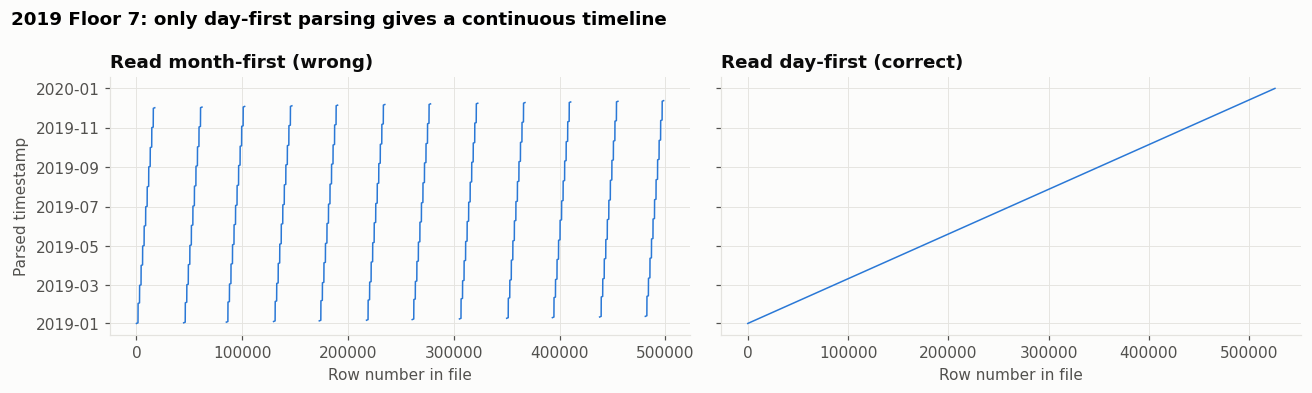

Read month-first: 318,240 rows can't be parsed at all (day > 12).


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, parsed, title in [(axes[0], month_first, "Read month-first (wrong)"), (axes[1], day_first, "Read day-first (correct)")]:
    ax.plot(np.arange(len(parsed)), parsed, color=CLEAN_COLOR, linewidth=1)
    ax.set_title(title); ax.set_xlabel("Row number in file")
axes[0].set_ylabel("Parsed timestamp")
fig.suptitle("2019 Floor 7: only day-first parsing gives a continuous timeline", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "3_1_floor7_date_format"); plt.show()
print(f"Read month-first: {month_first.isna().sum():,} rows can't be parsed at all (day > 12).")

**What this shows:**

- **Month-first (left):** the timeline is broken into repeated saw-teeth. Days 13-31 can't be read at all, losing **318,240 rows (61% of the file)**, and the rest are scrambled.
- **Day-first (right):** a perfectly straight line, so every row is in order and no minute is missing.

This confirms that 2019 Floor 7 must be parsed day-first.

### 3.2 Missing values by floor, type and day

**What we're checking:** *where* and *when* is data missing?

**How to read the heatmap:**

- **Rows:** each row is one floor and measurement type (e.g. "Floor 3 · AC").
- **Columns:** each column is one day.
- **Colour:** the share of that day's readings that are missing. White means complete, dark blue means entirely missing.

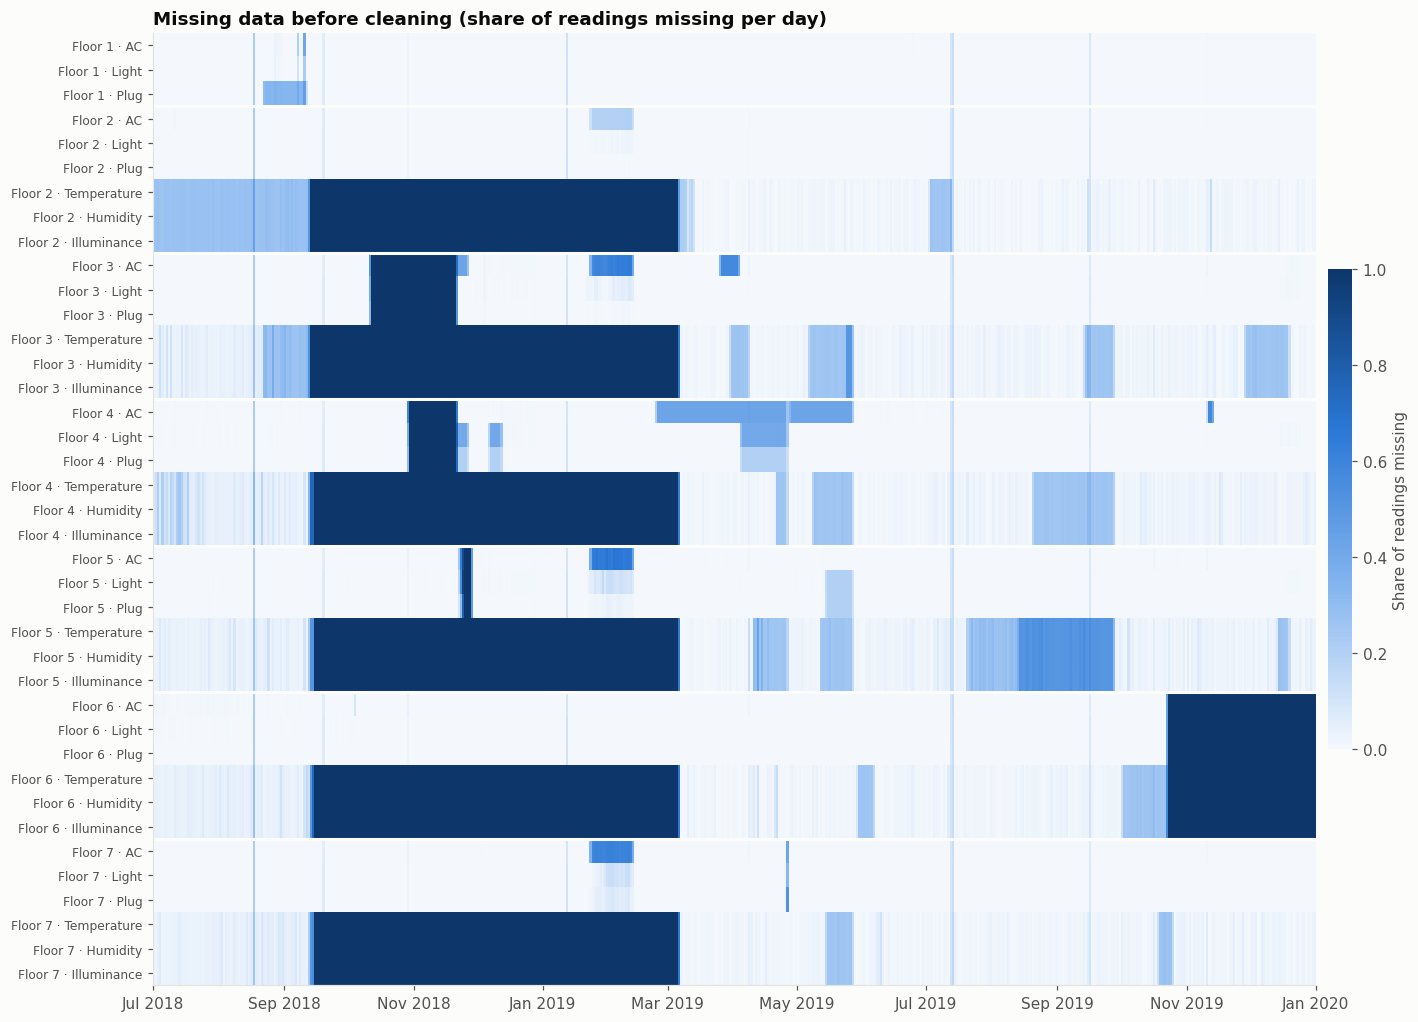

In [20]:
plot_missing(raw, "Missing data before cleaning (share of readings missing per day)", "3_2_missing_heatmap_before")

**What this shows:** most of the chart is white, but there are clear blocks.

1. **The big dark band (all sensors, 12-15 Sep 2018 → 6 Mar 2019):** temperature, humidity and lux are missing on *every* floor for about 175 days. Because it hits all floors at once, it was a **building-wide sensor outage**, not a fault on one floor.
2. **Floor 6, from 22 Oct 2019:** everything goes dark. This is the truncated file.
3. **Floor 3 (11 Oct → 26 Nov 2018) and Floor 4 (29 Oct → 26 Nov 2018):** all power data is missing. These are **whole-floor logger outages** of about 6 and 4 weeks.
4. **A medium-blue strip, 23 Jan → 12 Feb 2019 (Floors 2, 3, 5, 7 · AC):** one AC meter per zone stopped reporting on several floors at once.
5. **Smaller lighter blocks:** one meter out of several is missing. Examples are Floor 4 AC (Feb-May 2019) and Floor 1 Plug (22 Aug → 10 Sep 2018).
6. **Thin vertical lines and speckle:** these are **short dropouts** lasting minutes to hours, which affect many columns.

### 3.3 How long the gaps are

**What we're checking:** are the gaps mostly short dropouts or long outages? This decides what can be repaired.

**How to read it:** a "gap" is a run of consecutive missing minutes in one column. The x-axis is the gap's length on a log scale, so 10¹ = 10 minutes, 10³ ≈ 17 hours and 10⁵ ≈ 70 days. The y-axis counts how many gaps have that length. The dashed line marks 15 minutes.

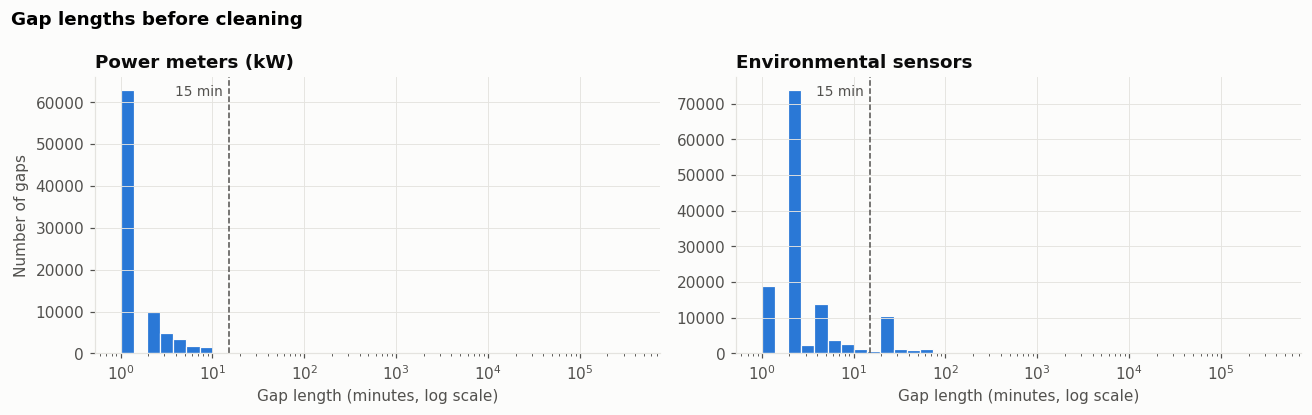

gaps  missing_minutes  share_of_gaps_%  share_of_missing_minutes_%
group                 length                                                                         
Environmental sensors <= 15 min  117039           296215             88.3                         1.3
                      > 15 min    15558         21762576             11.7                        98.7
Power meters (kW)     <= 15 min   85145           143855             98.4                         3.0
                      > 15 min     1353          4681079              1.6                        97.0

In [21]:
gaps_before = all_gaps(raw)
plot_gap_lengths(gaps_before, "Gap lengths before cleaning", "3_3_gap_lengths_before")
gap_summary(gaps_before)

**What this shows:**

- **Most gaps are tiny:** for power meters, **98.4%** of gaps last 15 minutes or less, most of them a single minute. For environmental sensors it's **88.3%**, with a clear peak at 2 minutes, which suggests those sensors sometimes report only every other minute.
- **But short gaps hold little of the missing data:** only **3%** of missing power minutes and **1%** of missing sensor minutes are in short gaps. Almost all the missing *time* comes from a few long outages.
- **The consequence:** repairing short gaps fixes the vast majority of holes, which helps every later calculation, but it barely changes the total amount of data. The long outages can't be repaired, because there is nothing nearby to estimate from.

### 3.4 Power spikes: maximum compared with normal peak

**What we're checking:** which power meters contain extreme spikes?

**How to read it:**

- **Dots:** each dot is one power meter. Its height is the meter's single highest reading divided by its 99.9th percentile, which we call its "normal peak".
- **Healthy meters** sit close to 1, because their highest reading is about their usual peak.
- **The dashed line** marks 3x the normal peak.
- **Idle circuits** (meters that never exceed 1 kW) are left out.

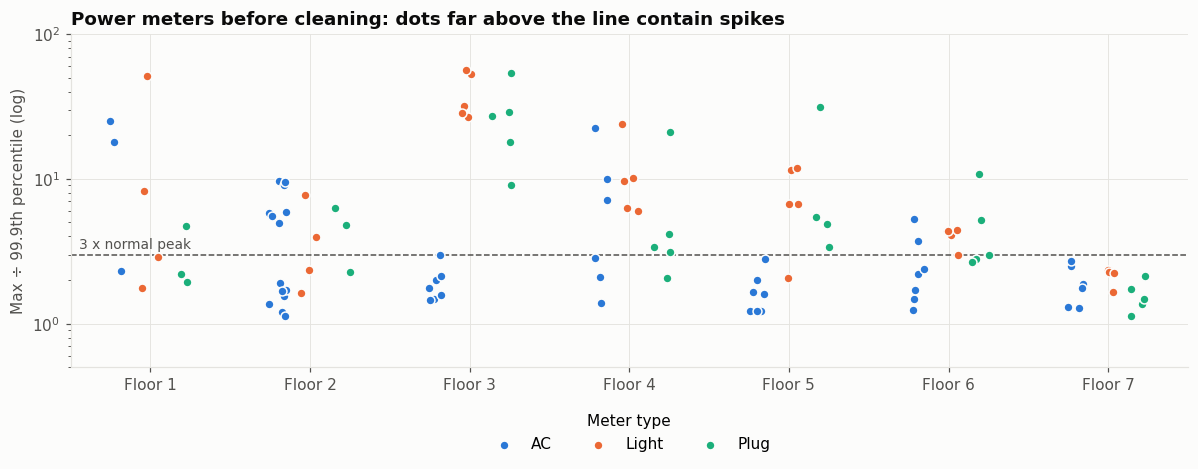

55 of 120 power meters have a maximum above 3x their normal peak.


In [22]:
ratios_before = spike_ratios(raw)
plot_spike_ratios(ratios_before, "Power meters before cleaning: dots far above the line contain spikes", "3_4_spike_ratio_before")
print(f"{(ratios_before['ratio'] > 3).sum()} of {len(ratios_before)} power meters have a maximum above 3x their normal peak.")

**What this shows:**

- **Scale:** **55 of 120** power meters have at least one reading above 3x their normal peak, and some reach 30-56x.
- **Floor 3** is the worst: almost every lighting and plug meter there sits far above the line.
- **Floor 7** is the cleanest, with every meter below the line.
- **The pattern:** spikes appear across all three meter types. That points to a *data* problem (how the logger records) rather than a *building* problem (a faulty AC unit).

### 3.5 What a spike looks like

**What we're checking:** is a spike a brief error, or a real period of high power use? Here are the 4 most extreme meters, shown 30 minutes either side of their highest reading.

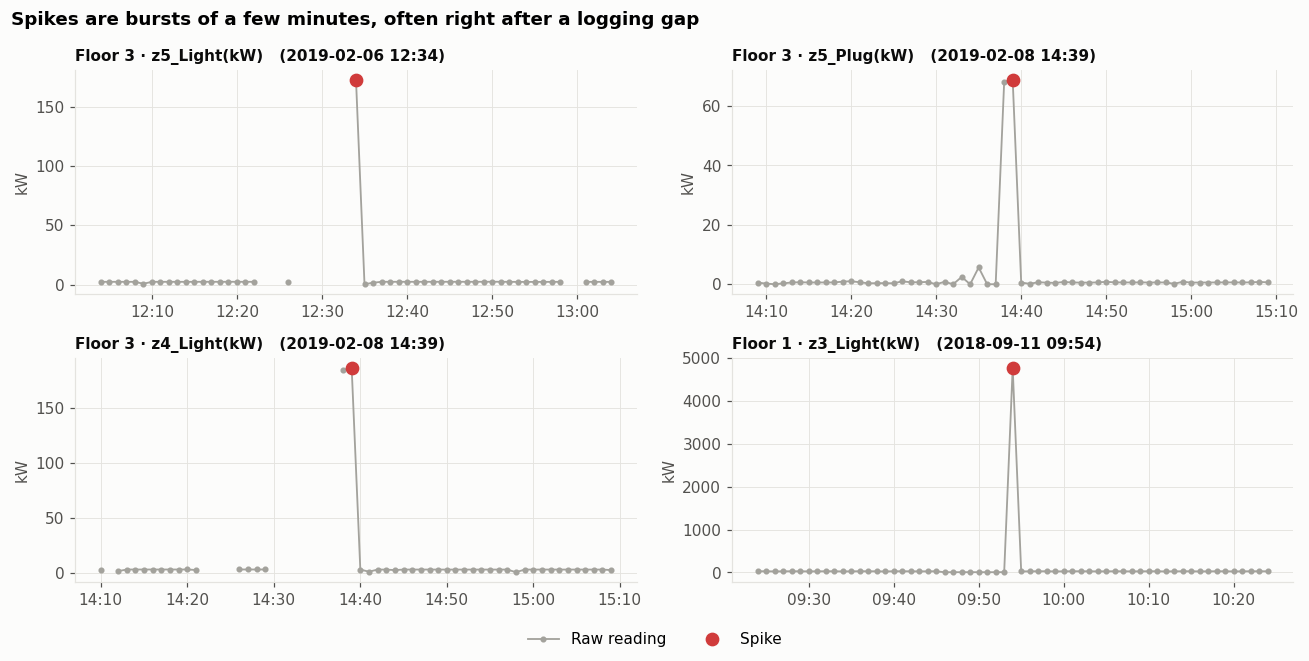

,floor,column,max_at,max,p99_9
0,3,z5_Light(kW),2019-02-06 12:34:00,172.32,3.07000
1,3,z5_Plug(kW),2019-02-08 14:39:00,68.75,1.28000
2,3,z4_Light(kW),2019-02-08 14:39:00,186.08,3.49000
3,1,z3_Light(kW),2018-09-11 09:54:00,4762.43,93.27108


In [23]:
closeups = ratios_before.nlargest(4, "ratio")[["floor", "column", "max_at", "max", "p99_9"]].reset_index(drop=True)
plot_closeups(closeups, raw, None, "Spikes are bursts of a few minutes, often right after a logging gap", "3_5_spike_closeups_before")
closeups

**What this shows:**

- **Floor 1 lighting (bottom right):** reads about 25 kW, drops to about 5 kW, then jumps to **4,762 kW for a single minute** before returning to normal. Even the whole building's total demand peaks below 900 kW, so this is physically impossible.
- **Floor 3 (other three panels):** each spike lasts 1-2 minutes at about **50x the normal level**, then the readings return to normal. Two of the three come **straight after a gap** (the breaks in the grey line).

**Sample data: the spike vs a normal day.** Here are the Floor 1 lighting readings in the minutes around the 4,762 kW spike, next to the same meter at the same times exactly one week earlier:

In [24]:
spike_t = pd.Timestamp("2018-09-11 09:54")
s = raw[1]["z3_Light(kW)"]
around = pd.date_range(spike_t - pd.Timedelta(minutes=4), spike_t + pd.Timedelta(minutes=4), freq="min")
spike_sample = pd.DataFrame({
    "time": around.strftime("%H:%M"),
    "spike day, 11 Sep 2018 (kW)": s.reindex(around).values,
    "one week earlier, 4 Sep 2018 (kW)": s.reindex(around - pd.Timedelta(days=7)).values,
})
spike_sample["status"] = np.where(around == spike_t, "SPIKE", "normal")
print(f"This meter's normal peak (99.9th percentile): {s.quantile(0.999):.1f} kW")
spike_sample

This meter's normal peak (99.9th percentile): 93.3 kW


,time,"spike day, 11 Sep 2018 (kW)","one week earlier, 4 Sep 2018 (kW)",status
0,09:50,5.53,13.13,normal
1,09:51,4.42,13.16,normal
2,09:52,5.54,13.20,normal
3,09:53,5.52,12.30,normal
4,09:54,4762.43,13.14,SPIKE
5,09:55,23.52,13.12,normal
6,09:56,25.66,13.11,normal
7,09:57,27.33,13.13,normal
8,09:58,27.36,13.16,normal


**What the sample shows:**

- **Normal readings:** both days run between 4 and 27 kW, a typical lighting load.
- **The spike:** at 09:54 one reading is **4,762 kW**, about 50x the meter's normal peak of 93 kW. One minute later it is back to 23.5 kW.
- **The week before:** at exactly the same time, the meter reads a steady 13 kW.

A lighting circuit can't jump to 4.7 MW for one minute and back, so this is almost certainly a recording error. Without the logger's maintenance records it can't be *confirmed*, though, which is how the notebook treats it.

**Sample data: a logger burst across a whole floor.** Here is Floor 3 on 8 February 2019, minute by minute, for five of its meters:

In [25]:
burst_cols = ["z1_Light(kW)", "z1_Plug(kW)", "z3_Plug(kW)", "z4_Plug(kW)", "z5_Plug(kW)"]
burst = raw[3].loc["2019-02-08 13:19":"2019-02-08 13:33", burst_cols].copy()
normal_peak = raw[3][burst_cols].quantile(0.999)
burst["status"] = np.select(
    [burst[burst_cols].isna().any(axis=1), (burst[burst_cols] > 3 * normal_peak).any(axis=1)],
    ["logger gap", "BURST"], "normal")
print("Normal peak (99.9th percentile) of each meter:", normal_peak.round(1).to_dict())
burst.index = burst.index.strftime("%H:%M")
burst

Normal peak (99.9th percentile) of each meter: {'z1_Light(kW)': 6.0, 'z1_Plug(kW)': 2.0, 'z3_Plug(kW)': 0.8, 'z4_Plug(kW)': 1.8, 'z5_Plug(kW)': 1.3}


,z1_Light(kW),z1_Plug(kW),z3_Plug(kW),z4_Plug(kW),z5_Plug(kW),status
Date,,,,,,
13:19,5.23,0.54,0.52,0.79,0.48,normal
13:20,2.35,1.19,0.53,0.78,0.76,normal
13:21,5.23,1.24,0.53,0.75,0.76,normal
13:22,3.59,0.24,0.37,NaN,0.00,logger gap
13:23,4.31,0.25,0.37,NaN,0.00,logger gap
13:24,10.76,4.26,1.50,5.21,3.41,normal
13:25,4.32,0.26,0.38,NaN,0.00,logger gap
13:26,4.32,0.26,0.37,NaN,0.00,logger gap
13:27,35.45,17.76,5.87,25.57,16.45,BURST


**What the sample shows:**

- **Normal (13:19-13:21):** all five meters read normal values of 0.5-5 kW.
- **Logger gap (13:22-13:26):** the logger starts dropping out. `z4_Plug` stops reporting (`NaN`), `z5_Plug` falls to 0, and at 13:24 a single minute comes through with every meter already raised.
- **Burst (13:27-13:30):** **all five meters jump together** to 6-37 kW, up to 25x their normal peak, for four minutes.
- **Normal again (from 13:31):** every meter is instantly back to its usual level.

Different circuits (lighting and plug loads in different zones) can't all surge at the same moment and stop together four minutes later. Only the logger they share could cause that.

**Interpretation:** this matches how a data logger behaves when it reconnects after a dropout: it writes a burst of bad values. **These are most likely recording errors rather than real demand.** The Floor 3 cases all fall between 4 and 12 February 2019, when that floor's logger kept disconnecting.

Data shows *symptoms*, not confirmed faults, and calling every unusual pattern a confirmed fault would overstate the evidence. So this is treated as the most likely explanation, not a proven one. No logger or maintenance records are available to confirm it, which is why every removed value is kept in `removed_readings.csv`.

### 3.6 Environmental sensor values against their plausible range

**What we're checking:** are there physically impossible temperature, humidity or light readings? Every reading from every sensor on every floor goes into one histogram per measurement. The y-axis is on a log scale, so rare values are still visible.

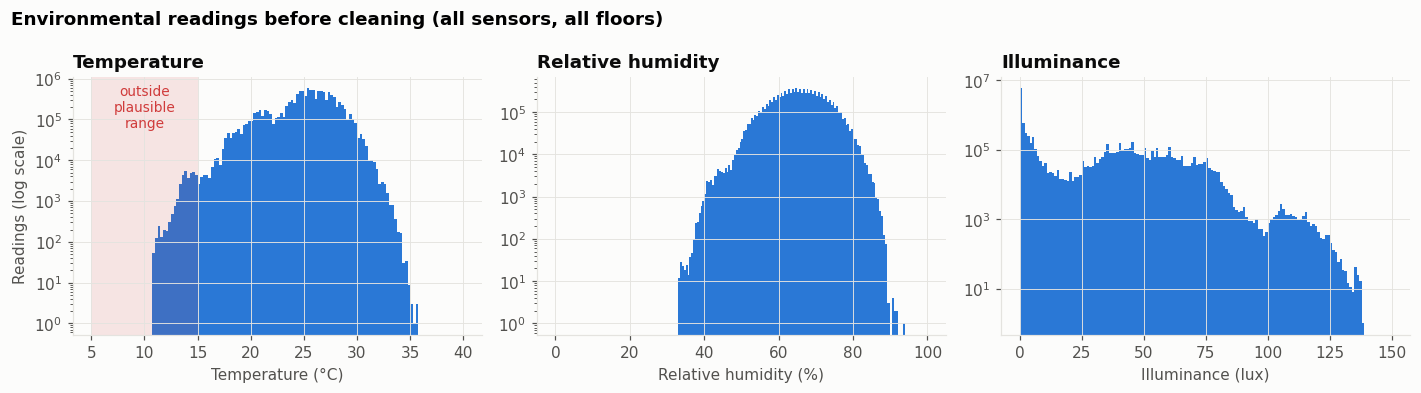

Temperature readings below 15 °C: {'Floor 5 · z1_S1(degC)': 33972}


In [26]:
plot_env(raw, "Environmental readings before cleaning (all sensors, all floors)", "3_6_env_hist_before")
low = {f"Floor {f} · {c}": int((raw[f][c] < 15).sum()) for f in FLOORS for c in cols_of(raw[f], "Temperature") if (raw[f][c] < 15).any()}
print("Temperature readings below 15 °C:", low)

**What this shows:**

- **Temperature:**
  - Most readings fall between **20 and 30 °C**, which is normal for an air-conditioned office in a hot climate.
  - There is a tail of readings **below 15 °C** (shaded red), down to 10.8 °C: **33,972 readings, all from a single sensor (Floor 5, zone 1)**.
  - When every other sensor in the building stays above 15 °C, one sensor reading 10-15 °C indicates a fault with that sensor.
- **Humidity:** 33-94%, a smooth and plausible range. Nothing to fix.
- **Illuminance:** 0-138 lux. The tall bar at 0 is night-time and lights-off periods. Nothing to fix.

### 3.7 Why is Floor 5 zone 1 so cold?

**What we're checking:** under the same conditions, how does Floor 5 zone 1 compare with the other zones on its floor? The plot shows each zone's median temperature at each hour of the day (from March 2019, when the sensors were working).

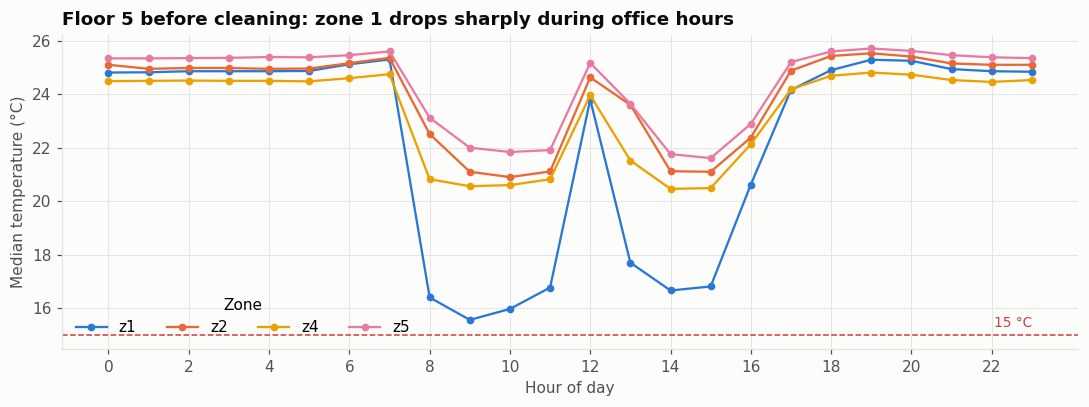

In [27]:
plot_floor5_temperature(raw[5], "Floor 5 before cleaning: zone 1 drops sharply during office hours", "3_7_floor5_temperature_before")

**What this shows:**

- **At night (17:00-07:00):** zone 1 reads about 25 °C, the same as the other zones, so the sensor itself works.
- **In office hours (08:00-16:00):** zone 1 drops to a median of **15-17 °C**, while the other zones stay at 20-22 °C.
- **At lunchtime (12:00):** every zone warms up, presumably because the AC pauses. Zone 1 jumps straight back to the others' level.

**Sample data: one day, every two hours.** This is the day with the most sub-15 °C readings:

In [28]:
z1 = raw[5]["z1_S1(degC)"]
coldest_day = (z1 < 15).groupby(z1.index.date).sum().idxmax()
temp_cols = cols_of(raw[5], "Temperature")
day_sample = raw[5].loc[str(coldest_day), temp_cols].iloc[::120].round(1)
day_sample["other zones (avg)"] = day_sample[[c for c in temp_cols if c != "z1_S1(degC)"]].mean(axis=1).round(1)
day_sample["z1 status"] = np.where(day_sample["z1_S1(degC)"] < 15, "IMPLAUSIBLE (< 15 °C)",
                                   np.where(day_sample["z1_S1(degC)"] < day_sample["other zones (avg)"] - 3, "much colder than others", "normal"))
print(f"{pd.Timestamp(coldest_day):%A %d %B %Y}")
day_sample.index = day_sample.index.strftime("%H:%M")
day_sample

Wednesday 03 July 2019


,z1_S1(degC),z2_S1(degC),z4_S1(degC),z5_S1(degC),other zones (avg),z1 status
Date,,,,,,
00:00,23.8,24.9,24.2,25.3,24.8,normal
02:00,23.8,24.1,24.2,25.3,24.5,normal
04:00,23.9,24.1,24.2,25.2,24.5,normal
06:00,23.9,24.2,24.2,25.3,24.6,normal
08:00,16.6,22.6,21.2,24.0,22.6,much colder than others
10:00,11.6,20.2,20.5,NaN,20.4,IMPLAUSIBLE (< 15 °C)
12:00,16.9,21.6,22.6,23.6,22.6,much colder than others
14:00,11.8,20.6,21.0,22.4,21.3,IMPLAUSIBLE (< 15 °C)
16:00,11.0,20.6,20.4,22.3,21.1,IMPLAUSIBLE (< 15 °C)


**What the sample shows:**

- **Night (00:00-06:00 and 18:00-22:00):** zone 1 reads 22-24 °C, within 1-2 °C of the other zones.
- **Office hours (08:00-16:00):** zone 1 falls to **11-17 °C**, while the other zones stay at 20-24 °C, a gap of up to 10 °C.
- **Lunchtime (12:00):** zone 1 recovers partly, to about 17 °C.

**Interpretation:** zone 1's sensor is cold *only while the AC is running* and recovers the moment it stops. It is most likely mounted **in or near the cold air coming out of an AC vent**. So it measures supply air, not room air, and its office-hours readings don't represent what occupants feel.

### 3.8 Stuck values: long runs of an identical reading

**What we're checking:** are any power meters "frozen", repeating the same value for hours? For each meter, we find its longest run of an identical, non-zero reading and plot how long it lasted against the value that repeated.

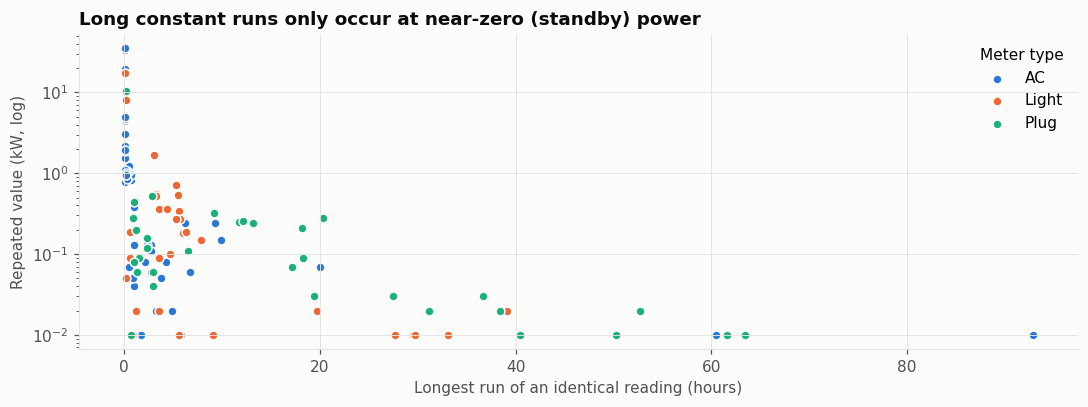

36 meters have a constant run of 6+ hours; the repeated value is at most 0.32 kW.


In [29]:
runs = constant_runs(raw)
plot_constant_runs(runs, "Long constant runs only occur at near-zero (standby) power", "3_8_constant_runs")
long_runs = runs[runs["longest_run_hours"] >= 6]
print(f"{len(long_runs)} meters have a constant run of 6+ hours; the repeated value is at most {long_runs['value_kW'].max():.2f} kW.")

**What this shows:**

- **Many long runs:** 36 meters repeat the same value for 6 hours or more, and the longest run lasts **93 hours**.
- **All at near-zero power:** every one of these runs sits at **0.32 kW or less**. The 93-hour run is an AC unit on Floor 7 idling at 0.01 kW from Saturday 28 December 2019, over the New Year period.
- **High readings change constantly:** they never stay identical for long.

**Sample data: standby vs in use.** Here is the 93-hour run's meter (Floor 7 zone 1 AC2) over the New Year period, next to the same meter on an ordinary working morning:

In [30]:
ac = raw[7]["z1_AC2(kW)"]
standby = ac.loc["2019-12-28 03:10":"2019-12-28 03:17"]
in_use = ac.loc["2019-12-20 10:00":"2019-12-20 10:07"]
pd.DataFrame({
    "New Year period, Sat 28 Dec 2019": standby.index.strftime("%H:%M"), "kW (standby)": standby.values,
    "working day, Fri 20 Dec 2019": in_use.index.strftime("%H:%M"), "kW (in use)": in_use.values,
})

,"New Year period, Sat 28 Dec 2019",kW (standby),"working day, Fri 20 Dec 2019",kW (in use)
0,03:10,0.01,10:00,0.21
1,03:11,0.01,10:01,0.24
2,03:12,0.01,10:02,0.45
3,03:13,0.01,10:03,0.19
4,03:14,0.01,10:04,0.19
5,03:15,0.01,10:05,0.19
6,03:16,0.01,10:06,0.19
7,03:17,0.01,10:07,0.20


**What the sample shows:**

- **In use:** the reading changes almost every minute (0.19-0.45 kW) as the unit's compressor and fan adjust.
- **Over New Year:** it sits at exactly **0.01 kW**, the trickle drawn by a switched-off unit's controls.

A frozen sensor would repeat a *realistic working* value. This is a genuine "off" value.

**Interpretation:** these are not frozen sensors. They are equipment on **standby** overnight, at weekends and during closures, drawing a tiny constant current. That is real behaviour and should be kept.

### 3.9 Unusual operation: building closures

**What we're checking:** are there days when the building behaves very differently, and are they *bad data* or *real events*? Not every unusual row is bad data. A weekday with almost no power use looks like an anomaly, but the building may simply have been closed.

**How it's measured (using only the energy data):** each floor's daily energy is divided by that floor's typical (median) working-day energy, and the median across floors gives one **activity** value per day. **1.0** means a normal working day.

**How to read the plot:** each dot is one day. A weekday below the dashed line used less than half a normal working day's energy, meaning the building was effectively closed.

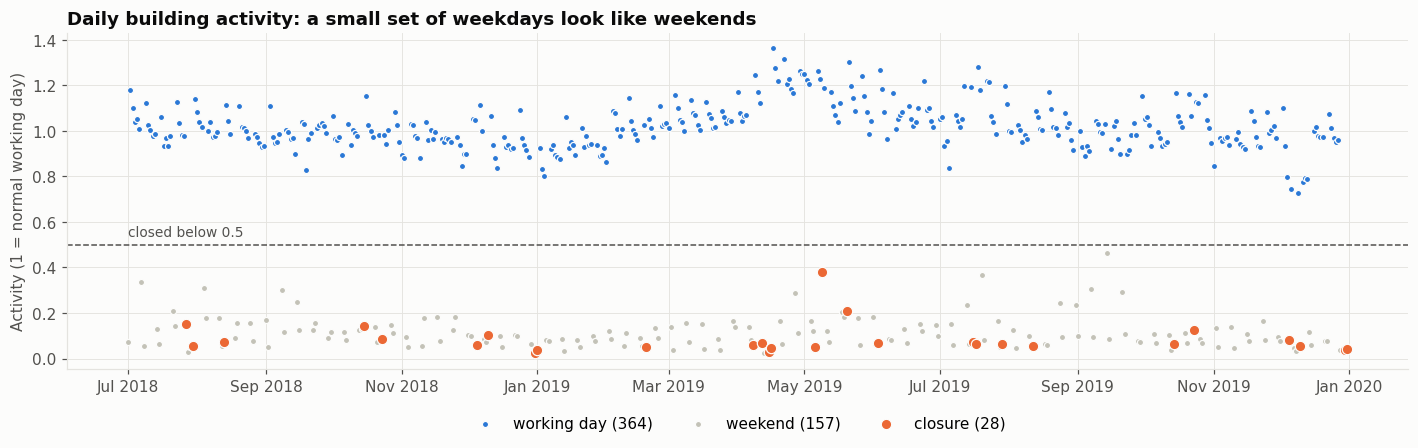

,days,median_activity,lowest,highest
day_type,,,,
closure,28,0.06,0.02,0.38
weekend,157,0.10,0.02,0.47
working day,363,1.01,0.73,1.36


In [31]:
day_info = daily_activity(raw)
plot_activity(day_info, "Daily building activity: a small set of weekdays look like weekends", "3_9_daily_activity")
day_info.groupby("day_type")["activity"].agg(days="count", median_activity="median", lowest="min", highest="max").round(2)

**What this shows:** weekends sit at about **0.1** and working days at about **1.0**, so the two separate cleanly. The weekdays that break this pattern are listed below.

In [32]:
day_info[day_info["day_type"] == "closure"].round(2)

,activity,floors_reporting,weekday,day_type
Date,,,,
2018-07-27,0.15,7,Friday,closure
2018-07-30,0.05,7,Monday,closure
2018-08-13,0.07,7,Monday,closure
2018-10-15,0.14,6,Monday,closure
2018-10-23,0.09,6,Tuesday,closure
2018-12-05,0.06,7,Wednesday,closure
2018-12-10,0.10,6,Monday,closure
2018-12-31,0.02,7,Monday,closure
2019-01-01,0.04,7,Tuesday,closure


**Is it the whole building, or one floor?** The next table shows each floor's median activity on working days, at weekends and on the closure days found above.

In [33]:
per_floor = floor_activity(raw)
pd.DataFrame({t: per_floor[day_info["day_type"] == t].median() for t in ["working day", "weekend", "closure"]}).T \
  .rename(columns=lambda f: f"Floor {f}").round(2)

,Floor 1,Floor 2,Floor 3,Floor 4,Floor 5,Floor 6,Floor 7
working day,1.00,1.01,1.01,1.01,1.01,1.01,1.01
weekend,1.02,0.19,0.05,0.08,0.06,0.10,0.07
closure,0.99,0.18,0.02,0.06,0.04,0.07,0.04


**What this shows:**

- **28 weekdays look like weekends:** their activity is 0.02-0.38, the same level as a Saturday or Sunday.
- **A clean separation:** no working day falls below about 0.73, so any threshold between 0.38 and 0.73 picks out exactly the same days. The result doesn't depend on the exact cut-off.
- **Every floor behaves exactly as it does at weekends** (per-floor table):
  - **Floors 2-7** drop to 2-19% of a normal working day, at weekends and on closure days alike.
  - **Floor 1** stays at about 100% every day, including weekends and closure days. It evidently runs around the clock, so it can't signal a closure either way. That is worth remembering in later analyses, because Floor 1's "normal day" includes weekends.
- **The meters keep reporting:** the readings are low, not missing.
- **A pattern, not random dates:** many are Mondays or Fridays next to a weekend, and they cluster in mid-April and around New Year.

**Why these are real closures and not bad data:**

- **A metering fault looks different:** it usually shows up as *missing* data or affects *one* floor. Here, six floors with separate loggers all record weekend-level use on the same days, while Floor 1 carries on exactly as it does every weekend. On these days the building simply behaves like a weekend.
- **Not confirmed externally:** the reason for each date is not checked against an outside source in this notebook. That is listed as an assumption in Section 8.

**Interpretation:** these days are **real operation, not bad data**. Deleting them as outliers would remove true behaviour. Leaving them unlabelled would also be harmful, because they would drag down any "normal working day" baseline. So they are **kept and labelled**: every exported table gets a `day_type` column (action 9).

### 3.10 Summary of the findings

Each finding is classified two ways:

- **Problem type:** which of the six data-quality problems it is.
- **Anomaly type:** the standard three-way classification, which applies to energy and comfort data alike:
  - **Point:** one value is unusual.
  - **Contextual:** a value is normal in one context but not in this one.
  - **Collective:** a group of values is unusual together.

| # | Finding | Problem type | Anomaly type | Evidence |
|---|---|---|---|---|
| 1 | 2019 Floor 7 must be read day-first | Misaligned | — (format) | 3.1: month-first loses 61% of rows |
| 2 | Building-wide sensor outage, Sep 2018 - Mar 2019 | Missing | — (gap) | 3.2: dark band across every floor |
| 3 | Whole-floor power outages (Floor 3 and Floor 4, Oct-Nov 2018), and Floor 6 cut off from 22 Oct 2019 | Missing | — (gap) | 3.2 |
| 4 | Most gaps are short (≤ 15 min), but long outages hold almost all the missing time | Missing | — (gap) | 3.3 |
| 5 | Power spikes of 3-56x normal peak in 55 meters, most likely logger bursts after dropouts | Noisy | **Point** (e.g. 4,762 kW for one minute); **collective** where several meters burst together (Floor 3, Feb 2019) | 3.4, 3.5 |
| 6 | Floor 5 zone 1 temperature sensor most likely reads AC supply air in office hours | Noisy + wrong context | **Contextual**: cold only while the AC runs, normal at night | 3.6, 3.7 |
| 7 | Long constant runs are real standby power, not frozen sensors | Stale: checked and ruled out | — (normal behaviour) | 3.8 |
| 8 | 28 weekdays when the building behaves like a weekend (building closures); Floor 1 runs 7 days a week | Unusual operation, **not** bad data | **Contextual**: weekend-level energy is normal on a Saturday, unusual on a weekday | 3.9 |
| 9 | Floors' clocks agree and units are correct; lux sensors are not at desk height | Misaligned: ruled out. Wrong context: flagged. | — | 1.6, 1.7 |

## 4. Recommended actions

Each action follows three rules:

- **Bad data → clean or flag.** Fix what can be reliably corrected (formats, short gaps), remove what is clearly impossible (spikes, implausible readings), and **log every removal** so nothing is hidden.
- **Unusual operation → investigate, don't delete.** Real events such as building closures are kept and labelled.
- **Never invent data.** What can't be known (long outages) is left blank and documented.

### 4.1 How the anomalies are detected

There are three common ways to detect anomalies. The simplest one that answers the question is the best:

| Method | What it means | Used in this notebook for |
|---|---|---|
| **Rule-based** | A known engineering limit | Physical valid ranges (temperature 15-40 °C, humidity 0-100%, power ≥ 0), date-format and clock checks |
| **Statistical** | Unusual relative to history | The spike rule: a meter's own 99.9th percentile and the median of the surrounding hour. Plain z-score and IQR were tested and rejected (below). |
| **Model-based** | Unexpected after normalisation (actual − predicted residual) | **Not used for cleaning.** It needs a baseline model trained on clean, normal baseline-period data. That is the next stage of the project, built on these cleaned files. |

### 4.2 Recommended action for each problem

| # | Problem | Recommended action | Why |
|---|---|---|---|
| 1 | 2019 Floor 7 uses a day-first date format | Parse with `%d/%m/%y %H:%M`, then write every file back in the standard `YYYY-MM-DD HH:MM:SS` format | Day-first is the only reading that gives a complete, ordered timeline (3.1). One consistent format prevents the same mistake in later notebooks. |
| 2 | Junk row at the end of 2019 Floor 6 | Drop it | It has no valid date and no values (1.4). |
| 3 | Missing minutes (2019 Floor 6 after 22 Oct) | Put every floor on a complete 1-minute timeline, leaving missing minutes empty | Every file then has the same predictable rows, and gaps are visible instead of hidden. |
| 4 | Power spikes | Remove readings that meet **all** of these conditions: above **3x the meter's normal peak** (and above 5 kW), above **5x the median of the surrounding hour**, and lasting **5 minutes or less**. Repeat until none remain. | Requiring every condition means real peaks are kept: a busy afternoon is high, but not 5x the hour around it. The longest logger burst found is 4-5 minutes (Floor 3, Feb 2019). Allowing 10 minutes would start deleting a genuine sustained load on Floor 1, so 5 minutes is the cut-off. The three conditions follow a standard way of triaging anomalies, *magnitude x duration x context*: an extreme (magnitude), very brief (duration) jump that its own surrounding hour can't explain (context) points to a logging error. A large deviation that **persists** is treated as possible real operation and kept for investigation. Every removed reading is logged in `removed_readings.csv`. |
| 5 | Temperatures below 15 °C (Floor 5 zone 1) | Set to missing, and **don't** fill. Log each one in `removed_readings.csv`. | A plausibility rule: an air-conditioned office can't be 10-14 °C, and the sensor is reading supply air (3.7). Its remaining readings are kept but flagged. |
| 6 | Short gaps (≤ 15 minutes) | Fill by **linear interpolation**: a straight line between the reading just before and just after the gap | Building loads change slowly over a few minutes, so a straight line is a close estimate. 15 minutes is also the utility's demand-billing interval, so a repaired gap never spans more than one demand interval. The test in 4.3 B measures how accurate the filled values are. |
| 7 | Long gaps (> 15 minutes): outages, the truncated file, the sensor outage | **Leave empty**, and record them in `data_quality.csv` | Filling days or months would *invent* data and bias every result built on it. The combined tables instead report how complete each interval is (`coverage_pct`). |
| 8 | Long constant runs near zero | **Keep** | This is real standby power (3.8). Removing it would wrongly lower night-time and weekend baselines. |
| 9 | Closure days (unusual operation) | **Keep, and label** each day with a `day_type`: working day, weekend or closure | They are real behaviour (3.9). The label lets later analyses leave them out of "normal working day" baselines, which a fair baseline needs, without deleting anything. |
| 10 | Lux sensors probably not at desk height (wrong context) | **Keep**, and note in `data_quality.csv` that lux is a relative indicator | Cleaning can't correct sensor placement, but analysts need to know before comparing lux with lighting standards. |

### 4.3 How each limit was chosen

Every cleaning rule needs a number: how big a spike is, how long a gap can be filled, how cold is too cold. A number picked without evidence is just a guess. So each limit below is tested by **trying several values and showing what each one would do to the data**. The chosen value is marked **◀ chosen**.

#### A. The spike rule

A reading is removed as a spike only if it passes **all four** limits:

1. **Above x normal peak:** it must be more than 3x the meter's 99.9th percentile, which is the highest level the meter normally reaches.
2. **Minimum size:** it must be above 5 kW.
3. **Above x surrounding hour:** it must be more than 5x the median of the hour around it.
4. **Longest duration:** it must last 5 minutes or less.

To judge each limit, the table tracks two known cases:

- **Floor 3 bursts, 4-12 Feb 2019 (3.5):** clear logger errors that a good setting **should catch**.
- **Floor 1 z3_Plug:** a meter whose high readings stay up for tens of minutes, which looks like a real load. A good setting should **mostly leave it alone**.

Each row changes one limit and keeps the other three at their chosen values.

In [34]:
# Prepare once: for every power meter, the readings that could be a spike under the loosest setting tested
spike_pool = []
for f in FLOORS:
    for c in raw[f].columns:
        if column_info(c)["unit"] != "kW":
            continue
        s = raw[f][c]
        x, p = s.to_numpy(), s.quantile(0.999)
        pos = np.flatnonzero((x > 2 * p) & (x > 0))
        if len(pos):
            local = s.rolling(SPIKE_WINDOW, center=True, min_periods=10).median().clip(lower=1.0).to_numpy()[pos]
            spike_pool.append({"floor": f, "column": c, "pos": pos, "value": x[pos], "local": local, "p99_9": p, "time": s.index[pos]})

def spike_test(p999_mult=SPIKE_P999_MULT, min_kw=SPIKE_MIN_KW, local_mult=SPIKE_LOCAL_MULT, max_run=SPIKE_MAX_RUN):
    """One pass of the spike rule with the given limits: how much would it remove?"""
    out = {"readings flagged": 0, "meters": 0, "Floor 3 bursts caught": 0, "Floor 1 z3_Plug flagged": 0}
    for m in spike_pool:
        flagged = m["pos"][(m["value"] > max(p999_mult * m["p99_9"], min_kw)) & (m["value"] > local_mult * m["local"])]
        runs = [r for r in np.split(flagged, np.flatnonzero(np.diff(flagged) != 1) + 1) if 0 < len(r) <= max_run]
        if not runs:
            continue
        kept = np.concatenate(runs)
        times = m["time"][np.isin(m["pos"], kept)]
        out["readings flagged"] += len(kept)
        out["meters"] += 1
        if m["floor"] == 3:
            out["Floor 3 bursts caught"] += int(((times >= "2019-02-04") & (times < "2019-02-13")).sum())
        if (m["floor"], m["column"]) == (1, "z3_Plug(kW)"):
            out["Floor 1 z3_Plug flagged"] += len(kept)
    return out

tests = [("x normal peak", "p999_mult", [2, 3, 5, 10], SPIKE_P999_MULT),
         ("minimum size (kW)", "min_kw", [0, 2, 5, 10], SPIKE_MIN_KW),
         ("x surrounding hour", "local_mult", [3, 5, 10], SPIKE_LOCAL_MULT),
         ("longest duration (min)", "max_run", [1, 3, 5, 10, 30], SPIKE_MAX_RUN)]
pd.DataFrame([{"limit": name, "value tested": v, **spike_test(**{key: v}), "": "◀ chosen" if v == chosen else ""}
              for name, key, values, chosen in tests for v in values]).set_index(["limit", "value tested"])

readings flagged  meters  Floor 3 bursts caught  Floor 1 z3_Plug flagged          
limit                  value tested                                                                                    
x normal peak          2                          606      62                    273                       84          
                       3                          449      50                    262                       14  ◀ chosen
                       5                          304      41                    205                        0          
                       10                         144      21                    109                        0          
minimum size (kW)      0                          449      50                    262                       14          
                       2                          449      50                    262                       14          
                       5                          449      50                    262                       14  ◀ chosen
                       10                         341      40                    191                       14          
x surrounding hour     3                          578      52                    278                       14          
                       5                          449      50                    262                       14  ◀ chosen
                       10                         232      34                    159                       14          
longest duration (min) 1                          260      49                    103                        1          
                       3                          421      50                    238                       14          
                       5                          449      50                    262                       14  ◀ chosen
                       10                         475      50                    262                       40          
                       30                         488      50                    262                       53

**What this shows, limit by limit:**

- **x normal peak (3):**
  - **2x:** flags jump to 606 and start hitting the Floor 1 plug load (84 readings).
  - **5x and 10x:** start missing Floor 3 bursts, catching only 205 and 109 of them.
  - **3x** catches the bursts while touching only 14 Floor 1 readings.
- **Minimum size (5 kW):** 0, 2 and 5 kW give *identical* results, so on this data the 5 kW floor never actually decides anything. It is kept as a safety net, so tiny fluctuations on almost-idle meters can never be called spikes. 10 kW would be too high: it misses 71 Floor 3 bursts, because small plug circuits only burst to 6-8 kW.
- **x surrounding hour (5):** this is the one judgement call. The count falls smoothly (578 → 449 → 232) with no natural break.
  - **10x** misses 103 of the 262 Floor 3 bursts.
  - **3x** adds 129 flags, most of them outside the known burst period, where calling them errors is harder to defend.
  - **5x** is the middle ground. Every removal is logged in `removed_readings.csv`, so it can be reviewed.
- **Longest duration (5 minutes): the clearest result.**
  - **Floor 3 bursts** caught rise from 103 (1 minute) to 238 (3 minutes) to **262 (5 minutes)**, then stay at 262 for 10 and 30 minutes. So every burst lasts 5 minutes or less.
  - **Floor 1 plug readings** flagged are 14 at both 3 and 5 minutes, then climb to 40 (10 minutes) and 53 (30 minutes), as longer limits start removing what looks like a real load.
  - **5 minutes** is exactly the point that catches every burst before the real load is touched.

These are single-pass counts. Step 5 repeats the rule until nothing is left, which finds one more reading (450 in total).

**Surrounding window (61 minutes, ±30):** a burst lasts 1-5 minutes, so the median of the hour around it is still made of normal readings. One hour is also short enough to follow the daily pattern, such as lights switching on in the morning. This value was a judgement and wasn't tested separately.

#### B. The longest gap filled by interpolation (15 minutes)

The accuracy of a gap filler can't be tested on *real* gaps, because the true values are unknown. So the test makes artificial gaps:

1. Take stretches where every reading exists.
2. Hide a block of readings of a given length.
3. Fill it with a straight line, exactly as the cleaning does.
4. Compare the filled values with the real readings that were hidden.

This is repeated 300 times per meter and sensor for each gap length.

In [35]:
rng = np.random.default_rng(42)  # fixed seed, so the result is identical every run

def interpolation_error(unit, gap, samples_per_column=300):
    errors, levels = [], []
    for f in FLOORS:
        for c in raw[f].columns:
            if column_info(c)["unit"] != unit:
                continue
            x = raw[f][c].to_numpy()
            present = np.r_[0, np.cumsum(~np.isnan(x))]
            complete = np.flatnonzero(present[gap + 2:] - present[:-(gap + 2)] == gap + 2)  # windows with nothing missing
            if not len(complete):
                continue
            start = rng.choice(complete, size=min(samples_per_column, len(complete)), replace=False)
            before, after = x[start], x[start + gap + 1]
            filled = before[:, None] + (after - before)[:, None] * (np.arange(1, gap + 1) / (gap + 1))
            actual = x[start[:, None] + np.arange(1, gap + 1)]
            errors.append(np.abs(filled - actual).ravel())
            levels.append(np.abs(actual).ravel())
    errors, levels = np.concatenate(errors), np.concatenate(levels)
    return errors.mean(), errors.mean() / levels.mean() * 100

rows = []
for gap in [1, 5, 15, 30, 60, 120, 240]:
    kw_error, kw_pct = interpolation_error("kW", gap)
    temp_error, _ = interpolation_error("degC", gap)
    rows.append({"gap length (minutes)": gap, "power: average error (kW)": round(kw_error, 2),
                 "power: error as % of load": round(kw_pct, 1), "temperature: average error (°C)": round(temp_error, 2),
                 "": "◀ chosen" if gap == MAX_INTERP_GAP_MIN else ""})
pd.DataFrame(rows).set_index("gap length (minutes)")

,power: average error (kW),power: error as % of load,temperature: average error (°C),
gap length (minutes),,,,
1,0.09,4.1,0.03,
5,0.15,7.1,0.04,
15,0.25,11.6,0.07,◀ chosen
30,0.32,15.3,0.11,
60,0.42,19.9,0.19,
120,0.58,27.5,0.37,
240,0.83,40.2,0.73,


In [36]:
# How many of the real gaps each limit would fill
pd.DataFrame([{"limit (minutes)": limit,
               **{f"{group}: gaps filled (%)": round((gaps_before.loc[gaps_before["group"] == group, "minutes"] <= limit).mean() * 100, 1)
                  for group in GAP_GROUPS},
               "": "◀ chosen" if limit == MAX_INTERP_GAP_MIN else ""}
              for limit in [5, 15, 30, 60]]).set_index("limit (minutes)")

,Power meters (kW): gaps filled (%),Environmental sensors: gaps filled (%),
limit (minutes),,,
5,94.1,82.3,
15,98.4,88.3,◀ chosen
30,98.9,96.8,
60,99.2,98.8,


**What this shows:**

- **Error grows steadily with gap length.** For power, a filled value is off by about 4% of the load for a 1-minute gap, 12% for 15 minutes, 20% for an hour and 40% for four hours. Temperature changes slowly, so its errors stay small for longer: 0.07 °C at 15 minutes and 0.19 °C at an hour.
- **Why 15 minutes:**
  - **Accuracy:** a typical error of about 12% applies only to the filled minutes, which are 0.3% of all readings (Step 5). The effect on any total or average is negligible.
  - **Coverage:** it fills 98% of the power-meter gaps and 88% of the sensor gaps.
  - **Demand billing:** it equals the utility's demand-billing interval, so a filled gap never spans more than one 15-minute demand value.
- **An honest caveat:** for temperature *alone*, a longer limit such as 60 minutes (about 0.2 °C error) would also be defensible, and would fill the many 20-30-minute sensor gaps. One common limit is used so every measurement is treated the same way. This is recorded as a judgement in Section 8.

#### C. The temperature limits (15-40 °C)

**What we're checking:** how many readings, and which sensors, each possible lower limit would remove.

In [37]:
temp_cols = [(f, c) for f in FLOORS for c in cols_of(raw[f], "Temperature")]
rows = []
for limit in [12, 14, 15, 16, 17, 18, 20]:
    hit = {f"Floor {f} {c.split('_')[0]}": int((raw[f][c] < limit).sum()) for f, c in temp_cols if (raw[f][c] < limit).any()}
    names = list(hit)
    rows.append({"lower limit (°C)": limit, "readings removed": f"{sum(hit.values()):,}", "sensors affected": len(hit),
                 "which sensors": ", ".join(names[:5]) + (", …" if len(names) > 5 else ""),
                 "": "◀ chosen" if limit == VALID_RANGE["degC"][0] else ""})
print(f"Highest temperature anywhere: {max(raw[f][c].max() for f, c in temp_cols):.1f} °C (upper limit: {VALID_RANGE['degC'][1]} °C)")
pd.DataFrame(rows).set_index("lower limit (°C)")

Highest temperature anywhere: 35.7 °C (upper limit: 40 °C)


,readings removed,sensors affected,which sensors,
lower limit (°C),,,,
12,739,1,Floor 5 z1,
14,"16,092",1,Floor 5 z1,
15,"33,972",1,Floor 5 z1,◀ chosen
16,"49,125",3,"Floor 3 z4, Floor 5 z1, Floor 7 z1",
17,"81,984",5,"Floor 2 z4, Floor 3 z4, Floor 4 z4, Floor 5 z1...",
18,"188,544",13,"Floor 2 z1, Floor 2 z4, Floor 3 z1, Floor 3 z4...",
20,"664,433",23,"Floor 2 z1, Floor 2 z2, Floor 2 z4, Floor 3 z1...",


**What this shows:**

- **12-15 °C:** any lower limit in this range removes readings from **only one sensor**, the faulty Floor 5 zone 1.
- **16 °C:** two more sensors appear (Floor 3 zone 4 and Floor 7 zone 1), whose lowest readings are about 15.7 °C. They otherwise behave normally.
- **18 °C:** thirteen sensors are affected, and at 20 °C, twenty-three.
- **Why 15 °C:** it is the **highest limit that removes only the faulty sensor's readings**. It is also far below any normal air-conditioned office target (about 23-24 °C), so a reading below it can't be room air.
- **The upper limit (40 °C):** the highest reading anywhere is about 36 °C, so 40 °C never removes anything. It is only a sanity limit.

#### D. The minimum coverage for combined tables (80%)

**What we're checking:** when a 15-minute or hourly value is averaged from minutes, how many of the minutes must exist? This shows how many 15-minute floor intervals each threshold would keep, using the raw data.

In [38]:
coverage = pd.concat([type_totals(raw[f])["total"].notna().resample("15min").mean() for f in FLOORS])
pd.DataFrame([{"minimum coverage": f"{threshold:.0%}", "15-min floor intervals kept (%)": round((coverage >= threshold).mean() * 100, 2),
               "": "◀ chosen" if threshold == MIN_COVERAGE else ""}
              for threshold in [0.5, 0.8, 0.95, 1.0]]).set_index("minimum coverage")

,15-min floor intervals kept (%),
minimum coverage,,
50%,90.02,
80%,89.97,◀ chosen
95%,86.53,
100%,86.53,


**What this shows:**

- **100% is too strict:** requiring every minute would throw away several percent of all intervals, most of them because of a single missing minute.
- **50% vs 80%:** these keep almost exactly the same intervals, because once a gap starts, it usually swallows the whole interval.
- **Why 80%:** an average built from at least 12 of 15 minutes (or 48 of 60) represents the interval well, while an average from half the minutes might not.
- **After cleaning:** the short gaps are filled, so partly-covered intervals become rarer still.

#### E. The closed-day threshold (activity 0.5)

**What we're checking:** does the list of closure days found in 3.9 depend on the exact threshold?

In [39]:
weekday_activity = day_info.loc[day_info.index.day_of_week < 5, "activity"]
closures_found = weekday_activity[weekday_activity < ACTIVITY_CLOSED]
print(f"Highest closure-day activity: {closures_found.max():.2f}.  Lowest working-day activity: {weekday_activity[weekday_activity >= ACTIVITY_CLOSED].min():.2f}")
pd.DataFrame([{"threshold": threshold, "weekdays labelled closure": int((weekday_activity < threshold).sum()),
               "": "◀ chosen" if threshold == ACTIVITY_CLOSED else ""}
              for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]]).set_index("threshold")

Highest closure-day activity: 0.38.  Lowest working-day activity: 0.73


,weekdays labelled closure,
threshold,,
0.3,27,
0.4,28,
0.5,28,◀ chosen
0.6,28,
0.7,28,
0.8,34,


**What this shows:**

- **A wide, empty gap:** closure days reach at most about 0.38, and working days never fall below about 0.73.
- **The threshold barely matters:** every threshold from 0.4 to 0.7 labels exactly the same 28 days.
- **Outside that range:** at 0.3, the one partial closure (9 May 2019, at 0.38) drops out, and at 0.8, ordinary working days start being labelled closures.
- **Why 0.5:** it sits in the middle of the gap, so the result is not sensitive to the exact choice.

### 4.4 Comfort ranges are not cleaning rules

**Plausibility ranges are not comfort ranges.** Typical *comfort* targets for an air-conditioned office are:

- **Temperature:** a setpoint of about 23-24 °C.
- **Humidity:** about 40-60% relative humidity.
- **Light:** 300-500 lux for general office work.

These answer the question "are occupants comfortable?", which is an **analysis** question. The cleaning rules answer a different question: "is this reading physically possible?" So a reading outside a comfort range is **real data and is kept**. Removing it would hide exactly the problems a comfort analysis is meant to find. The cell below shows how much of the data sits outside these comfort ranges, none of which is removed.

In [40]:
comfort = []
for label, unit, lo, hi in [("Relative humidity (%)", "RH%", 40, 60), ("Illuminance (lux)", "lux", 300, 500)]:
    values = pd.concat([raw[f][c] for f in FLOORS for c in raw[f].columns if column_info(c)["unit"] == unit]).dropna()
    comfort.append({"measure": label, "comfort range": f"{lo}-{hi}", "readings": f"{len(values):,}",
                    "below range (%)": round((values < lo).mean() * 100, 1), "above range (%)": round((values > hi).mean() * 100, 1),
                    "removed by cleaning": 0})
pd.DataFrame(comfort).set_index("measure")

,comfort range,readings,below range (%),above range (%),removed by cleaning
measure,,,,,
Relative humidity (%),40-60,"11,620,530",0.0,79.0,0
Illuminance (lux),300-500,"11,620,464",100.0,0.0,0


**What this shows** (all hours, including nights and weekends):

- **Humidity:** about **79%** of readings are above 60%. That is a real comfort issue for a building in humid Bangkok, and a possible project question. It is not a data error.
- **Illuminance:** **every** reading is below 300 lux, because the sensors never exceed about 140 lux. This supports the *wrong context* finding in 1.7: the sensors are probably not at desk height, so lux shows relative changes rather than desk-level lighting, and it is flagged rather than cleaned.

### 4.5 Rules considered and rejected

**Considered and rejected: z-score and IQR screening.** These standard statistical screens flag a value if it is more than 3 standard deviations from the mean (z-score), or above the upper quartile plus 1.5x the interquartile range (IQR). The cell below runs both on every power meter and counts how many of their flags fall during weekday office hours (08:00-18:00), which make up 30% of the week.

In [41]:
screens = {"z-score > 3": [0, 0], "IQR rule": [0, 0]}
for f in FLOORS:
    idx = raw[f].index
    office = (idx.day_of_week < 5) & (idx.hour >= 8) & (idx.hour < 18)
    for c in raw[f].columns:
        if column_info(c)["unit"] != "kW":
            continue
        s = raw[f][c]
        q1, q3 = s.quantile([0.25, 0.75])
        for name, flagged in [("z-score > 3", ((s - s.mean()) / s.std()).abs() > 3), ("IQR rule", s > q3 + 1.5 * (q3 - q1))]:
            screens[name][0] += int(flagged.sum())
            screens[name][1] += int((flagged & office).sum())
screening = pd.DataFrame(screens, index=["readings flagged", "flagged in office hours"]).T
screening["share in office hours (%)"] = (screening["flagged in office hours"] / screening["readings flagged"] * 100).round(1)
screening

,readings flagged,flagged in office hours,share in office hours (%)
z-score > 3,658504,469774,71.3
IQR rule,4246430,3605835,84.9


**What this shows:**

- **Volume:** z-score flags about **660,000** readings and IQR about **4.2 million**, against about **450** for the spike rule (Step 5).
- **Timing:** office hours are only 30% of the week, yet they hold **71%** of the z-score flags and **85%** of the IQR flags. These screens mostly flag *normal working-day operation*, because many meters are off most of the time. Their "typical" value is near zero, so any ordinary daytime load looks extreme.

This is the main weakness of plain statistics: *they don't understand the building*. The spike rule instead compares each reading with the same meter's own surrounding hour, and requires it to be both extreme **and** brief.

**Considered and rejected: comparing each temperature sensor with its neighbours.** Flagging any sensor far below the other zones on its floor sounds natural. However, other zones legitimately differ a lot: Floor 2 zone 1 and Floor 7 zone 1 run more than 6 °C below their neighbours 1-2% of the time, yet never drop below 15 °C (their lowest readings are 17.6 °C and 15.7 °C). A neighbour rule would delete that real data, so the physical 15 °C limit is used instead, and the one faulty sensor is flagged.

### 4.6 Summary of the settings

The settings are defined in Section 0. Changing a value there and re-running the notebook applies the change everywhere, including the evidence tables in 4.3.

In [42]:
pd.DataFrame([
    ("Spike: x meter's 99.9th percentile", SPIKE_P999_MULT, "Lowest value that catches the bursts without flagging a real load", "4.3 A"),
    ("Spike: minimum size (kW)", SPIKE_MIN_KW, "Safety net; makes no difference on this data", "4.3 A"),
    ("Spike: x surrounding hour's median", SPIKE_LOCAL_MULT, "Judgement between 3x (more doubtful flags) and 10x (misses bursts)", "4.3 A"),
    ("Spike: surrounding window (minutes)", SPIKE_WINDOW, "±30 min: normal readings around a 1-5 min burst", "4.3 A"),
    ("Spike: longest duration (minutes)", SPIKE_MAX_RUN, "Catches every burst; longer starts removing a real load", "4.3 A"),
    ("Longest gap filled (minutes)", MAX_INTERP_GAP_MIN, "~12% of load / 0.07 °C error; one demand interval", "4.3 B"),
    ("Valid temperature (°C)", VALID_RANGE["degC"], "Highest lower limit that touches only the faulty sensor", "4.3 C"),
    ("Valid humidity (%)", VALID_RANGE["RH%"], "Physical definition of relative humidity", "—"),
    ("Minimum coverage for combined tables", MIN_COVERAGE, "Average from at least 12 of 15 minutes; keeps almost every interval", "4.3 D"),
    ("Closed-day threshold (activity)", ACTIVITY_CLOSED, "Any value from 0.4 to 0.7 gives the same 28 days", "4.3 E"),
], columns=["setting", "value", "why this value", "evidence"])

,setting,value,why this value,evidence
0,Spike: x meter's 99.9th percentile,3,Lowest value that catches the bursts without f...,4.3 A
1,Spike: minimum size (kW),5.0,Safety net; makes no difference on this data,4.3 A
2,Spike: x surrounding hour's median,5,Judgement between 3x (more doubtful flags) and...,4.3 A
3,Spike: surrounding window (minutes),61,±30 min: normal readings around a 1-5 min burst,4.3 A
4,Spike: longest duration (minutes),5,Catches every burst; longer starts removing a ...,4.3 A
5,Longest gap filled (minutes),15,~12% of load / 0.07 °C error; one demand interval,4.3 B
6,Valid temperature (°C),"(15, 40)",Highest lower limit that touches only the faul...,4.3 C
7,Valid humidity (%),"(0, 100)",Physical definition of relative humidity,—
8,Minimum coverage for combined tables,0.8,Average from at least 12 of 15 minutes; keeps ...,4.3 D
9,Closed-day threshold (activity),0.5,Any value from 0.4 to 0.7 gives the same 28 days,4.3 E


## 5. Clean the data

Actions 1-3 (date format, junk row, complete timeline) were already applied when the timeline was built in Step 1.5. This step applies actions 4-6 to every column of every floor, in this order:

1. **Remove implausible values** (action 5): any reading outside its valid range becomes missing.
2. **Remove spikes** (action 4): power readings that meet every spike condition become missing.
3. **Fill short gaps** (action 6): any gap of 15 minutes or less, including the holes left by removed spikes, is filled by linear interpolation. Longer gaps stay empty (action 7).

**Nothing is hidden:** every reading removed in steps 1 and 2 is logged with its original value and the reason (`implausible` or `spike`) in `removed_readings`, which is exported in Step 7.

Steps 2 and 3 repeat until no spikes are left. Filling a gap changes the median of the surrounding hour, which can reveal a borderline spike right next to it.

The three functions below implement these rules.

In [43]:
def implausible(s, unit):
    """True where a reading is outside the valid range for its unit."""
    lo, hi = VALID_RANGE[unit]
    bad = pd.Series(False, index=s.index)
    if lo is not None:
        bad |= s < lo
    if hi is not None:
        bad |= s > hi
    return bad

def detect_spikes(s):
    """True where a power reading meets every spike condition from Step 4."""
    threshold = max(SPIKE_P999_MULT * s.quantile(0.999), SPIKE_MIN_KW)
    candidate = s > threshold
    if not candidate.any():
        return pd.Series(False, index=s.index)
    local = s.rolling(SPIKE_WINDOW, center=True, min_periods=10).median().clip(lower=1.0)
    flagged = candidate & (s > SPIKE_LOCAL_MULT * local)
    return flagged & (run_lengths(flagged) <= SPIKE_MAX_RUN)

def fill_short_gaps(s, max_gap):
    """Linearly interpolate gaps of up to max_gap minutes; leave longer gaps and gaps at the edges empty."""
    gaps = nan_runs(s)
    short = gaps[(gaps["minutes"] <= max_gap) & ~gaps["at_edge"]]
    mask = np.zeros(len(s), dtype=bool)
    for pos, n in zip(s.index.get_indexer(short["start"]), short["minutes"]):
        mask[pos:pos + n] = True
    filled = s.interpolate(method="linear", limit_area="inside")
    return s.mask(mask, filled), mask

Now apply them to all 7 floors. Every change is counted per column in `cleaning_log`, which becomes the data-quality report in Step 7.

In [44]:
clean, log_rows, removed_readings = {}, [], []
for f in FLOORS:
    df = raw[f].copy()
    for c in df.columns:
        info = column_info(c)
        s = df[c]
        raw_missing = int(s.isna().sum())

        bad = implausible(s, info["unit"])
        removed_readings += [{"floor": f, "column": c, "Date": t, "value": v, "reason": "implausible"} for t, v in s[bad].items()]
        s = s.mask(bad)

        spikes = pd.Series(False, index=s.index)
        filled = np.zeros(len(s), dtype=bool)
        for _ in range(SPIKE_PASSES if info["unit"] == "kW" else 1):
            found = detect_spikes(s) if info["unit"] == "kW" else pd.Series(False, index=s.index)
            removed_readings += [{"floor": f, "column": c, "Date": t, "value": v, "reason": "spike"} for t, v in s[found].items()]
            spikes |= found
            s, newly_filled = fill_short_gaps(s.mask(found), MAX_INTERP_GAP_MIN)
            filled |= newly_filled
            if not found.any():
                break

        df[c] = s.round(2)
        log_rows.append({"floor": f, "column": c, **info, "raw_missing_min": raw_missing,
                         "implausible_removed": int(bad.sum()), "spikes_removed": int(spikes.sum()),
                         "short_gap_min_filled": int(filled.sum()), "final_missing_min": int(df[c].isna().sum())})
    clean[f] = df

cleaning_log = pd.DataFrame(log_rows)
removed_readings = pd.DataFrame(removed_readings)
totals = cleaning_log[["implausible_removed", "spikes_removed", "short_gap_min_filled"]].sum()
total_cells = len(FULL_INDEX) * len(cleaning_log)
print(f"Implausible readings removed:  {totals['implausible_removed']:>9,}")
print(f"Spike readings removed:        {totals['spikes_removed']:>9,}  (in {(cleaning_log['spikes_removed'] > 0).sum()} meters)")
print(f"Minutes filled by interpolation: {totals['short_gap_min_filled']:>7,}  ({totals['short_gap_min_filled'] / total_cells:.2%} of all readings)")

Implausible readings removed:     33,972
Spike readings removed:              450  (in 50 meters)
Minutes filled by interpolation: 444,484  (0.29% of all readings)


In [45]:
(cleaning_log.groupby("floor")[["spikes_removed", "implausible_removed", "short_gap_min_filled"]].sum())

,spikes_removed,implausible_removed,short_gap_min_filled
floor,,,
1,19,0,2847
2,30,0,50574
3,297,0,71266
4,15,0,68136
5,76,33972,104509
6,13,0,63299
7,0,0,83853


**What this shows:**

- **33,972 implausible temperatures** were removed, all from Floor 5 zone 1.
- **About 450 spike readings** were removed from 50 meters. Floor 3 accounts for about two-thirds of them, which matches its unstable logger in February 2019. Floor 7 needed no spike removal at all.
- **About 444,000 minutes** were filled by interpolation. That sounds large, but it is only **0.3% of all readings**: thousands of tiny gaps, each repaired from readings at most 15 minutes apart.

In short, the cleaning makes many small, local repairs and a few targeted removals. It doesn't make large-scale changes to the data.

## 6. Plot again to confirm the cleaning

Each Step 3 chart is redrawn from the cleaned data so the two can be compared directly. Automated checks and a summary of the gaps that remain follow.

### 6.1 Missing values after cleaning

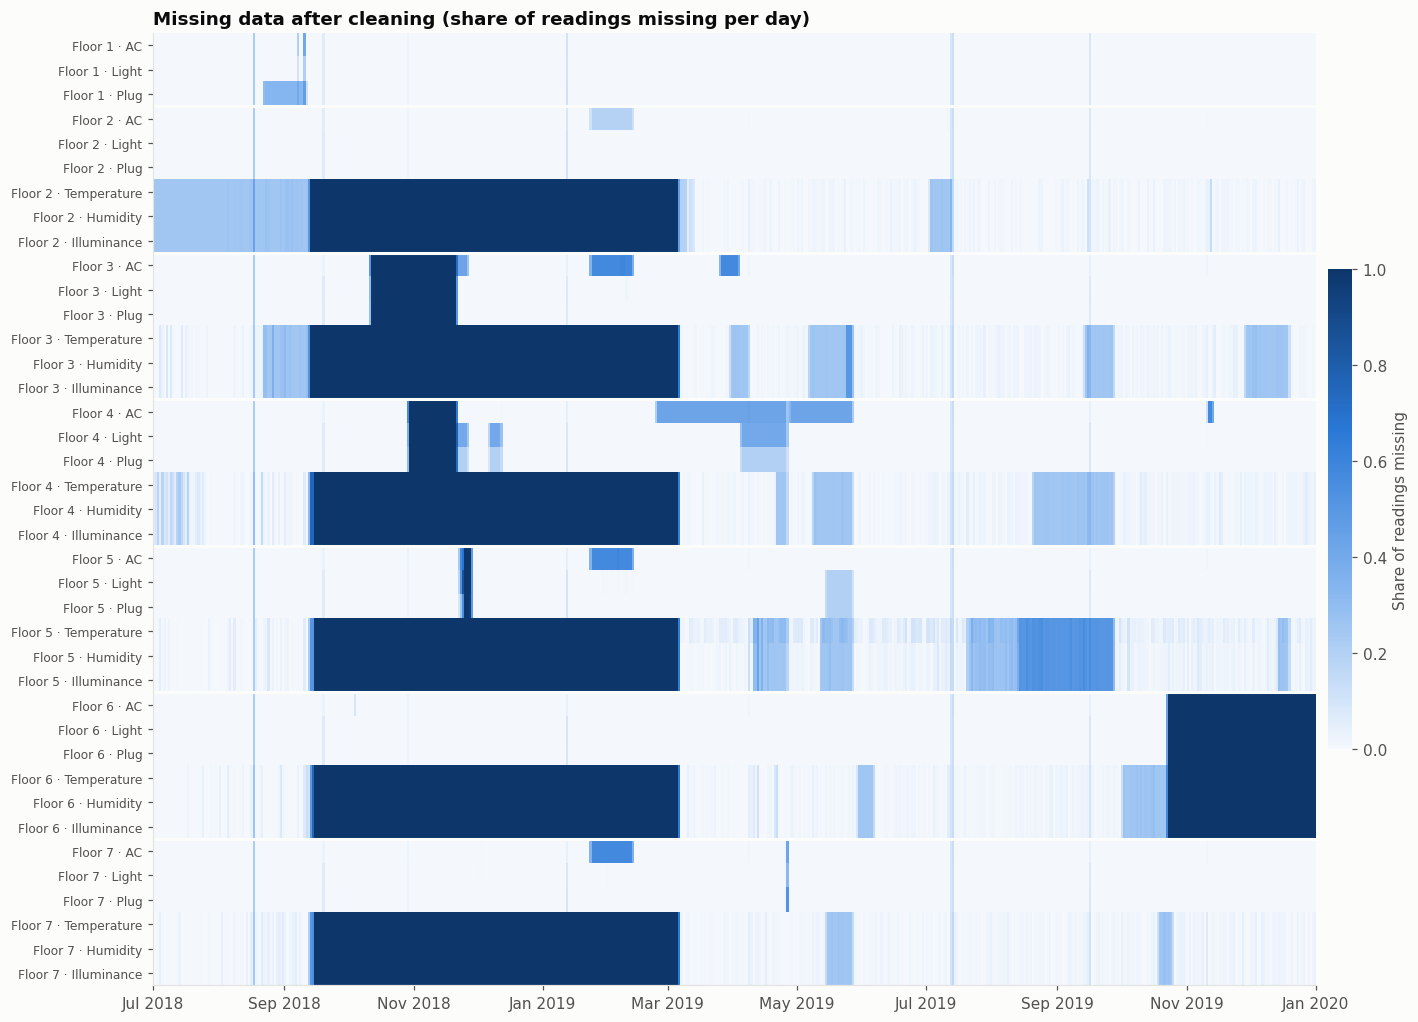

In [46]:
plot_missing(clean, "Missing data after cleaning (share of readings missing per day)", "6_1_missing_heatmap_after")

**Compared with 3.2:**

- **Short dropouts:** the scattered light speckle is gone. The thin vertical lines that remain are outages longer than 15 minutes.
- **Long outages:** the large dark blocks are unchanged, because they were **deliberately left empty** (action 7). Section 6.8 lists them with their causes.
- **Floor 5 temperature:** this row gains some speckle, because the implausible zone 1 readings were removed and not refilled (action 5).

The large blocks can't disappear, because those measurements were never recorded. The goal of cleaning here isn't a fully white chart. It is to make sure every value that remains can be trusted, and that every gap is explained.

### 6.2 Gap lengths after cleaning

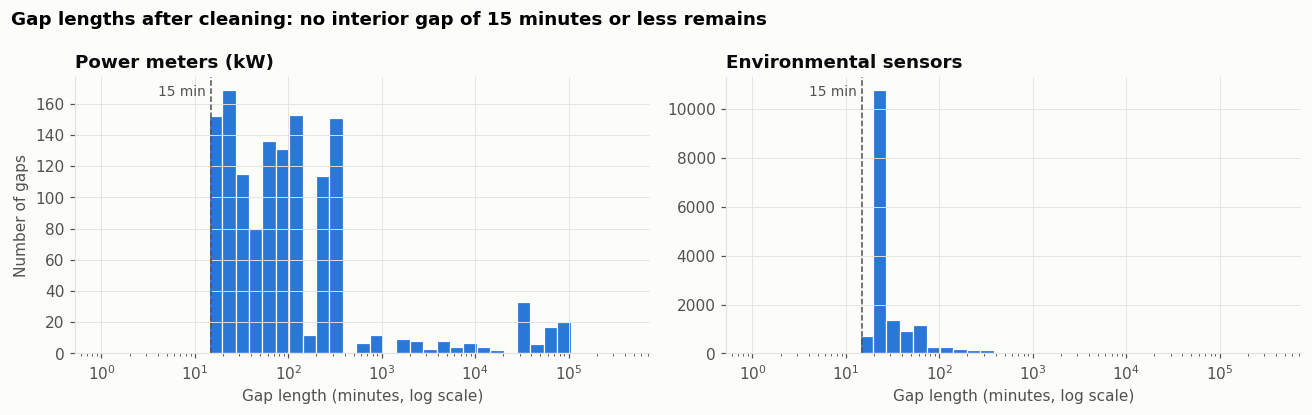

Number of gaps: before 219,095 → after 17,491. Short interior gaps left: 0


In [47]:
gaps_after = all_gaps(clean)
plot_gap_lengths(gaps_after, "Gap lengths after cleaning: no interior gap of 15 minutes or less remains", "6_2_gap_lengths_after")
interior_short = gaps_after[(gaps_after["minutes"] <= MAX_INTERP_GAP_MIN) & ~gaps_after["at_edge"]]
print(f"Number of gaps: before {len(gaps_before):,} → after {len(gaps_after):,}. Short interior gaps left: {len(interior_short)}")

**Compared with 3.3:**

- **Short gaps:** every bar left of the 15-minute line is gone, and the number of gaps falls from **about 219,000 to about 17,500**, a 92% reduction.
- **Long gaps:** everything that remains is longer than 15 minutes, which is what the repair rule intends.

### 6.3 Power spikes after cleaning

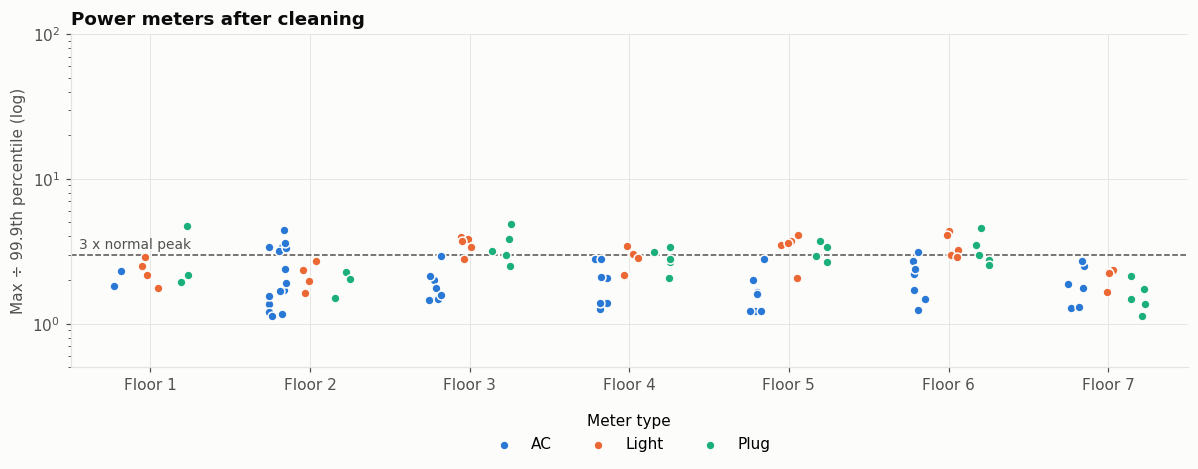

Meters above 3x their normal peak: before 55, after 30
Highest max ÷ normal peak: before 56.1x, after 4.9x


In [48]:
ratios_after = spike_ratios(clean)
plot_spike_ratios(ratios_after, "Power meters after cleaning", "6_3_spike_ratio_after")
print(f"Meters above 3x their normal peak: before {(ratios_before['ratio'] > 3).sum()}, after {(ratios_after['ratio'] > 3).sum()}")
print(f"Highest max ÷ normal peak: before {ratios_before['ratio'].max():.1f}x, after {ratios_after['ratio'].max():.1f}x")

**Compared with 3.4:**

- **Overall:** the cloud of dots far above the line is gone, and the worst meter falls from **56x to under 5x** its normal peak.
- **Floor 3**, previously the worst, now looks like the other floors.
- **What's left:** about 30 meters still sit a little above the 3x line, all below 5x. Their highest reading lasts **longer than 5 minutes**, which fits a real load such as equipment switching on, so it was kept.

### 6.4 The same close-ups after cleaning

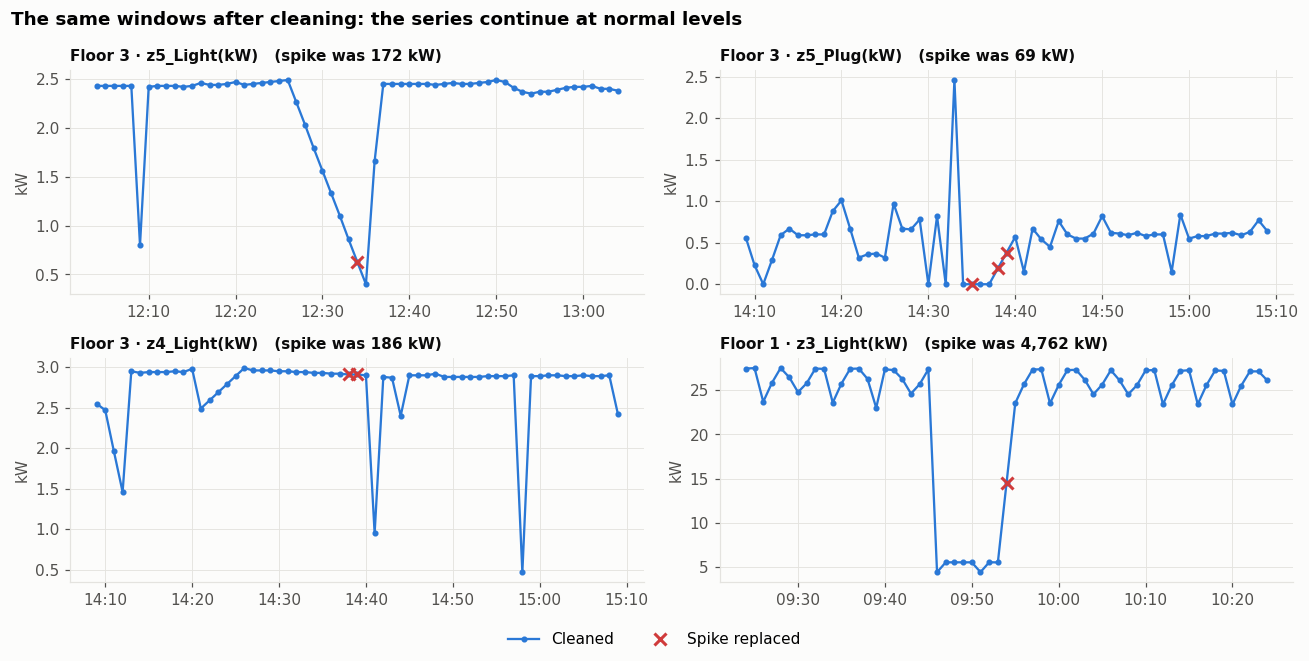

In [49]:
plot_closeups(closeups, raw, clean, "The same windows after cleaning: the series continue at normal levels", "6_4_spike_closeups_after")

**Compared with 3.5:**

- **The spikes are gone:** each red ✕ marks where one was. The value there is now interpolated from its neighbours, so each series continues at its normal level of a few kW, or about 25 kW for Floor 1 lighting.
- **The y-axes:** they now span 0-3 kW or 5-30 kW, instead of hundreds or thousands of kW. That change in scale is the clearest sign the spikes were not real load.
- **Short gaps:** these are filled by straight lines, for example the slope at about 12:30 in the Floor 3 lighting panel.

### 6.5 Environmental values after cleaning

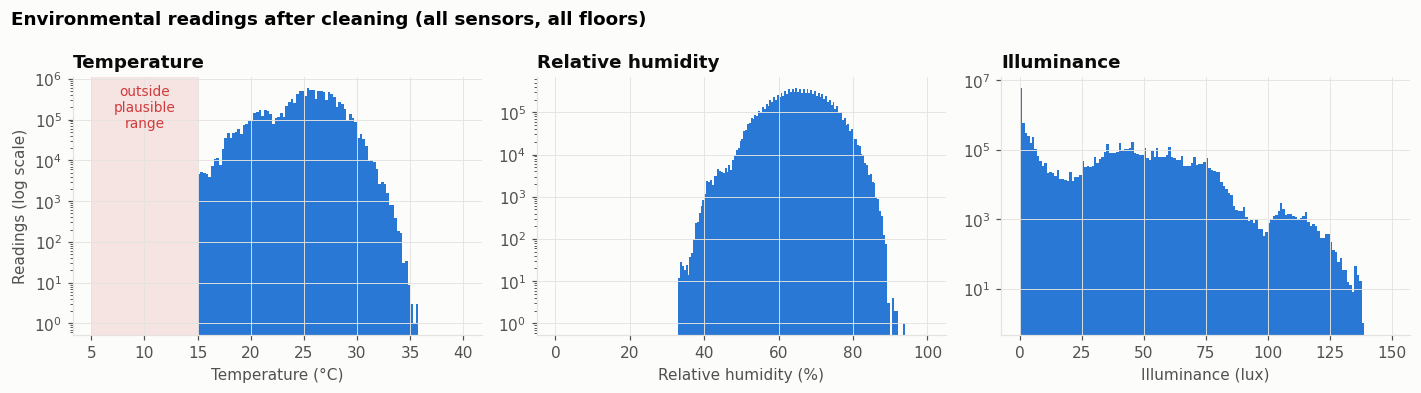

In [50]:
plot_env(clean, "Environmental readings after cleaning (all sensors, all floors)", "6_5_env_hist_after")

**Compared with 3.6:** no temperature reading falls in the shaded area any more. Humidity and lux are unchanged, because they had nothing to fix.

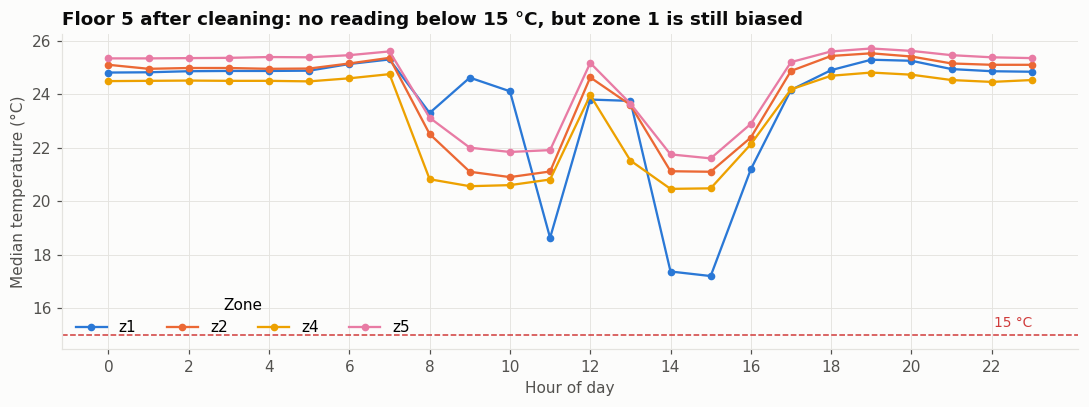

In [51]:
plot_floor5_temperature(clean[5], "Floor 5 after cleaning: no reading below 15 °C, but zone 1 is still biased", "6_5_floor5_temperature_after")

**Compared with 3.7:** the impossible readings are gone, but **Floor 5 zone 1 still can't be trusted in office hours**:

- **Still too cold:** at 14:00-15:00 its median is still about 17 °C, versus about 21 °C in the other zones.
- **A misleading jump:** the apparent rise to about 24 °C at 09:00-10:00 is a *selection effect*. Only the days when the AC was not blowing on the sensor survive the 15 °C rule, so the remaining readings come from those warmer days.

This bias comes from where the sensor is mounted, and no cleaning rule can correct it. Rather than invent a correction, the sensor is flagged in `data_quality.csv` with the advice: **leave Floor 5 zone 1 temperature out of comfort analysis.**

### 6.6 Sample rows: before vs after

**What we're checking:** what exactly happened to individual readings? Each table shows a few minutes of one column, the raw value next to the cleaned value, and the action taken.

**1. A spike replaced**: Floor 1 lighting around the 4,762 kW reading.

In [52]:
before_after(1, "z3_Light(kW)", "2018-09-11 09:51", "2018-09-11 09:57")

,raw,cleaned,action
Date,,,
2018-09-11 09:51:00,4.42,4.42,unchanged
2018-09-11 09:52:00,5.54,5.54,unchanged
2018-09-11 09:53:00,5.52,5.52,unchanged
2018-09-11 09:54:00,4762.43,14.52,spike replaced by interpolation
2018-09-11 09:55:00,23.52,23.52,unchanged
2018-09-11 09:56:00,25.66,25.66,unchanged
2018-09-11 09:57:00,27.33,27.33,unchanged


The 4,762 kW reading is replaced by **14.5 kW**, halfway between the readings on either side (5.5 and 23.5 kW). Every other minute is unchanged.

**2. A short gap filled**: the first gap of 3-5 minutes on Floor 2's lighting meters.

In [53]:
short_gap = gaps_before[(gaps_before["floor"] == 2) & gaps_before["column"].str.contains("Light")
                        & gaps_before["minutes"].between(3, 5) & ~gaps_before["at_edge"]].iloc[0]
start = short_gap["start"] - pd.Timedelta(minutes=2)
end = short_gap["start"] + pd.Timedelta(minutes=int(short_gap["minutes"]) + 1)
print(f"Floor 2 · {short_gap['column']}: {int(short_gap['minutes'])}-minute gap starting {short_gap['start']}")
before_after(2, short_gap["column"], start, end)

Floor 2 · z1_Light(kW): 3-minute gap starting 2018-12-28 11:00:00


,raw,cleaned,action
Date,,,
2018-12-28 10:58:00,8.24,8.24,unchanged
2018-12-28 10:59:00,8.24,8.24,unchanged
2018-12-28 11:00:00,NaN,6.31,gap filled by interpolation
2018-12-28 11:01:00,NaN,4.38,gap filled by interpolation
2018-12-28 11:02:00,NaN,2.46,gap filled by interpolation
2018-12-28 11:03:00,0.53,0.53,unchanged
2018-12-28 11:04:00,2.02,2.02,unchanged


The missing minutes are filled with evenly spaced values on a straight line between the last reading before the gap and the first reading after it. The real readings either side are untouched.

**3. An implausible value removed**: Floor 5 zone 1 temperature on its coldest morning.

In [54]:
before_after(5, "z1_S1(degC)", f"{coldest_day} 10:00", f"{coldest_day} 10:05")

,raw,cleaned,action
Date,,,
2019-07-03 10:00:00,11.60,NaN,removed (left blank)
2019-07-03 10:01:00,11.57,NaN,removed (left blank)
2019-07-03 10:02:00,11.55,NaN,removed (left blank)
2019-07-03 10:03:00,11.52,NaN,removed (left blank)
2019-07-03 10:04:00,11.50,NaN,removed (left blank)
2019-07-03 10:05:00,11.52,NaN,removed (left blank)


Readings below 15 °C become empty and are **not** refilled. Filling them would mean inventing a temperature the sensor never measured correctly.

**4. A long gap left blank**: the moment the 2019 Floor 6 file stops.

In [55]:
before_after(6, "z1_Light(kW)", "2019-10-22 13:24", "2019-10-22 13:31")

,raw,cleaned,action
Date,,,
2019-10-22 13:24:00,3.47,3.47,unchanged
2019-10-22 13:25:00,3.46,3.46,unchanged
2019-10-22 13:26:00,3.46,3.46,unchanged
2019-10-22 13:27:00,3.46,3.46,unchanged
2019-10-22 13:28:00,NaN,NaN,still missing (long gap)
2019-10-22 13:29:00,NaN,NaN,still missing (long gap)
2019-10-22 13:30:00,NaN,NaN,still missing (long gap)
2019-10-22 13:31:00,NaN,NaN,still missing (long gap)


Real readings continue up to 13:27. After that, the minutes exist in the timeline but stay empty, because the gap lasts about 70 days, far beyond the 15-minute repair limit.

### 6.7 Automated checks

**What we're checking:** six rules every cleaned floor must satisfy, so that the cleaning is verified by code and not just by eye. The last one tests the "don't delete the unusual" principle: closure days must look exactly as they did before cleaning.

In [56]:
def check(name, passed, detail=""):
    return {"check": name, "result": "PASS" if passed else "FAIL", "detail": detail}

respike = sum(int(detect_spikes(clean[f][c]).sum()) for f in FLOORS for c in clean[f].columns if column_info(c)["unit"] == "kW")
special_days = day_info.index[day_info["day_type"] == "closure"]
day_info_after = daily_activity(clean)
activity_change = (day_info_after.loc[special_days, "activity"] - day_info.loc[special_days, "activity"]).abs().max()
closures_kept = (day_info_after.loc[special_days, "day_type"] == day_info.loc[special_days, "day_type"]).all() and activity_change < 0.05
out_of_range = sum(int(implausible(clean[f][c], column_info(c)["unit"]).sum()) for f in FLOORS for c in clean[f].columns)

pd.DataFrame([
    check("Every floor has a complete 1-minute timeline", all(clean[f].index.equals(FULL_INDEX) for f in FLOORS),
          f"{len(FULL_INDEX):,} minutes per floor"),
    check("No duplicate timestamps", all(not clean[f].index.duplicated().any() for f in FLOORS)),
    check("All values within valid ranges", out_of_range == 0, f"{out_of_range} out of range"),
    check("Spike detector finds no spikes in the cleaned data", respike == 0, f"{respike} flagged"),
    check(f"No interior gaps of {MAX_INTERP_GAP_MIN} minutes or less", len(interior_short) == 0, f"{len(interior_short)} found"),
    check("Closure days kept (unusual operation not deleted)", closures_kept,
          f"{len(special_days)} days; largest activity change {activity_change:.3f}"),
])

,check,result,detail
0,Every floor has a complete 1-minute timeline,PASS,"790,560 minutes per floor"
1,No duplicate timestamps,PASS,
2,All values within valid ranges,PASS,0 out of range
3,Spike detector finds no spikes in the cleaned ...,PASS,0 flagged
4,No interior gaps of 15 minutes or less,PASS,0 found
5,Closure days kept (unusual operation not deleted),PASS,28 days; largest activity change 0.001


**What this shows:** all six checks pass:

- **Timeline:** complete, with no duplicates.
- **Ranges:** no value is outside its valid range.
- **Spikes:** running the detector again finds nothing.
- **Gaps:** every short gap has been repaired.
- **Unusual operation:** every closure day is still there, with its activity essentially unchanged.

### 6.8 Missing data that remains, and why

**What we're checking:** how much data is still missing per floor and type after cleaning, compared with before?

In [57]:
remaining = (cleaning_log.groupby(["floor", "type"])
             .agg(before=("raw_missing_min", "sum"), after=("final_missing_min", "sum"), columns=("column", "count")))
remaining[["before", "after"]] = remaining[["before", "after"]].div(remaining["columns"] * len(FULL_INDEX), axis=0).mul(100).round(1)
remaining.drop(columns="columns").unstack("type").reindex(columns=TYPES, level="type")

before                                              after                                             
type      AC Light  Plug Temperature Humidity Illuminance    AC Light  Plug Temperature Humidity Illuminance
floor                                                                                                       
1        0.3   0.2   1.4         NaN      NaN         NaN   0.2   0.2   1.4         NaN      NaN         NaN
2        0.9   0.2   0.1        36.9     36.9        36.9   0.8   0.1   0.1        36.5     36.5        36.5
3       11.3   7.8   7.6        37.4     37.4        37.4  11.1   7.5   7.5        36.9     36.9        36.9
4       12.0   6.9   5.6        36.6     36.6        36.6  11.8   6.8   5.5        36.0     36.0        36.0
5        3.6   2.1   1.6        40.4     40.4        40.4   3.1   1.5   1.4        40.8     39.9        39.9
6       13.1  13.0  13.0        47.1     47.1        47.1  13.0  13.0  13.0        46.6     46.6        46.6
7        2.5   0.5   0.5        34.1     34.1        34.1   2.3   0.2   0.2        33.5     33.5        33.5

**How to read it:** the percentage of readings missing, before and after cleaning, for each floor and measurement type.

**What this shows:**

- **Overall:** the percentages fall only slightly (e.g. Floor 2 temperature, 36.9% → 36.5%). As 3.3 predicted, the repaired short gaps were a tiny share of the missing time.
- **Power data:** Floors 1, 2, 5 and 7 are 97-100% complete. Floors 3, 4 and 6 are about 87-89% complete because of their long outages.
- **Environmental data** is 53-67% complete, limited mainly by the building-wide sensor outage.
- **Floor 5 temperature** rises slightly (40.4% → 40.8%), because the implausible readings were removed.

**Why the remaining gaps exist:**

| Gap | Cause | Effect on analysis |
|---|---|---|
| All environmental sensors, 12-15 Sep 2018 → 6 Mar 2019 (~175 days) | Building-wide sensor outage | Comfort analysis is limited to Jul-Sep 2018 and Mar-Dec 2019 |
| Floor 2 zone 4 sensor, Jul 2018 → 6 Mar 2019 | Sensor not reporting from the start | No 2018 comfort data for this zone |
| Individual sensors in 2019 (e.g. Floor 5 zones 1-2, Jul/Aug → 27 Sep; Floor 4 zone 4, 20 Aug → 27 Sep) | Single-sensor outages | Those zones lack comfort data for 3-10 weeks |
| One AC meter per zone on Floors 2, 3, 5, 7, 23 Jan → 12 Feb 2019 | AC meter outage | Floor and building AC totals are blank for these 3 weeks |
| Floor 3, 11 Oct → 26 Nov 2018; Floor 4, 29 Oct → 26 Nov 2018 | Whole-floor logger outages | Those floors and the building totals are blank for these periods |
| Floor 4 zone 1 AC, 23 Feb → 27 May 2019 | Meters offline | Floor 4 AC and total kW are blank for these periods |
| Floor 6, 22 Oct → 31 Dec 2019 | Source file truncated | Floor 6 and the building totals are blank for this period |
| Floor 5 zone 1 temperature, office hours | Implausible readings removed | Leave this sensor out of comfort analysis |
| Hour-long outages on every floor (e.g. 17 Aug 2018, 12 Jul 2019) | Logger outages | Those intervals are blank. `coverage_pct` shows where data is incomplete. |

## 7. Export

The cleaned data is saved in two forms:

1. **`outputs/clean/`**: the same 14 files in their original format. Existing code that reads the raw files only needs a new folder path.
2. **`outputs/analytics/`**: combined tables that make common smart-building questions easy to answer.

### 7.1 Cleaned files in the original format

These keep the same file names, the same columns in the same order, and values rounded to 2 decimal places, as in the source. Three things differ from the raw files:

- **Dates:** every file uses `YYYY-MM-DD HH:MM:SS`, including 2019 Floor 7.
- **Timeline:** every minute of the period has a row. 2019 Floor 6 gains blank rows from 22 Oct to 31 Dec.
- **Values:** the cleaning from Step 5 is applied.

In [58]:
export_rows = []
for (y, f), source in sorted(raw_files.items()):
    out = clean[f].loc[PERIOD[y][0]:PERIOD[y][1], list(source.columns[1:])].reset_index()
    out["Date"] = out["Date"].dt.strftime("%Y-%m-%d %H:%M:%S")
    path = CLEAN_DIR / f"{y}Floor{f}.csv"
    out.to_csv(path, index=False)
    export_rows.append({"file": str(path), "rows": len(out), "columns": out.shape[1], "size_MB": round(path.stat().st_size / 1e6, 1)})
pd.DataFrame(export_rows)

,file,rows,columns,size_MB
0,outputs\clean\2018Floor1.csv,264960,12,20.8
1,outputs\clean\2018Floor2.csv,264960,37,41.6
2,outputs\clean\2018Floor3.csv,264960,30,30.6
3,outputs\clean\2018Floor4.csv,264960,30,32.2
4,outputs\clean\2018Floor5.csv,264960,30,34.1
5,outputs\clean\2018Floor6.csv,264960,30,34.7
6,outputs\clean\2018Floor7.csv,264960,30,34.9
7,outputs\clean\2019Floor1.csv,525600,12,41.0
8,outputs\clean\2019Floor2.csv,525600,37,96.4
9,outputs\clean\2019Floor3.csv,525600,30,78.0


**What this shows:** all 14 files are written with the expected number of rows, and 2019 Floor 6 now has its full 525,600.

### 7.2 Combined analytics tables

| File | One row per | Use it for |
|---|---|---|
| `floor_15min.csv` | Floor x 15 minutes | Comparing floors, and finding which floor drives the building peak |
| `building_15min.csv` | 15 minutes, whole building | Peak-demand analysis. 15 minutes is the utility's demand-billing interval. |
| `zone_hourly.csv` | Zone x hour | Comfort against energy: temperature, humidity and lux alongside AC, lighting and plug power |
| `daily_summary.csv` | Floor x day | Trends, weekday vs weekend, daily energy (kWh) and peak |
| `data_quality.csv` | Source column | How much of each column was missing, removed or filled, plus notes on known problems |
| `removed_readings.csv` | Removed reading | Audit trail: every reading the cleaning removed, with its original value and reason (`spike` or `implausible`) |

**Rules used to build them:**

- **Type totals:** a floor's AC, Light or Plug total for a minute is counted only when **every** meter of that type reports. Otherwise a missing meter would make the total look lower than it really was.
- **Coverage:** an interval is left blank when less than **80%** of its minutes are valid. `coverage_pct` records the share.
- **Energy:** kWh = average kW x hours, so a 15-minute interval gives kW x 0.25.
- **Calendar columns:** `hour`, `weekday`, `is_weekend` and `month` are added, plus `day_type` from 3.9 (working day, weekend or closure), so later analyses can filter easily.

**Choosing the resolution:** this answers the *too much data* problem by asking "what resolution is actually useful for the decision?"

| Decision | Useful resolution | Table |
|---|---|---|
| Peak demand and demand charges | 15 minutes (the utility's demand-billing interval) | `building_15min`, `floor_15min` |
| Comfort vs energy in a zone | 1 hour (room temperature changes slowly) | `zone_hourly` |
| Trends, baselines, weekday vs weekend | 1 day | `daily_summary` |

In [59]:
floor_15min = build_floor_15min(clean)
building_15min = build_building_15min(floor_15min)
zone_hourly = build_zone_hourly(clean)
daily_summary = build_daily_summary(floor_15min)
data_quality = build_data_quality(cleaning_log, gaps_after)

pd.DataFrame({
    "rows": {name: len(t) for name, t in [("floor_15min", floor_15min), ("building_15min", building_15min),
                                          ("zone_hourly", zone_hourly), ("daily_summary", daily_summary), ("data_quality", data_quality)]},
})

,rows
floor_15min,368928
building_15min,52704
zone_hourly,434808
daily_summary,3843
data_quality,192


In [60]:
building_15min.head()

,Date,ac_kW,light_kW,plug_kW,total_kW,total_kWh,floors_reporting,hour,weekday,is_weekend,month,day_type
0,2018-07-01 00:00:00,61.379,74.284,39.891,175.555,43.889,7,0,Sunday,True,7,weekend
1,2018-07-01 00:15:00,61.459,74.417,39.509,175.385,43.846,7,0,Sunday,True,7,weekend
2,2018-07-01 00:30:00,61.521,74.799,40.641,176.962,44.240,7,0,Sunday,True,7,weekend
3,2018-07-01 00:45:00,61.753,75.011,40.426,177.189,44.297,7,0,Sunday,True,7,weekend
4,2018-07-01 01:00:00,61.960,75.052,40.576,177.587,44.397,7,1,Sunday,True,7,weekend


In [61]:
completeness = floor_15min.groupby("floor")["total_kW"].apply(lambda s: s.notna().mean() * 100).round(1)
completeness["building"] = round(building_15min["total_kW"].notna().mean() * 100, 1)
completeness.rename("share of 15-min intervals with a total (%)").to_frame().T

floor,1,2,3,4,5,6,7,building
share of 15-min intervals with a total (%),96.2,96.2,86.0,76.2,92.7,87.0,96.0,52.8


**What this shows:**

- **Each floor:** a valid 15-minute total is available for 76-96% of the period. Floor 4 is lowest because of its long outages and missing zone 1 AC meters.
- **The whole building:** a total is available for only about **53%** of intervals, because it needs all 7 floors to report fully at the same time, and each floor's outages fall on different dates.

**Practical advice:** for building-level peak demand, use the periods where `floors_reporting == 7`. To compare floors, use `floor_15min`, which keeps much more data.

In [62]:
tables = {"floor_15min": floor_15min, "building_15min": building_15min, "zone_hourly": zone_hourly,
          "daily_summary": daily_summary, "data_quality": data_quality, "removed_readings": removed_readings}
written = []
for name, table in tables.items():
    path = ANALYTICS_DIR / f"{name}.csv"
    table.to_csv(path, index=False)
    written.append({"file": str(path), "rows": len(table), "columns": table.shape[1], "size_MB": round(path.stat().st_size / 1e6, 2)})
pd.DataFrame(written)

,file,rows,columns,size_MB
0,outputs\analytics\floor_15min.csv,368928,13,32.01
1,outputs\analytics\building_15min.csv,52704,12,4.01
2,outputs\analytics\zone_hourly.csv,434808,14,33.03
3,outputs\analytics\daily_summary.csv,3843,13,0.31
4,outputs\analytics\data_quality.csv,192,13,0.02
5,outputs\analytics\removed_readings.csv,34422,5,1.82


### 7.3 Using the cleaned data correctly

Every analysis built on these files should follow these rules:

1. **Build baselines from clean, normal days only.** Filter to `day_type == "working day"` (or `"weekend"` for a weekend baseline) and `coverage_pct >= 80`. Closure days would otherwise drag the baseline down.
2. **Train on the baseline period and test on the reporting period.** Never fit a baseline on the period being evaluated, or post-change behaviour leaks into it. For example, if March 2019 is the baseline and April 2019 the test period, the four weekday closures in April (8, 12, 15 and 16 April) must be left out of both, and all of them are labelled here.
3. **Check `data_quality.csv` before using a column.** `final_missing_pct` says how complete the column is, and `note` flags known problems (Floor 5 zone 1 temperature, lux placement).
4. **Normalise where possible, and say where it isn't.** The dataset has no weather or occupancy data, so comparisons between periods can't be weather- or occupancy-normalised. Compare like with like (same `day_type`, similar months) instead, and state the limitation.
5. **Investigate before concluding.** An unusual value in the cleaned data (e.g. high night-time load) is evidence to investigate, not proof of waste. Check the day type, whether it persists, and the column's data quality.

### 7.4 Loading the cleaned data in another notebook

```python
import pandas as pd

# Original format (one floor, one year)
df = pd.read_csv("data-cleaning/outputs/clean/2019Floor2.csv", parse_dates=["Date"], index_col="Date")

# Combined tables
building = pd.read_csv("data-cleaning/outputs/analytics/building_15min.csv", parse_dates=["Date"])
quality = pd.read_csv("data-cleaning/outputs/analytics/data_quality.csv")
```

**Before analysing a sensor or meter,** check its row in `data_quality.csv`: `final_missing_pct` says how complete it is, and `note` flags known problems such as Floor 5 zone 1 temperature.

## 8. Assumptions and limitations

Cleaning is only trustworthy if its assumptions are visible. These are all the assumptions this notebook makes:

| # | Assumption | Why it's reasonable | If it's wrong |
|---|---|---|---|
| 1 | Timestamps are Bangkok local time (UTC+7), with no clock offset between floors | A building-wide outage starts within the same minute on every floor (1.6), and Thailand has no daylight saving | Times of day such as office hours would shift |
| 2 | 2019 Floor 7 dates are day-first | It's the only reading that gives a complete, ordered timeline (3.1) | Verified, so not a real risk |
| 3 | Temperatures below 15 °C are invalid | Offices aren't cooled this far, the cold readings come from one sensor only while the AC runs (3.7), and 15 °C is the highest limit that touches only that sensor (4.3 C) | A little real Floor 5 zone 1 data would be lost |
| 4 | A spike is extreme (above 3x normal peak and 5x its surrounding hour) **and** brief (5 minutes or less) | Logger bursts last up to 5 minutes, while real loads last longer (Step 4) | A very short real load would be removed, but each removal is logged in `removed_readings.csv` and can be checked |
| 5 | Gaps of 15 minutes or less can be filled with a straight line, using one limit for every measurement | Tested at about 12% of load (power) or 0.07 °C (temperature) average error, and 15 minutes is the demand-billing interval (4.3 B). Temperature alone could tolerate a longer limit. | Small errors in the repaired minutes (0.3% of readings) |
| 6 | Long gaps are left blank rather than estimated | There is nothing nearby to estimate from | None, since no data is invented |
| 7 | A combined-table interval needs at least 80% of its readings | Balances completeness against keeping enough data | A lower threshold keeps more intervals, with more uncertainty |
| 8 | A weekday using less than half a normal day's energy is a closure | There is a clear gap between closures (≤ 0.38) and working days (≥ 0.73), so the exact threshold doesn't matter (3.9) | A partial closure above 0.5 would count as a working day |
| 9 | Closure days are real closures, not metering faults | On these days each floor behaves exactly as it does at weekends, and its meters keep reporting (3.9) | The reason for each closure isn't confirmed against an outside source. If one were a fault, it would wrongly be kept as real data. |
| 10 | Removed spikes are logging errors, not real loads | Up to 56x normal peak, lasting only 1-5 minutes, usually right after a logger gap, and sometimes on several meters at once (3.5) | Not confirmed by maintenance or logger records (none available). Every removed value is kept in `removed_readings.csv`, so the decision can be reviewed or reversed. |

**Limitations that cleaning can't fix:**

- **Missing data:** about 175 days of environmental data, the end of 2019 for Floor 6, and several weeks of whole-floor power data are missing (6.8).
- **Floor 5 zone 1 temperature:** biased by where the sensor is mounted, so leave it out of comfort analysis.
- **Lux readings:** these show relative changes only, not desk-level illuminance.
- **No weather or occupancy data:** results can't be normalised for either.

## 9. Before vs after: side-by-side comparison

This final section puts each **before** chart (raw data, left) next to its **after** chart (cleaned data, right), drawn **on the same axes**, so the effect of the cleaning can be seen at a glance. **Red circles** mark where the two charts differ. They are placed by code from the data, not by hand, so they stay correct if a cleaning setting is changed and the notebook re-run. Every figure is also saved to `outputs/figures/` (files starting with `9_`) for use in the report.

### 9.1 The cleaning in numbers

In [63]:
kw_cols = cleaning_log["unit"] == "kW"
def missing_pct(col, rows):
    return round(cleaning_log.loc[rows, col].sum() / (rows.sum() * len(FULL_INDEX)) * 100, 2)
def short_interior(g):
    return int(((g["minutes"] <= MAX_INTERP_GAP_MIN) & ~g["at_edge"]).sum())
def below_15(frames):
    return int(sum((frames[f][c] < 15).sum() for f in FLOORS for c in cols_of(frames[f], "Temperature")))

pd.DataFrame([
    ("Gaps (runs of missing minutes)", len(gaps_before), len(gaps_after)),
    (f"Gaps of {MAX_INTERP_GAP_MIN} minutes or less", short_interior(gaps_before), short_interior(gaps_after)),
    ("Power readings missing (%)", missing_pct("raw_missing_min", kw_cols), missing_pct("final_missing_min", kw_cols)),
    ("Sensor readings missing (%)", missing_pct("raw_missing_min", ~kw_cols), missing_pct("final_missing_min", ~kw_cols)),
    ("Spike readings", int((removed_readings["reason"] == "spike").sum()), respike),
    ("Power meters above 3x their normal peak", int((ratios_before["ratio"] > 3).sum()), int((ratios_after["ratio"] > 3).sum())),
    ("Highest max ÷ normal peak", round(ratios_before["ratio"].max(), 1), round(ratios_after["ratio"].max(), 1)),
    ("Temperature readings below 15 °C", below_15(raw), below_15(clean)),
    ("Closure days (unusual operation, kept)", len(special_days), int((day_info_after["day_type"] == "closure").sum())),
], columns=["measure", "before", "after"], dtype=object).set_index("measure") \
  .map(lambda v: f"{v:,}" if isinstance(v, (int, np.integer)) else f"{v:,.2f}".rstrip("0").rstrip("."))

,before,after
measure,,
Gaps (runs of missing minutes),"219,095","17,491"
Gaps of 15 minutes or less,"202,184",0
Power readings missing (%),5.09,4.93
Sensor readings missing (%),38.75,38.29
Spike readings,450,0
Power meters above 3x their normal peak,55,30
Highest max ÷ normal peak,56.1,4.9
Temperature readings below 15 °C,"33,972",0
"Closure days (unusual operation, kept)",28,28


**What this shows:**

- **Gaps:** the number of gaps falls by more than 90%, and no short gap is left.
- **Missing percentages:** these barely move, because the repaired gaps were tiny. Long outages are left blank on purpose.
- **Spikes and implausible temperatures:** both go to zero.
- **Closure days:** all are kept unchanged.

### 9.2 Missing data

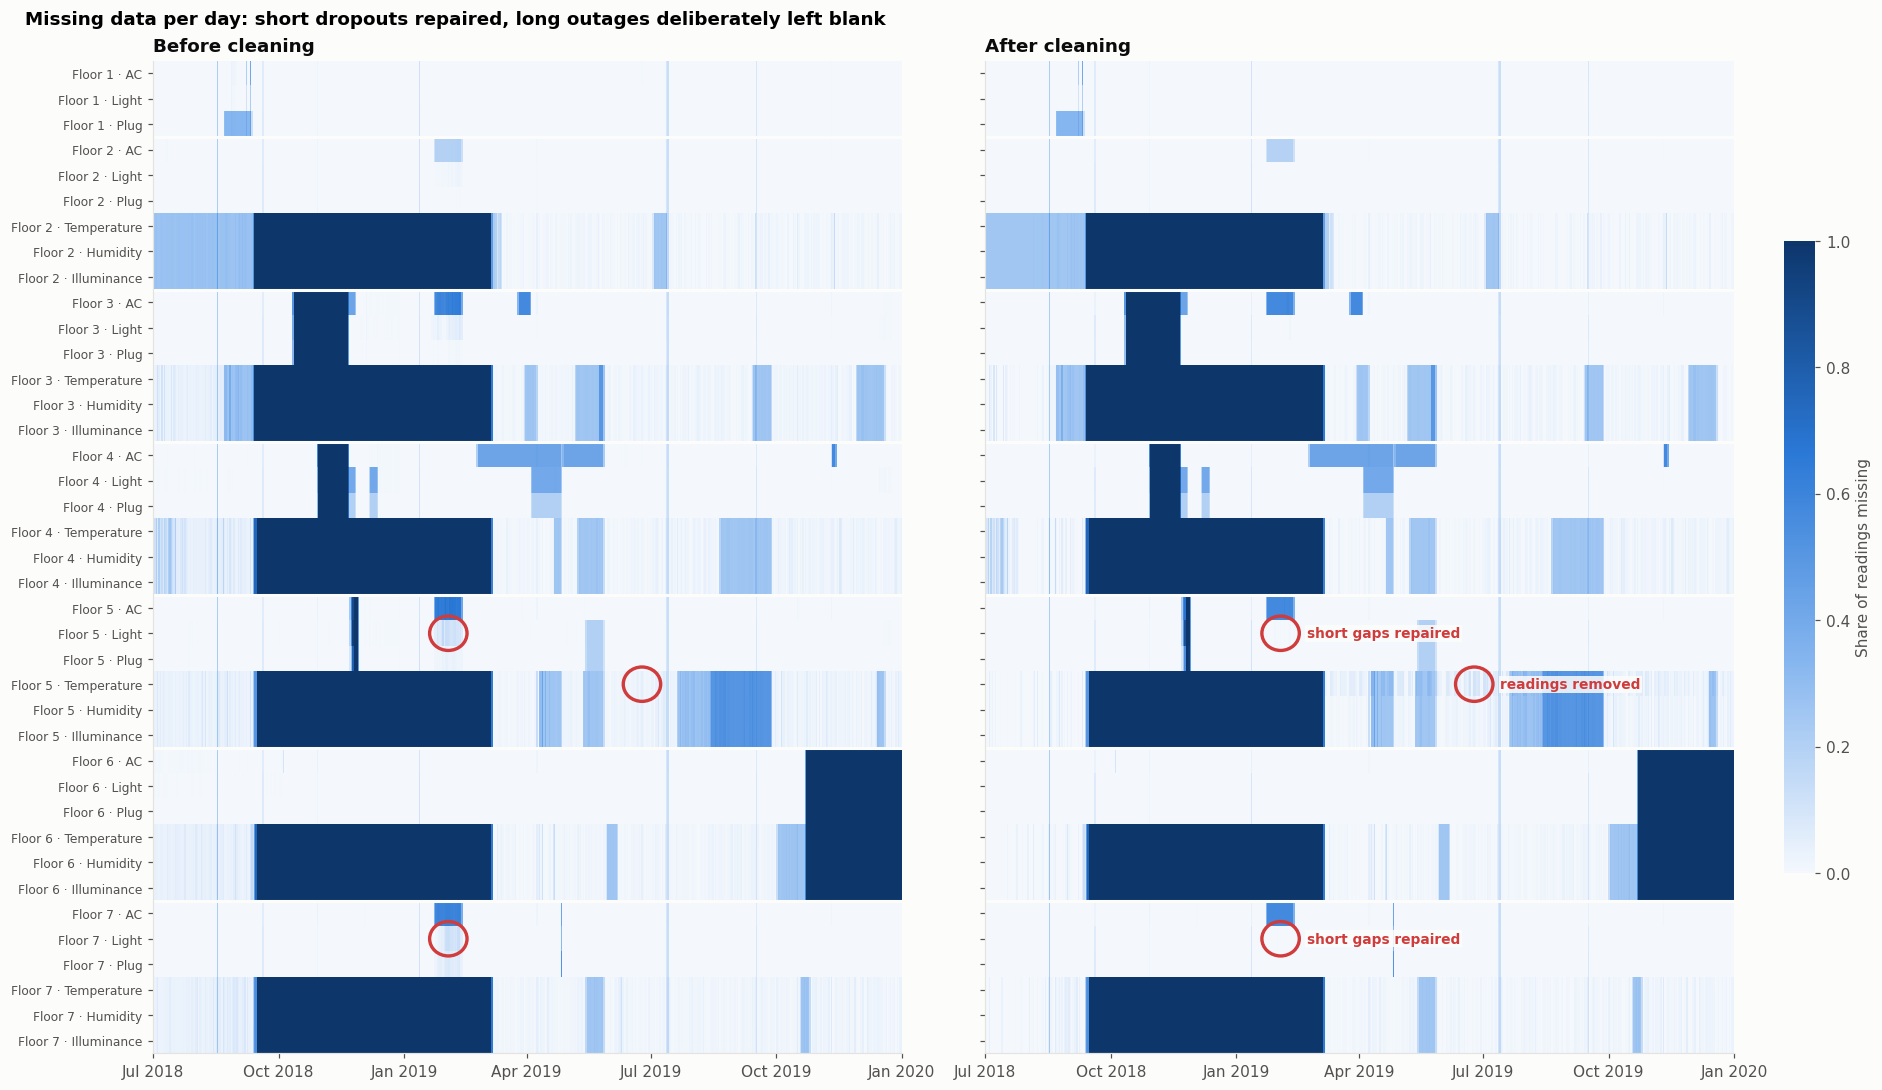

In [64]:
matrix_before, matrix_after = missing_matrix(raw), missing_matrix(clean)
fig, axes = plt.subplots(1, 2, figsize=(17, 0.2 * len(matrix_before) + 2), sharey=True, layout="constrained")
for ax, matrix, title in [(axes[0], matrix_before, "Before cleaning"), (axes[1], matrix_after, "After cleaning")]:
    im = draw_missing(ax, matrix)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.set_title(title)
missing_colorbar(fig, im, axes)
ENV_TYPES = ("Temperature", "Humidity", "Illuminance")
labels = matrix_before.index
for pick in biggest_changes(matrix_before, matrix_after):
    floor, mtype = labels[pick["row"]].split(" · ")
    rows = [pick["row"]]
    if pick["net"] > 0 and mtype in ENV_TYPES:  # the three readings of one sensor are repaired together
        rows = [i for i, l in enumerate(labels) if l.startswith(floor + " · ") and l.split(" · ")[1] in ENV_TYPES]
    for ax in axes:
        circle(ax, mdates.date2num(pick["start"]), mdates.date2num(pick["end"] + pd.Timedelta("1D")), min(rows), max(rows) + 1,
               label=("short gaps repaired" if pick["net"] > 0 else "readings removed") if ax is axes[1] else None,
               side="right", min_h=0.02)
fig.suptitle("Missing data per day: short dropouts repaired, long outages deliberately left blank", x=0.01, ha="left", fontweight="bold")
save(fig, "9_2_missing_side_by_side"); plt.show()

**Compared side by side:**

- **Red circles:** the three places where the two charts differ most, found by comparing them day by day. Each is labelled with what changed there.
- **The two look almost the same, and that is expected.** The short gaps that were repaired held only 1-3% of the missing time (3.3), so at the scale of a whole day they barely change the colour.
- **Remaining speckle:** most of the speckle that remains comes from sensor gaps of 20-30 minutes, just over the 15-minute repair limit, so they were deliberately left. The gap-length comparison in 9.3 shows the repair much more clearly.
- **Long outages:** the large dark blocks are identical in both, because those outages were never recorded and nothing was invented to fill them.
- **Floor 5 temperature:** this is the one row that gets slightly *more* speckled, because the implausible readings were removed.

### 9.3 Gap lengths

The y-axis is on a log scale here, so the small number of gaps left after cleaning is still visible next to the tens of thousands before.

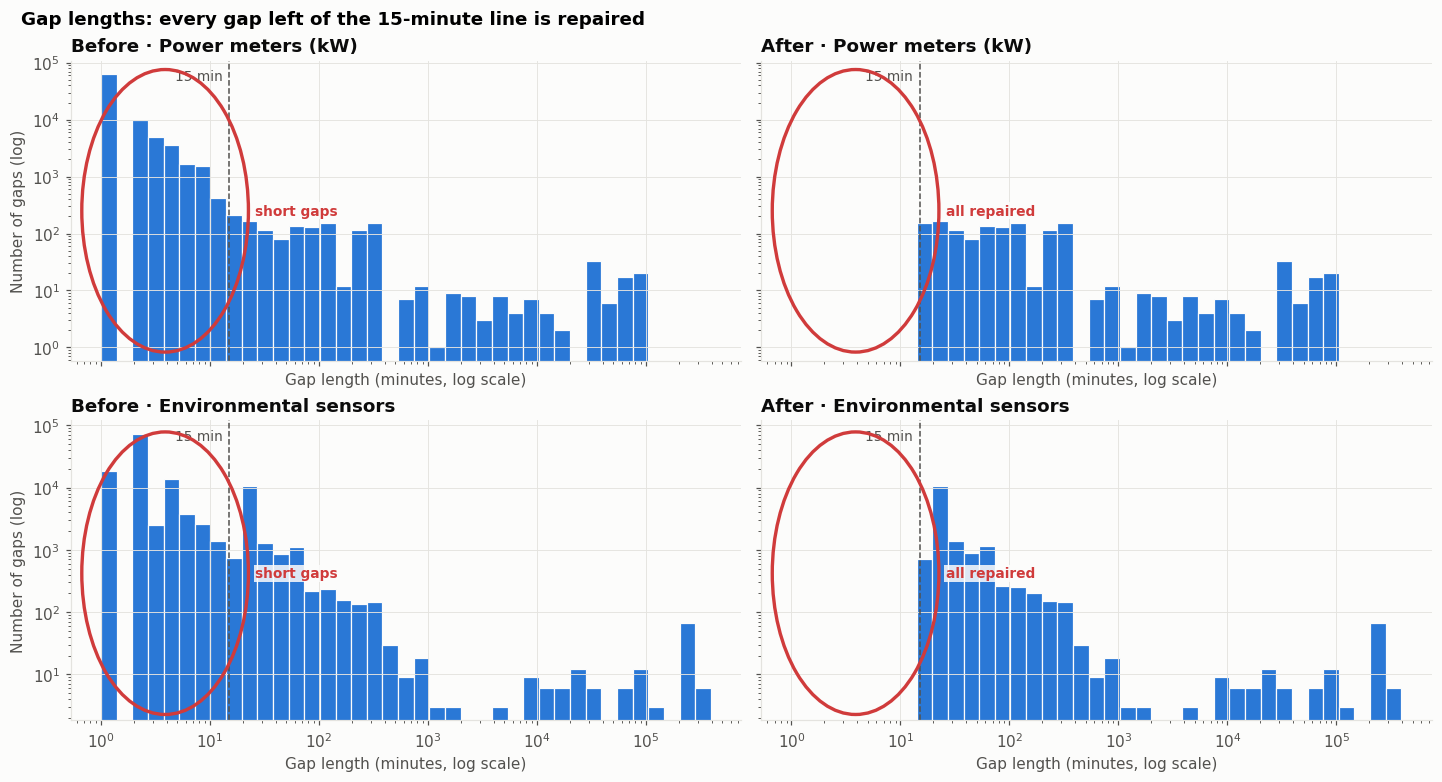

In [65]:
bins = gap_bins(gaps_before, gaps_after)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey="row", layout="constrained")
for r, group in enumerate(GAP_GROUPS):
    for c, (gaps, label) in enumerate([(gaps_before, "Before"), (gaps_after, "After")]):
        draw_gap_lengths(axes[r, c], gaps, group, bins)
        axes[r, c].set_yscale("log")
        axes[r, c].set_title(f"{label} · {group}")
    axes[r, 0].set_ylabel("Number of gaps (log)")
    short = gaps_before.loc[(gaps_before["group"] == group) & (gaps_before["minutes"] <= MAX_INTERP_GAP_MIN), "minutes"]
    tallest = np.histogram(short, bins=bins)[0].max()
    circle(axes[r, 0], 1, MAX_INTERP_GAP_MIN, 1, tallest, label="short gaps", side="right")
    circle(axes[r, 1], 1, MAX_INTERP_GAP_MIN, 1, tallest, label="all repaired", side="right")
fig.suptitle("Gap lengths: every gap left of the 15-minute line is repaired", x=0.01, ha="left", fontweight="bold")
save(fig, "9_3_gap_lengths_side_by_side"); plt.show()

**Compared side by side:** the red circles mark the short gaps. For both power meters and sensors, all the bars left of the 15-minute line disappear, while the bars to the right are unchanged. This is exactly the repair rule from Step 4.

### 9.4 Power spikes

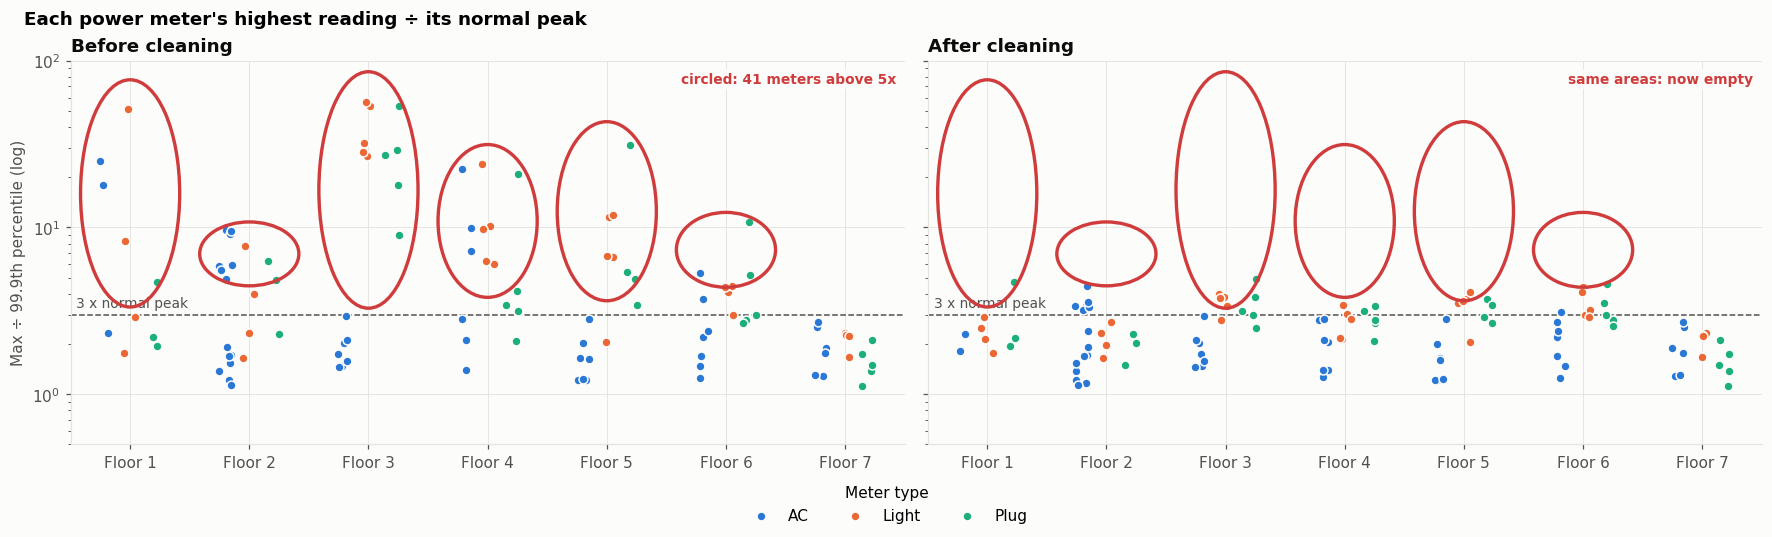

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True, layout="constrained")
for ax, ratios, title in [(axes[0], ratios_before, "Before cleaning"), (axes[1], ratios_after, "After cleaning")]:
    draw_spike_ratios(ax, ratios)
    ax.set_title(title)
axes[1].set_ylabel("")
extreme = ratios_before[(ratios_before["ratio"] > 5) & (ratios_before["max"] >= 1)]
for f, d in extreme.groupby("floor"):
    for ax in axes:
        circle(ax, f - 0.32, f + 0.32, 5, d["ratio"].max(), min_w=0.07)
panel_note(axes[0], f"circled: {len(extreme)} meters above 5x")
panel_note(axes[1], "same areas: now empty")
fig.legend(*axes[0].get_legend_handles_labels(), title="Meter type", loc="outside lower center", ncols=3)
fig.suptitle("Each power meter's highest reading ÷ its normal peak", x=0.01, ha="left", fontweight="bold")
save(fig, "9_4_spike_ratio_side_by_side"); plt.show()

**Compared side by side:** the red circles mark, floor by floor, the meters more than 5x above their normal peak. On the left they hold dozens of meters, up to 56x. On the right the same circles are empty. Every meter is now below 5x, and Floor 3, the worst before, now looks like every other floor.

### 9.5 The four worst spikes

Each row is one meter: raw data on the left, cleaned data on the right. The y-axes are **not** shared on purpose. The left-hand scales run to hundreds or thousands of kW because of the spike, while the right-hand scales show the meter's real working range. That difference in scale is the clearest sign the spikes were not real load.

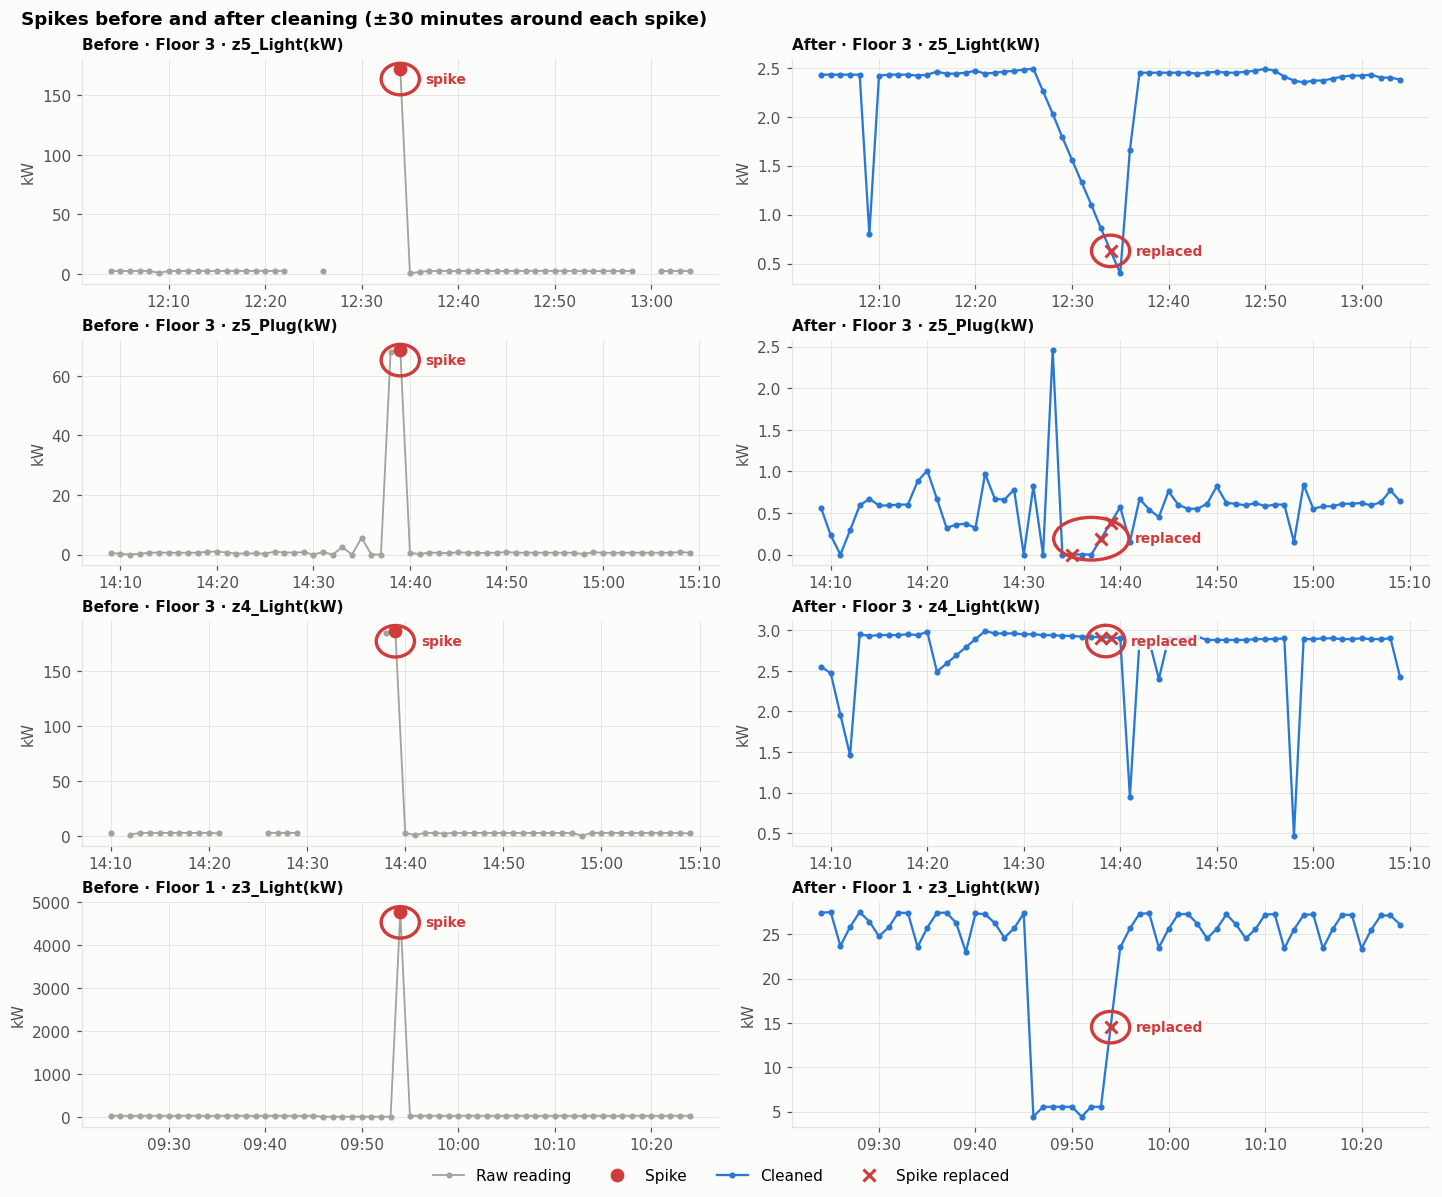

In [67]:
fig, axes = plt.subplots(len(closeups), 2, figsize=(13, 2.7 * len(closeups)), layout="constrained")
for r, row in enumerate(closeups.itertuples()):
    draw_closeup(axes[r, 0], row, raw)
    draw_closeup(axes[r, 1], row, raw, clean)
    axes[r, 0].set_title(f"Before · Floor {row.floor} · {row.column}", fontsize=10)
    axes[r, 1].set_title(f"After · Floor {row.floor} · {row.column}", fontsize=10)
    t = mdates.date2num(row.max_at)
    one_min = 1 / 1440
    circle(axes[r, 0], t - one_min, t + one_min, row.max * 0.9, row.max, label="spike", side="right", min_w=0.06, min_h=0.14)
    before_w = window(raw[row.floor][row.column], row.max_at)
    after_w = window(clean[row.floor][row.column], row.max_at)
    replaced = after_w[(before_w != after_w) & before_w.notna()]
    circle(axes[r, 1], mdates.date2num(replaced.index.min()) - one_min, mdates.date2num(replaced.index.max()) + one_min,
           replaced.min(), replaced.max(), label="replaced", side="right", min_w=0.06, min_h=0.14)
handles = axes[0, 0].get_legend_handles_labels()
handles_after = axes[0, 1].get_legend_handles_labels()
fig.legend(handles[0] + handles_after[0], handles[1] + handles_after[1], loc="outside lower center", ncols=4)
fig.suptitle("Spikes before and after cleaning (±30 minutes around each spike)", x=0.01, ha="left", fontweight="bold")
save(fig, "9_5_spike_closeups_side_by_side"); plt.show()

**Compared side by side:**

- **Before:** each spike towers over an otherwise flat line.
- **After:** the series continue smoothly at their normal level. A red circle and ✕ mark each value replaced by interpolation, and the new value sits in line with its neighbours.

### 9.6 Temperature

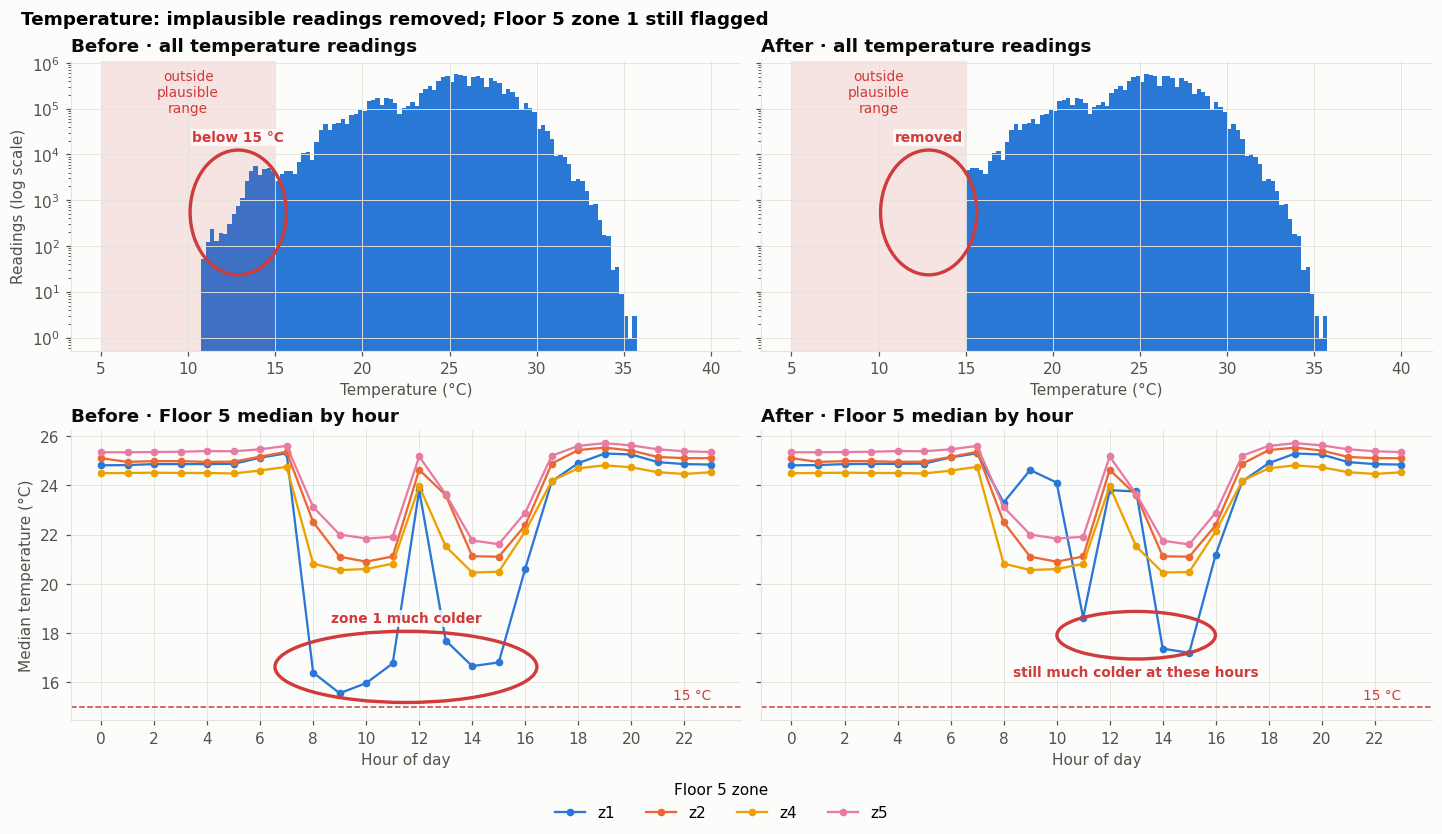

In [68]:
counts_before, counts_after = env_counts(raw), env_counts(clean)
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharey="row", layout="constrained")
draw_env(axes[0, 0], counts_before, "degC"); axes[0, 0].set_title("Before · all temperature readings")
draw_env(axes[0, 1], counts_after, "degC"); axes[0, 1].set_title("After · all temperature readings")
axes[0, 0].set_ylabel("Readings (log scale)")
draw_floor5_temperature(axes[1, 0], raw[5]); axes[1, 0].set_title("Before · Floor 5 median by hour")
draw_floor5_temperature(axes[1, 1], clean[5]); axes[1, 1].set_title("After · Floor 5 median by hour")
axes[1, 1].set_ylabel("")
fig.legend(*axes[1, 0].get_legend_handles_labels(), title="Floor 5 zone", loc="outside lower center", ncols=4)
edges = ENV_BINS["degC"][:-1]
low_counts = counts_before["degC"][edges < VALID_RANGE["degC"][0]]
low_edges = edges[edges < VALID_RANGE["degC"][0]][low_counts > 0]
box = (low_edges.min(), VALID_RANGE["degC"][0], low_counts[low_counts > 0].min(), low_counts.max())
circle(axes[0, 0], *box, label="below 15 °C")
circle(axes[0, 1], *box, label="removed")
# circle the hours when zone 1 is more than 2 °C colder than the other zones' average
for ax, frame, label, side in [(axes[1, 0], raw[5], "zone 1 much colder", "above"),
                               (axes[1, 1], clean[5], "still much colder at these hours", "below")]:
    temps = frame[cols_of(frame, "Temperature")].loc["2019-03-15":]
    hourly = temps.groupby(temps.index.hour).median()
    others = hourly.drop(columns="z1_S1(degC)").mean(axis=1)
    cold = hourly.loc[hourly["z1_S1(degC)"] < others - 2, "z1_S1(degC)"]
    circle(ax, cold.index.min() - 0.3, cold.index.max() + 0.3, cold.min(), cold.max(), label=label, side=side)
fig.suptitle("Temperature: implausible readings removed; Floor 5 zone 1 still flagged", x=0.01, ha="left", fontweight="bold")
save(fig, "9_6_temperature_side_by_side"); plt.show()

**Compared side by side:**

- **All readings (top row):** the circled bars below 15 °C are gone after cleaning, and the rest of the distribution is unchanged.
- **Floor 5 zone 1 (bottom row):** the circles mark the hours when zone 1 is more than 2 °C colder than the other zones. Its office-hours dip no longer goes below 15 °C, but it still reads colder than the other zones. That is why the sensor stays flagged as unreliable (6.5).

### 9.7 Unusual operation is preserved

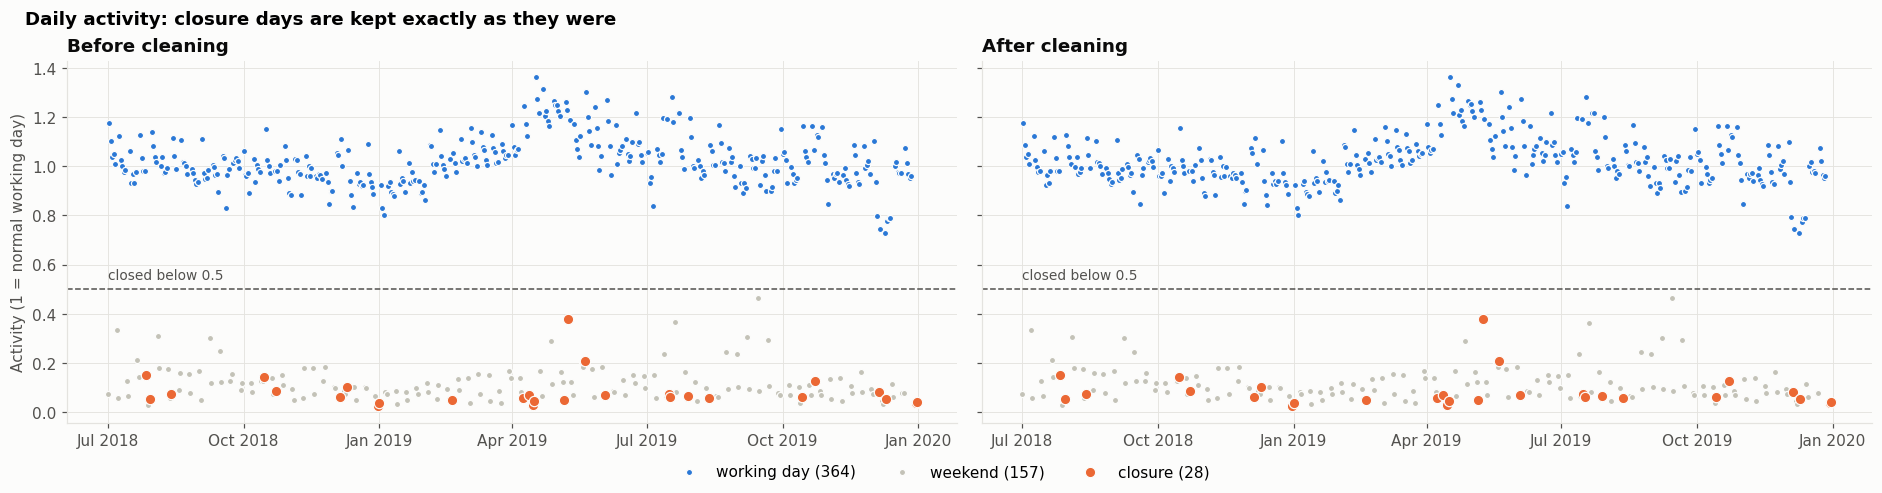

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4), sharey=True, layout="constrained")
for ax, days, title in [(axes[0], day_info, "Before cleaning"), (axes[1], day_info_after, "After cleaning")]:
    draw_activity(ax, days)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.set_title(title)
axes[1].set_ylabel("")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=3)
fig.suptitle("Daily activity: closure days are kept exactly as they were", x=0.01, ha="left", fontweight="bold")
save(fig, "9_7_activity_side_by_side"); plt.show()

**Compared side by side:** the two charts are practically identical. Every closure day (orange) is still there, at the same level. **There are no red circles here because nothing changed**, and that is the result we want. The cleaning removed the most likely recording errors but left real, unusual operation untouched, which is the *"not every unusual row is bad"* principle, verified visually as well as by the automated check in 6.7.

**Overall:** the cleaning makes many small repairs and a few targeted removals. It never invents data for long outages, and it never deletes real behaviour.